# **Crime Pattern Analysis & Prediction**

### **Data Merging (Do not Run!)**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
main_df = pd.read_csv('/content/Crime_Data_from_2020_to_Present 2.csv')
#main_df.head()

In [ ]:
sdoh_df = pd.read_csv('/content/CSV CHP Theme 2 - Social Determinants of Health - Data.csv')
#sdoh_df.head()

In [ ]:
behave_df = pd.read_csv('/content/Excel CHP Theme 9 - Behavioral Health - Metadata and Data.csv')
#behave_df.head()

In [ ]:
safety_df = pd.read_csv('/content/Excel CHP Theme 6 - Community Safety - Metadata and Data.csv')
#safety_df.head()

In [ ]:
demo_df = pd.read_csv('/content/CSV CHP Theme 1 - Demographics - Data.csv')
#demo_df.head()

In [ ]:
physical_df = pd.read_csv('/content/CSV CHP Theme 3 - Physical Activity and Nutrition - Data.csv')
#physical_df.head()

In [ ]:
health_df = pd.read_csv('/content/CSV CHP Theme 11 - Healthcare Access - Data.csv')
#health_df.head()

In [ ]:
housing_df = pd.read_csv('/content/CSV CHP Theme 5 - Housing and Health - Data.csv')
#housing_df.head()

In [ ]:
demo = [
    'Geography_Name','Pop_Total','Pop_age_0_17','Pop_age_18_64', 'Pop_age_65plus','Pop_race_ethnicity_pct_L','Pop_race_ethnicity_pct_W',
    'Pop_race_ethnicity_pct_B','Pop_race_ethnicity_pct_A','Pop_race_ethnicity_pct_I','Pop_race_ethnicity_pct_P','Foreign_B'
]

physical = ['Geography_Name','POP_FI','Adult_FI','Child_FI','Adult_NI']
housing = ['Geography_Name','SevHouse_B','Overcrowding','S_Overcrowding','Homeless','Home_Own','Home_Rent']
health = ['Geography_Name','Diff_medical_C']

In [ ]:
#merging 7 datasets aacording to features needed

merged_df = pd.merge(sdoh_df, behave_df, on='Geography_Name')
merged_df = pd.merge(safety_df,merged_df, on='Geography_Name')
merged_df = pd.merge(demo_df[demo],merged_df, on='Geography_Name')
merged_df = pd.merge(physical_df[physical],merged_df, on='Geography_Name')
merged_df = pd.merge(housing_df[housing],merged_df, on='Geography_Name')
merged_df = pd.merge(health_df[health],merged_df, on='Geography_Name')

merged_df = merged_df.loc[:, ~merged_df.columns.str.endswith(('_x', '_y'))]

merged_df.head()

In [ ]:
la_df = merged_df[merged_df['Geography_Type'].str.contains('Los Angeles City Neighborhood')]
#la_df.head()

In [ ]:
la_df.info()

In [ ]:
null_counts = la_df.isnull().sum().sort_values(ascending=False)
print(null_counts)

In [ ]:
#for i, column in enumerate(la_df.columns, 1):
#    print(f"{i}. {column}")

In [ ]:
# dropping features
df_clean = la_df.dropna(thresh=len(la_df)*0.5, axis=1)

df_clean = df_clean.loc[:, ~df_clean.columns.str.endswith(('UCL','LCL','RSE','EST'))]

df_clean.drop(columns=['Voting','Preschool','Grade3_Eng','Grade3_Math',' #','Geo_ID','Geo_Feature','Geography_Type'])


In [ ]:
for i, column in enumerate(df_clean.columns, 1):
    print(f"{i}. {column}")

In [ ]:
null_counts = df_clean.isnull().sum().sort_values(ascending=False)
print(null_counts)

In [ ]:
df_clean.to_csv('la_crime_data.csv', index=False)

#### creating new column representing the area of the crime

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = 'Crime_Data_from_2020_to_Present_20250416.csv'
df = pd.read_csv(file_path)

# Define neighborhood centroids (Latitude, Longitude) with full "Los Angeles - " prefix
neighborhoods = {
    "Los Angeles - Arleta": (34.2366, -118.4398),
    "Los Angeles - Baldwin Hills": (34.0169, -118.3616),
    "Los Angeles - Boyle Heights": (34.0339, -118.2054),
    "Los Angeles - Brentwood": (34.0520, -118.4737),
    "Los Angeles - Canoga Park": (34.2011, -118.5981),
    "Los Angeles - Central": (34.0259, -118.2422),
    "Los Angeles - Century Palms/Cove": (34.0083, -118.2486),
    "Los Angeles - Chatsworth": (34.2573, -118.6018),
    "Los Angeles - Del Rey": (34.0061, -118.4324),
    "Los Angeles - Downtown": (34.0522, -118.2437),
    "Los Angeles - Eagle Rock": (34.1413, -118.1985),
    "Los Angeles - East Hollywood": (34.0928, -118.2927),
    "Los Angeles - El Sereno": (34.0794, -118.1878),
    "Los Angeles - Encino": (34.1600, -118.5009),
    "Los Angeles - Exposition Park": (34.0166, -118.2884),
    "Los Angeles - Florence-Firestone": (33.9736, -118.2449),
    "Los Angeles - Glassell Park": (34.1168, -118.2269),
    "Los Angeles - Granada Hills": (34.2889, -118.5006),
    "Los Angeles - Green Meadows": (33.9375, -118.2456),
    "Los Angeles - Harbor City": (33.7970, -118.2991),
    "Los Angeles - Harbor Gateway": (33.9144, -118.3024),
    "Los Angeles - Harvard Park": (34.0036, -118.3019),
    "Los Angeles - Highland Park": (34.1147, -118.1945),
    "Los Angeles - Hollywood": (34.0928, -118.3287),
    "Los Angeles - Hollywood Hills": (34.1184, -118.3254),
    "Los Angeles - Hyde Park": (33.9756, -118.3289),
    "Los Angeles - Koreatown": (34.0578, -118.3008),
    "Los Angeles - Lake Balboa": (34.1970, -118.4909),
    "Los Angeles - Lincoln Heights": (34.0696, -118.2093),
    "Los Angeles - Little Bangladesh": (34.0549, -118.3026),
    "Los Angeles - Los Feliz": (34.1158, -118.2879),
    "Los Angeles - Mar Vista": (34.0033, -118.4334),
    "Los Angeles - Melrose": (34.0836, -118.3408),
    "Los Angeles - Mission Hills": (34.2619, -118.4606),
    "Los Angeles - Mt. Washington": (34.1045, -118.2095),
    "Los Angeles - North Hills": (34.2358, -118.4848),
    "Los Angeles - North Hollywood": (34.1726, -118.3789),
    "Los Angeles - Northridge": (34.2286, -118.5367),
    "Los Angeles - Pacoima": (34.2606, -118.4292),
    "Los Angeles - Palms": (34.0319, -118.4011),
    "Los Angeles - Panorama City": (34.2257, -118.4487),
    "Los Angeles - Pico-Union": (34.0468, -118.2814),
    "Los Angeles - Porter Ranch": (34.2746, -118.5412),
    "Los Angeles - Reseda": (34.2011, -118.5365),
    "Los Angeles - San Pedro": (33.7373, -118.2923),
    "Los Angeles - Sherman Oaks": (34.1511, -118.4493),
    "Los Angeles - Silverlake": (34.0867, -118.2702),
    "Los Angeles - South Park": (34.0402, -118.2644),
    "Los Angeles - Studio City": (34.1436, -118.3931),
    "Los Angeles - Sun Valley": (34.2175, -118.3704),
    "Los Angeles - Sylmar": (34.3077, -118.4470),
    "Los Angeles - Tarzana": (34.1722, -118.5449),
    "Los Angeles - Temple-Beaudry": (34.0594, -118.2669),
    "Los Angeles - Tujunga": (34.2516, -118.2854),
    "Los Angeles - University Park": (34.0296, -118.2786),
    "Los Angeles - Valley Glen": (34.1899, -118.4495),
    "Los Angeles - Valley Village": (34.1666, -118.3984),
    "Los Angeles - Van Nuys": (34.1899, -118.4514),
    "Los Angeles - Venice": (33.9931, -118.4807),
    "Los Angeles - Vermont Vista": (33.9733, -118.2914),
    "Los Angeles - Vernon Central": (34.0236, -118.2564),
    "Los Angeles - Watts": (33.9404, -118.2422),
    "Los Angeles - West Adams": (34.0329, -118.3317),
    "Los Angeles - West Hills": (34.1973, -118.6438),
    "Los Angeles - West Los Angeles": (34.0436, -118.4415),
    "Los Angeles - West Vernon": (34.0036, -118.2789),
    "Los Angeles - Westchester": (33.9561, -118.4003),
    "Los Angeles - Westlake": (34.0556, -118.2744),
    "Los Angeles - Westwood": (34.0635, -118.4455),
    "Los Angeles - Wholesale District": (34.0345, -118.2386),
    "Los Angeles - Wilmington": (33.7890, -118.2617),
    "Los Angeles - Wilshire Center": (34.0614, -118.2942),
    "Los Angeles - Winnetka": (34.2139, -118.5713),
    "Los Angeles - Woodland Hills": (34.1683, -118.6059)
}

# Function to find the closest neighborhood for a given (LAT, LON)
def find_nearest_neighborhood(lat, lon):
    if pd.isna(lat) or pd.isna(lon):
        return None
    min_distance = float('inf')
    nearest_neighborhood = None
    for neighborhood, (neigh_lat, neigh_lon) in neighborhoods.items():
        distance = (lat - neigh_lat)**2 + (lon - neigh_lon)**2  # Squared Euclidean distance (no sqrt for efficiency)
        if distance < min_distance:
            min_distance = distance
            nearest_neighborhood = neighborhood
    return nearest_neighborhood

# Apply the function to each row to assign the nearest neighborhood
df['Nearest_Neighborhood'] = df.apply(lambda row: find_nearest_neighborhood(row['LAT'], row['LON']), axis=1)

# Save the updated dataset (optional)
output_path = 'Crime_Data_with_Neighborhoods.csv'
df.to_csv(output_path, index=False)

#print("Neighborhood assignment completed. Output saved to:", output_path)

FileNotFoundError: [Errno 2] No such file or directory: 'Crime_Data_from_2020_to_Present_20250416.csv'

#### Merging the crime dataset with the neighborhood description

In [ ]:
import pandas as pd

# Load the datasets
crime_with_neighborhoods = pd.read_csv('Crime_Data_with_Neighborhoods.csv')
la_crime_data = pd.read_csv('la_crime_data (3).csv')

# Ensure the neighborhood columns match (case-sensitive)
#print("Sample from Crime_Data_with_Neighborhoods:", crime_with_neighborhoods['Nearest_Neighborhood'].unique()[:5])
#print("Sample from la_crime_data:", la_crime_data['Geography_Name'].unique()[:5])

# Merge the datasets on Nearest_Neighborhood (Crime_Data) and Geography Name (la_crime_data)
merged_data = pd.merge(
    crime_with_neighborhoods,
    la_crime_data,
    left_on='Nearest_Neighborhood',
    right_on='Geography_Name',
    how='left'  # Use 'inner' if you only want matching rows
)

# Save the merged dataset
merged_data.to_csv('Merged_Crime_Data_LA.csv', index=False)

#print("Merging completed. Output saved to 'Merged_Crime_Data_LA.csv'")
#print("Merged columns:", merged_data.columns.tolist())

## **Pre-Processing**

#### load data

In [ ]:
import pandas as pd
import dask.dataframe as dd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from scipy.stats import zscore
from google.colab import drive

In [ ]:
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
#dataset_path = "/content/DM data.csv"
dataset_path = "/content/drive/MyDrive/Merged_Crime_Data_LA.csv"

In [ ]:
import pandas as pd
#data = pd.read_csv(dataset_path)
#data = pd.read_csv('/content/Merged_Crime_Data_LA.csv.crdownload')
#dataset_path = "/content/drive/MyDrive/CSV/Merged_Crime_Data_LA.csv"

In [ ]:
import pandas as pd
data = pd.read_csv(dataset_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
.print("Data Overview:")
print(data.head())  # Preview the first few rows
print("\nData Info:")
print(data.info())  # Get information about the dataset
print("\nSummary Statistics:")
print(data.describe())  # Compute summary statistics

Data Overview:
       DR_NO               Date Rptd                DATE OCC  TIME OCC  AREA  \
0  190326475  03/01/2020 12:00:00 AM  03/01/2020 12:00:00 AM      2130     7   
1  200106753  02/09/2020 12:00:00 AM  02/08/2020 12:00:00 AM      1800     1   
2  200320258  11/11/2020 12:00:00 AM  11/04/2020 12:00:00 AM      1700     3   
3  200907217  05/10/2023 12:00:00 AM  03/10/2020 12:00:00 AM      2037     9   
4  200412582  09/09/2020 12:00:00 AM  09/09/2020 12:00:00 AM       630     4   

    AREA NAME  Rpt Dist No  Part 1-2  Crm Cd  \
0    Wilshire          784         1     510   
1     Central          182         1     330   
2   Southwest          356         1     480   
3    Van Nuys          964         1     343   
4  Hollenbeck          413         1     510   

                                Crm Cd Desc  ... Voting  SE_Support  \
0                          VEHICLE - STOLEN  ...   63.4        51.8   
1                     BURGLARY FROM VEHICLE  ...   52.0        49.8   
2 

**Feature Engineering**

In [ ]:
crime_code = ['Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4']

data['Crime_Codes'] = data[crime_code].notna().sum(axis=1)

In [ ]:
print(data['Crime_Codes'].value_counts().sort_index())

Crime_Codes
1    936050
2     66834
3      2250
4        64
Name: count, dtype: int64


**Dropping Features**

In [ ]:
columns_to_drop = [
    'DR_NO','Mocodes','LOCATION','Cross Street','Geography_Name', 'Geography_Type', 'Geo_Feature',' #', 'Geo_ID','Crm Cd 1',
    'Crm Cd 2','Crm Cd 3','Crm Cd 4','Grade3_Eng','Grade3_Math','Preschool','Alcohol_Offp','Alcohol_Onp','Marij_Outlet','Voting','Premis Cd','Premis Desc'
]
data = data.drop(columns=columns_to_drop)

**Missing Values**

In [ ]:
null_counts = data.isnull().sum()
print("Null values per column:")
print(null_counts[null_counts > 0])  # Only show columns with missing values

Null values per column:
Vict Sex          144782
Vict Descent      144794
Weapon Used Cd    677918
Weapon Desc       677918
Status                 1
Overcrowding       16935
S_Overcrowding     76880
Homeless          178671
LE_birth          105964
Edu_LessHS_Pct     10764
m_Overdose_MR     126192
dtype: int64


In [ ]:
# Calculate Missing Value Percentages
missing_percentages = data.isnull().mean() * 100
# Display columns with their missing value percentages
print("Missing Value Percentages:")
print(missing_percentages.sort_values(ascending=False))
# Identify Columns with More Than 55% Missing Values
threshold = 60
columns_to_drop = missing_percentages[missing_percentages > threshold].index.tolist()
print(f"\nColumns to Drop (>{threshold}% Missing Values):")
print(columns_to_drop)
# Drop Columns with High Missing Values
#data_cleaned = data.drop(columns=columns_to_drop)


Missing Value Percentages:
Weapon Used Cd    67.441240
Weapon Desc       67.441240
Homeless          17.774707
Vict Descent      14.404525
Vict Sex          14.403331
                    ...    
SE_Support         0.000000
Binge_Drink        0.000000
Marij_C            0.000000
Depression         0.000000
Crime_Codes        0.000000
Length: 73, dtype: float64

Columns to Drop (>60% Missing Values):
['Weapon Used Cd', 'Weapon Desc']


In [ ]:
#dropped features -unneeded ones

dropped = ['LE_birth','S_Overcrowding','m_Overdose_MR','Status','Status Desc','Edu_LessHS_Pct']
data = data.drop(columns=dropped)

In [ ]:
#fill NA with values

data['Weapon Used Cd']= data['Weapon Used Cd'].fillna(0)
data['Weapon Desc'] = data['Weapon Desc'].fillna('None')

data['Vict Descent']=data['Vict Descent'].fillna('Unknown')
data['Vict Sex']= data['Vict Sex'].fillna('Unknown')

data['Vict Age missing'] = data['Vict Age'].isnull().astype(int)
data['Vict Age']=data['Vict Age'].fillna(data['Vict Age'].median())


In [ ]:
#Missing Value Handling based on Area

area_stats = data.groupby('AREA')[['Overcrowding', 'Homeless']].mean()
area_stats = area_stats.sort_values('Overcrowding', ascending=False)
print(area_stats)

      Overcrowding     Homeless
AREA                           
2        26.128913  1167.895332
20       23.907987   521.562598
13       22.758752   408.479331
4        22.718981  1018.816902
18       20.689436   403.896057
16       19.394909   780.072308
1        18.933374  4138.316993
12       18.868735   264.600588
19       18.261553   270.716455
3        17.312053   145.210700
5        15.403948   473.718482
7        13.444772   316.368344
21       12.189221   257.681265
15       11.189789   411.294148
17       11.102380   217.557918
9        10.888394   307.277779
11       10.857760   284.439055
6        10.768417  1060.451977
10       10.334727   174.674486
8         4.187517   216.683825
14        3.422569   385.829954


In [ ]:
# Replace NaN values with the mean for each area
data['Overcrowding'] = data['Overcrowding'].fillna(data['AREA'].map(area_stats['Overcrowding']))
data['Homeless'] = data['Homeless'].fillna(data['AREA'].map(area_stats['Homeless']))

In [ ]:
# Missing Value Summary

null_counts = data.isnull().sum()
print("Null values per column:")
print(null_counts[null_counts > 0])  # Only show columns with missing values

Null values per column:
Series([], dtype: int64)


### Outliers

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
from scipy.stats.mstats import winsorize
from sklearn.preprocessing import FunctionTransformer


#### DeepScan: train & detect on existing DataFrame X

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(),
            nn.Linear(128, 64),          nn.ReLU(),
            nn.Linear(64, encoding_dim), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 64),  nn.ReLU(),
            nn.Linear(64, 128),           nn.ReLU(),
            nn.Linear(128, input_dim),
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


def deep_scan_outliers_df(
    X: pd.DataFrame,
    encoding_dim: int = 32,
    epochs: int = 30,
    batch_size: int = 256,
    contamination: float = 0.01
):

    # Select numeric columns only
    num_df = X.select_dtypes(include=[np.number]).copy()
    idx = num_df.index
    X_vals = num_df.values.astype(np.float32)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tensor = torch.from_numpy(X_vals)
    loader = DataLoader(TensorDataset(tensor, tensor), batch_size=batch_size, shuffle=True)

    # Build model
    model = Autoencoder(input_dim=X_vals.shape[1], encoding_dim=encoding_dim).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters())

    # Train
    for epoch in range(epochs):
        total_loss = 0.0
        for xb, _ in loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            recon = model(xb)
            loss = criterion(recon, xb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
        avg = total_loss / len(loader.dataset)
        print(f"Epoch {epoch+1}/{epochs} — loss: {avg:.4f}")

    # Compute reconstruction errors
    model.eval()
    with torch.no_grad():
        recon_all = model(tensor.to(device)).cpu().numpy()
    errors = np.mean((X_vals - recon_all)**2, axis=1)

    # Threshold & flag
    thresh = np.percentile(errors, 100 * (1 - contamination))
    is_out = errors > thresh

    # Annotate DataFrame
    X['recon_error'] = pd.Series(errors, index=idx)
    X['is_outlier'] = pd.Series(is_out, index=idx)

    return pd.Series(errors, index=idx, name='recon_error'), thresh

#### Plotting

In [ ]:
def plot_outlier_detection(errors: pd.Series, threshold: float):
    # Histogram of errors
    plt.figure()
    plt.hist(errors, bins=100)
    plt.axvline(threshold, linestyle='--', color='r', label=f"threshold={threshold:.2f}")
    plt.title("Reconstruction Error Distribution")
    plt.xlabel("Error")
    plt.ylabel("Count")
    plt.legend()
    plt.show()

    # Scatter of errors by index
    plt.figure()
    plt.scatter(errors.index, errors.values, s=5, alpha=0.5, label='All')
    out = errors[errors > threshold]
    plt.scatter(out.index, out.values, s=10, color='r', label=f'Outliers ({len(out)})')
    plt.axhline(threshold, linestyle='--', color='r')
    plt.title("Sample-wise Reconstruction Error")
    plt.xlabel("Index")
    plt.ylabel("Error")
    plt.legend()
    plt.show()

#### Analyse outliers

In [ ]:
def analyze_outliers(
    X: pd.DataFrame,
    violent_codes: list = None
) -> pd.DataFrame:
    out_df = X[X['is_outlier']].copy()
    print(f"Total outliers: {len(out_df)}\n")

#### Outlier counts per feature

In [ ]:
def print_feature_outlier_counts(X: pd.DataFrame, contamination: float = 0.01):
    outlier_mask = X['is_outlier']
    numeric_cols = X.select_dtypes(include=[np.number]).columns.drop(['recon_error'], errors='ignore')

    print("Outlier counts per feature (extreme values among detected outliers):\n")
    for col in numeric_cols:
        col_vals = X[col]
        lower_thresh = col_vals.quantile(contamination)
        upper_thresh = col_vals.quantile(1 - contamination)
        outliers_in_col = X.loc[outlier_mask, col].apply(lambda x: x < lower_thresh or x > upper_thresh)
        count = outliers_in_col.sum()
        print(f"{col}: {count} outliers")

Epoch 1/30 — loss: 1740064.8232
Epoch 2/30 — loss: 83392.5391
Epoch 3/30 — loss: 38047.1202
Epoch 4/30 — loss: 26125.5676
Epoch 5/30 — loss: 17824.7539
Epoch 6/30 — loss: 12139.2470
Epoch 7/30 — loss: 9507.1089
Epoch 8/30 — loss: 8329.4021
Epoch 9/30 — loss: 7187.2734
Epoch 10/30 — loss: 6871.8322
Epoch 11/30 — loss: 6091.9088
Epoch 12/30 — loss: 5741.0838
Epoch 13/30 — loss: 5388.6052
Epoch 14/30 — loss: 5176.3505
Epoch 15/30 — loss: 4913.6200
Epoch 16/30 — loss: 4415.6599
Epoch 17/30 — loss: 4329.9269
Epoch 18/30 — loss: 4164.4867
Epoch 19/30 — loss: 3923.7727
Epoch 20/30 — loss: 3788.3980
Epoch 21/30 — loss: 3735.3376
Epoch 22/30 — loss: 3536.4350
Epoch 23/30 — loss: 3238.9381
Epoch 24/30 — loss: 3052.9220
Epoch 25/30 — loss: 2907.4324
Epoch 26/30 — loss: 2817.4944
Epoch 27/30 — loss: 2736.0234
Epoch 28/30 — loss: 2712.6385
Epoch 29/30 — loss: 2645.7169
Epoch 30/30 — loss: 2571.0193


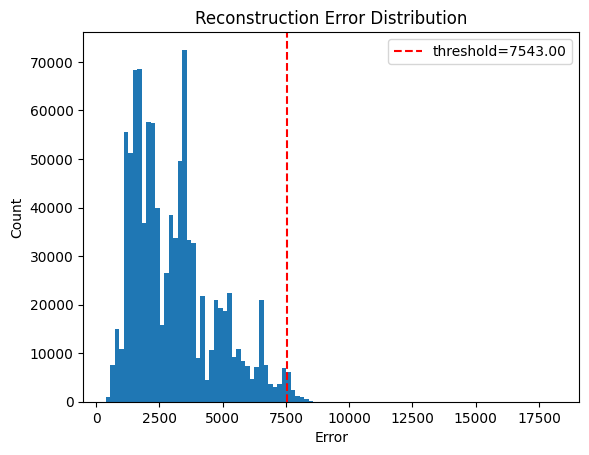

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


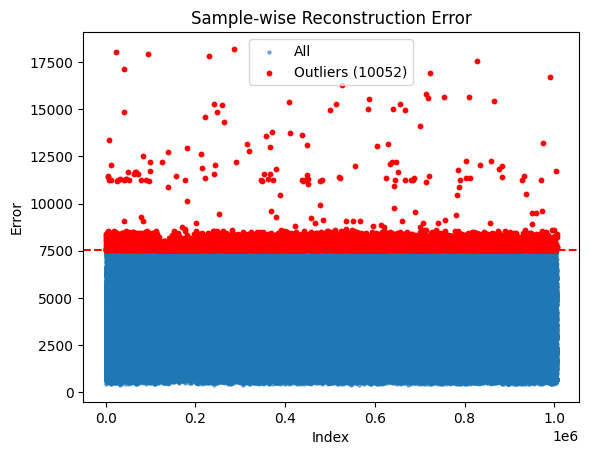

Outlier counts per feature (extreme values among detected outliers):

TIME OCC: 161 outliers
AREA: 0 outliers
Rpt Dist No: 3701 outliers
Part 1-2: 0 outliers
Crm Cd: 318 outliers
Vict Age: 184 outliers
Weapon Used Cd: 62 outliers
LAT: 66 outliers
LON: 1328 outliers
Diff_medical_C: 0 outliers
SevHouse_B: 170 outliers
Overcrowding: 0 outliers
Homeless: 0 outliers
Home_Own: 170 outliers
Home_Rent: 170 outliers
POP_FI: 0 outliers
Adult_FI: 0 outliers
Child_FI: 0 outliers
Adult_NI: 170 outliers
Pop_Total: 0 outliers
Pop_age_0_17: 0 outliers
Pop_age_18_64: 0 outliers
Pop_age_65plus: 0 outliers
Pop_race_ethnicity_pct_L: 0 outliers
Pop_race_ethnicity_pct_W: 92 outliers
Pop_race_ethnicity_pct_B: 0 outliers
Pop_race_ethnicity_pct_A: 0 outliers
Pop_race_ethnicity_pct_I: 0 outliers
Pop_race_ethnicity_pct_P: 0 outliers
Foreign_B: 0 outliers
NBHD_Safety: 170 outliers
Play_Place: 0 outliers
Crimes_m: 170 outliers
Overall_MR: 0 outliers
COVID_a: 0 outliers
Poor_health: 0 outliers
MHI: 0 outliers
100_F

In [ ]:
X= data
# DataFrame X loaded and preprocessed
errors, thresh = deep_scan_outliers_df(X, encoding_dim=32, epochs=30, contamination=0.01)
plot_outlier_detection(errors, thresh)
print_feature_outlier_counts(X, contamination=0.01)

In [ ]:


def log_transform(series):
    return np.log1p(series)

def handle_outliers(df):
    df = df.copy()
     # Remove rows where LAT and LON are 0
    df = df[(df['LAT'] != 0) | (df['LON'] != 0)]

    # 1. TIME OCC — Winsorize + Cyclical encode
    df['TIME OCC'] = winsorize(df['TIME OCC'], limits=[0.01, 0.01])
    df['TIME_OCC_sin'] = np.sin(2 * np.pi * df['TIME OCC'] / 2400)
    df['TIME_OCC_cos'] = np.cos(2 * np.pi * df['TIME OCC'] / 2400)

    # 2. Rpt Dist No — Impute mode
    mode_rpt = df['Rpt Dist No'].mode()[0]
    df['Rpt Dist No'] = df['Rpt Dist No'].fillna(mode_rpt)

    # 3. Crm Cd — Remove rare codes
    common_crmcd = df['Crm Cd'].value_counts()
    threshold = 10  # define minimum freq
    valid_crm = common_crmcd[common_crmcd > threshold].index
    df = df[df['Crm Cd'].isin(valid_crm)]

    # 4. Vict Age — Remove implausible ages
    df = df[(df['Vict Age'] >= 0) & (df['Vict Age'] <= 100)]

    # 5. Weapon Used Cd — Impute as "Unknown"
    df['Weapon Used Cd'] = df['Weapon Used Cd'].fillna(9999)

    # 6. SevHouse_B — Winsorize
    df['SevHouse_B'] = winsorize(df['SevHouse_B'], limits=[0, 0.01])

    # 7. Home_Own / Home_Rent — Winsorize
    for col in ['Home_Own', 'Home_Rent']:
        df[col] = winsorize(df[col], limits=[0, 0.01])

    # 8. Adult_NI — Log-transform
    df['Adult_NI'] = log_transform(df['Adult_NI'])

    # 9. Pop_Total — Log-transform
    df['Pop_Total'] = log_transform(df['Pop_Total'])

    # 10. Race percentages — Winsorize
    for col in ['Pop_race_ethnicity_pct_W', 'Pop_race_ethnicity_pct_B', 'Pop_race_ethnicity_pct_I']:
        df[col] = winsorize(df[col], limits=[0.01, 0.01])

    # 11. NBHD_Safety, Play_Place — Winsorize
    for col in ['NBHD_Safety', 'Play_Place']:
        df[col] = winsorize(df[col], limits=[0, 0.01])

    # 12. Crimes_m — Log-transform
    df['Crimes_m'] = log_transform(df['Crimes_m'])

    # 13. Poverty %, Edu_College_Pct — Winsorize
    for col in ['100_FPL_Pct', '200_FPL_Pct', 'Edu_College_Pct']:
        df[col] = winsorize(df[col], limits=[0.01, 0.01])

    # 14. 200_FPL_Child_Pop — Log-transform
    df['200_FPL_Child_Pop'] = log_transform(df['200_FPL_Child_Pop'])

    # 15. Binge_Drink / Marij_C / Depression — Winsorize
    for col in ['Binge_Drink', 'Marij_C', 'Depression']:
        df[col] = winsorize(df[col], limits=[0, 0.01])

    # 16. Crime_Codes — Remove rare codes
    crm_freq = df['Crime_Codes'].value_counts()
    valid_crm_codes = crm_freq[crm_freq > 5].index
    df = df[df['Crime_Codes'].isin(valid_crm_codes)]

    return df
df_clean = handle_outliers(X)

In [ ]:
# prompt: df_clean record numbers

print("Number of records in df_clean:", len(df_clean))

Number of records in df_clean: 1002705


Total outliers detected: 10052
Total non-outliers: 995146



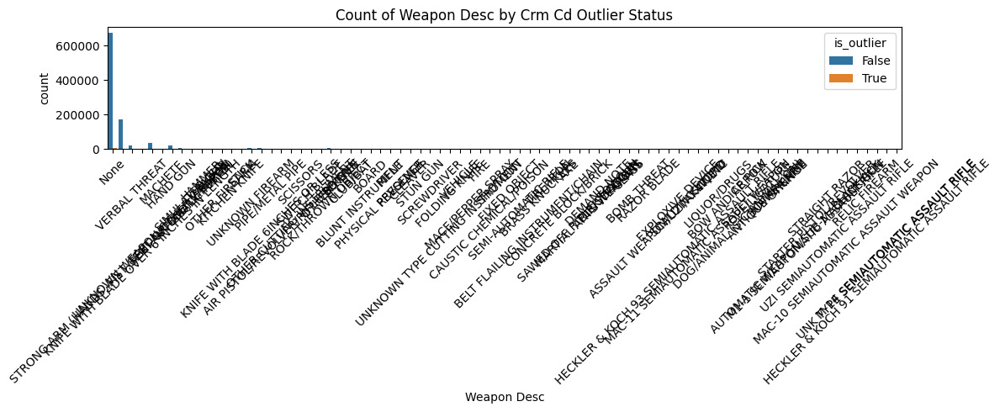

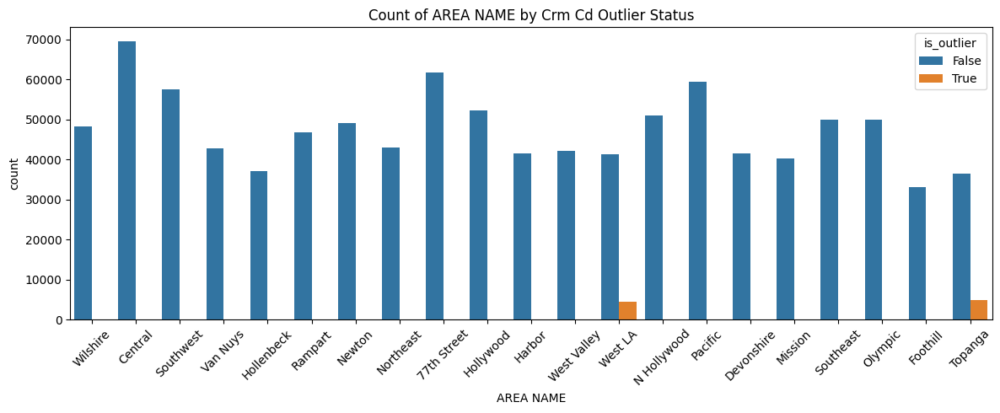

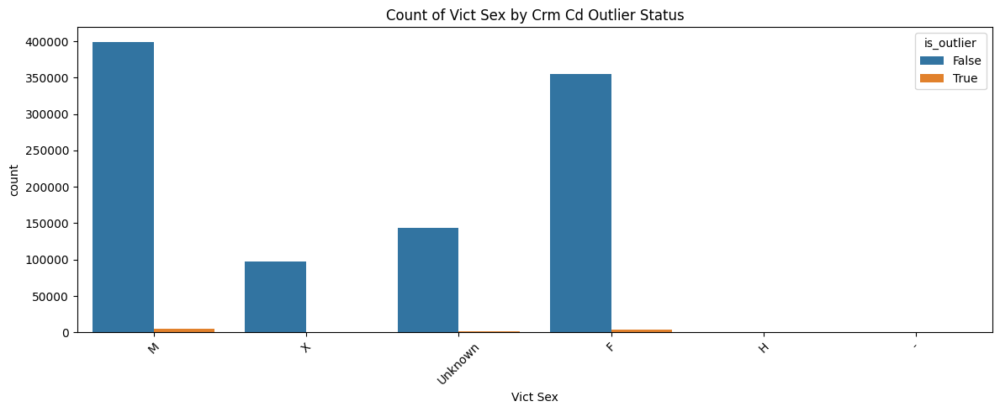

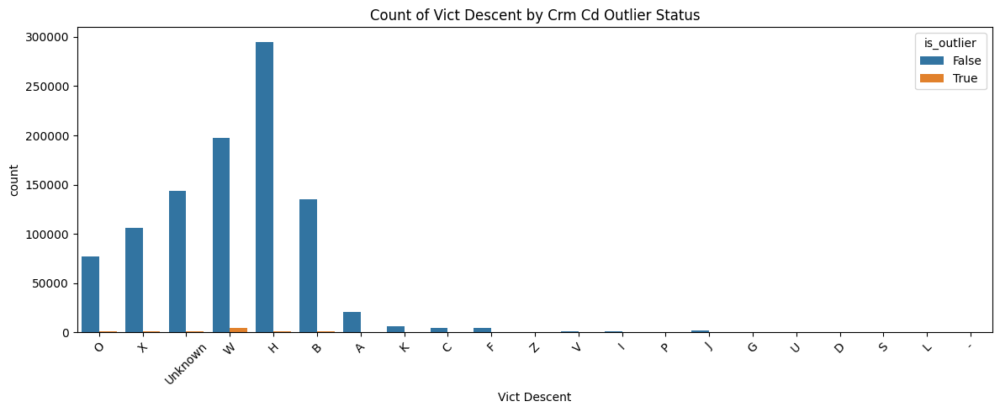

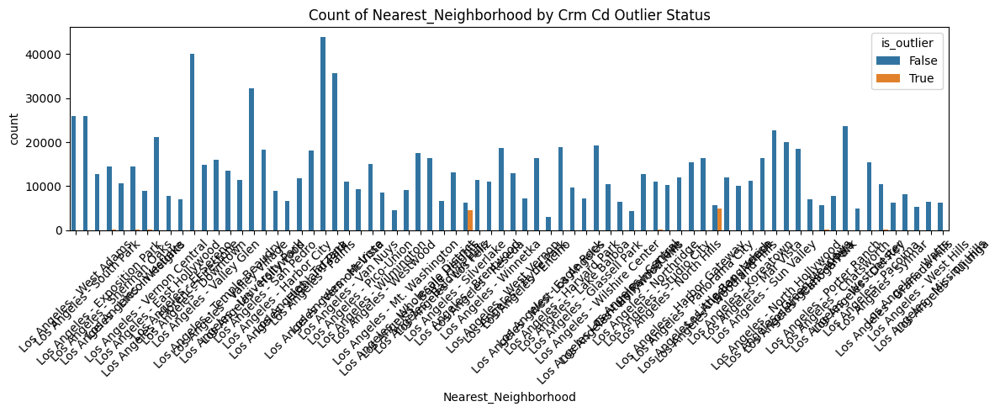

...

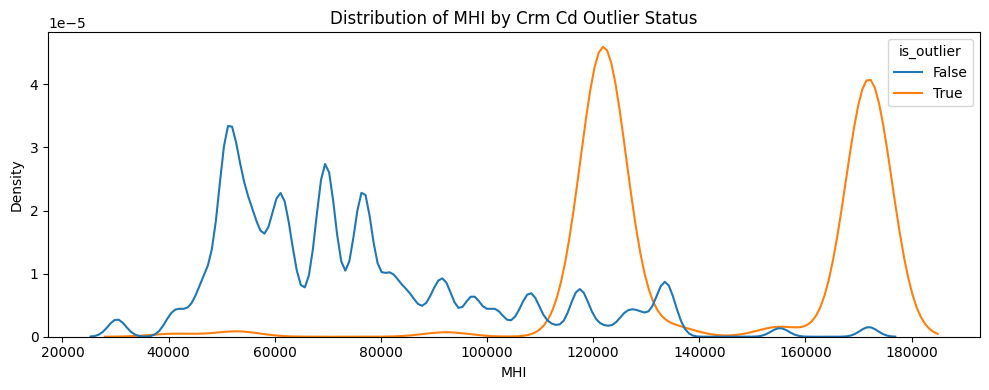

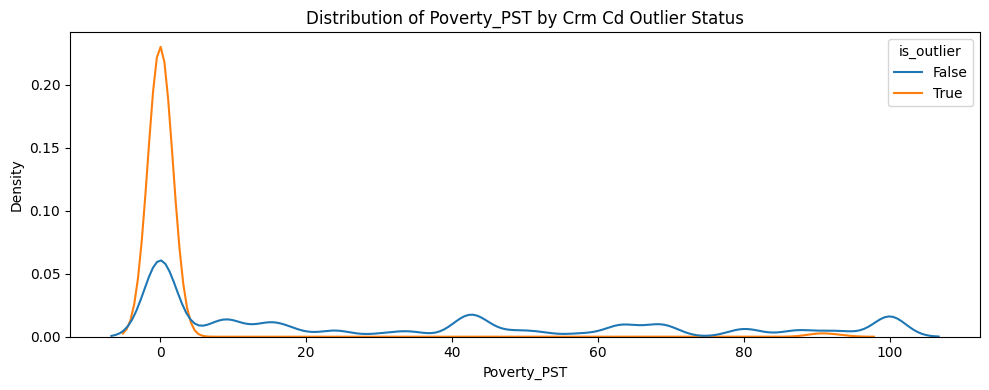

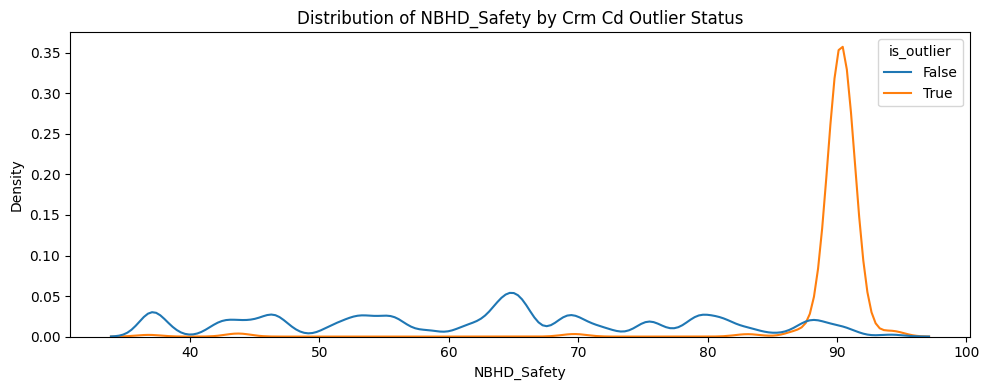

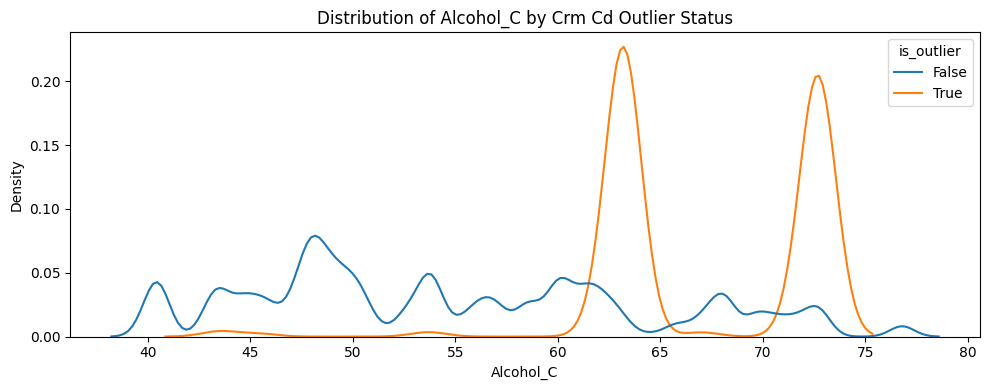

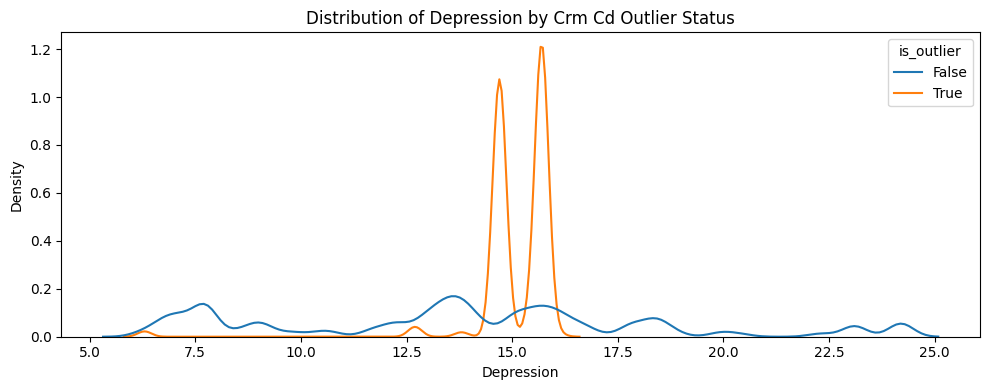

Top features positively correlated with outliers:

is_outlier                  1.000000
recon_error                 0.294255
MHI                         0.249871
SE_Support                  0.189381
Pop_race_ethnicity_pct_W    0.189022
NBHD_Safety                 0.169009
Edu_Bach_Pct                0.156407
Alcohol_C                   0.130866
Play_Place                  0.129936
Home_Own                    0.114702
Edu_Bach_Pop                0.114087
Pop_age_65plus              0.101770
Rpt Dist No                 0.065985
AREA                        0.064971
Weapon Used Cd              0.041708
Name: is_outlier, dtype: float64

Top features negatively correlated with outliers:

Foreign_B                  -0.132902
100_FPL_Child_Pct          -0.139331
Pop_race_ethnicity_pct_I   -0.139592
Edu_HSGrad_Pct             -0.141429
200_FPL_Pct                -0.141620
Poor_health                -0.143611
COVID_a                    -0.144386
Pop_race_ethnicity_pct_L   -0.155326
200_FPL_Child

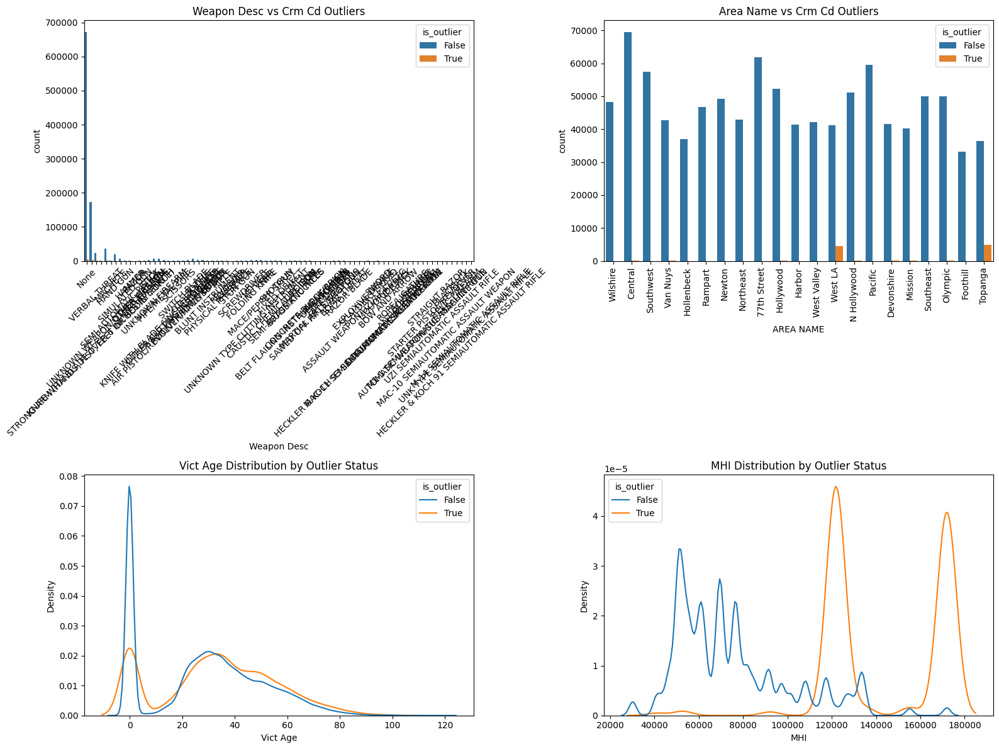

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind


# 1. Separate outliers and non-outliers
outliers_df = X[X['is_outlier']].copy()
non_outliers_df = X[~X['is_outlier']].copy()

print(f"Total outliers detected: {len(outliers_df)}")
print(f"Total non-outliers: {len(non_outliers_df)}\n")

# 2. Define categorical and numeric features to analyze
categorical_features = ['Weapon Desc', 'AREA NAME', 'Vict Sex', 'Vict Descent', 'Nearest_Neighborhood']
numeric_features = ['Vict Age', 'MHI', 'Poverty_PST', 'NBHD_Safety', 'Alcohol_C', 'Depression']

# 3. Plot categorical features impact
for cat_feat in categorical_features:
    plt.figure(figsize=(12,5))
    sns.countplot(data=X, x=cat_feat, hue='is_outlier')
    plt.title(f"Count of {cat_feat} by Crm Cd Outlier Status")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 4. Plot numeric features distribution differences
for num_feat in numeric_features:
    plt.figure(figsize=(10,4))
    sns.kdeplot(data=X, x=num_feat, hue='is_outlier', common_norm=False)
    plt.title(f"Distribution of {num_feat} by Crm Cd Outlier Status")
    plt.tight_layout()
    plt.show()

# 5. Correlation with outlier status for numeric features
corr_df = X.select_dtypes(include=[float, int]).copy()
corr_df['is_outlier'] = X['is_outlier'].astype(int)
corr_with_outlier = corr_df.corr()['is_outlier'].sort_values(ascending=False)

print("Top features positively correlated with outliers:\n")
print(corr_with_outlier.head(15))

print("\nTop features negatively correlated with outliers:\n")
print(corr_with_outlier.tail(15))

# 6. Statistical tests for categorical features (Chi-square test)
print("\nChi-square test p-values for categorical features vs outliers:")
for cat_feat in categorical_features:
    contingency_table = pd.crosstab(X[cat_feat], X['is_outlier'])
    chi2, p, dof, ex = chi2_contingency(contingency_table)
    print(f"{cat_feat}: p-value = {p:.4e}")

# 7. Statistical tests for numeric features (T-test)
print("\nT-test p-values for numeric features between outliers and non-outliers:")
for num_feat in numeric_features:
    outlier_vals = outliers_df[num_feat].dropna()
    non_outlier_vals = non_outliers_df[num_feat].dropna()
    stat, p = ttest_ind(outlier_vals, non_outlier_vals, equal_var=False)
    print(f"{num_feat}: p-value = {p:.4e}")

# 8. Optional: Combined feature impact visualization dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=X, x='Weapon Desc', hue='is_outlier', ax=axes[0,0])
axes[0,0].set_title("Weapon Desc vs Crm Cd Outliers")
axes[0,0].tick_params(axis='x', rotation=45)

sns.countplot(data=X, x='AREA NAME', hue='is_outlier', ax=axes[0,1])
axes[0,1].set_title("Area Name vs Crm Cd Outliers")
axes[0,1].tick_params(axis='x', rotation=90)

sns.kdeplot(data=X, x='Vict Age', hue='is_outlier', common_norm=False, ax=axes[1,0])
axes[1,0].set_title("Vict Age Distribution by Outlier Status")

sns.kdeplot(data=X, x='MHI', hue='is_outlier', common_norm=False, ax=axes[1,1])
axes[1,1].set_title("MHI Distribution by Outlier Status")

plt.tight_layout()
plt.show()

In [ ]:

outlier_crm_codes_df = df_clean[df_clean['is_outlier']].copy()

# Print the 'Crm Cd' and 'Crm Cd Desc' for the flagged outliers
print("Outlier Crime Codes ('Crm Cd') and Descriptions ('Crm Cd Desc'):")
# Check if 'Crm Cd Desc' exists, otherwise just print 'Crm Cd'
if 'Crm Cd Desc' in outlier_crm_codes_df.columns:
    print(outlier_crm_codes_df[['Crm Cd', 'Crm Cd Desc']])
else:
    print(outlier_crm_codes_df['Crm Cd'])


Outlier Crime Codes ('Crm Cd') and Descriptions ('Crm Cd Desc'):
         Crm Cd                                        Crm Cd Desc
57          624                           BATTERY - SIMPLE ASSAULT
165         442           SHOPLIFTING - PETTY THEFT ($950 & UNDER)
325         740  VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...
342         624                           BATTERY - SIMPLE ASSAULT
413         745           VANDALISM - MISDEAMEANOR ($399 OR UNDER)
...         ...                                                ...
1005016     745           VANDALISM - MISDEAMEANOR ($399 OR UNDER)
1005025     946                          OTHER MISCELLANEOUS CRIME
1005064     930             CRIMINAL THREATS - NO WEAPON DISPLAYED
1005093     624                           BATTERY - SIMPLE ASSAULT
1005104     946                          OTHER MISCELLANEOUS CRIME

[10050 rows x 2 columns]


In [ ]:
# It already contains 'recon_error' and 'is_outlier' columns
df_clean = df_clean.drop(columns=['recon_error', 'is_outlier'])

# Verify the columns are removed
print("\nColumns after dropping recon_error and is_outlier:")
df_clean.columns



Columns after dropping recon_error and is_outlier:


Index(['Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No',
       'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Vict Age', 'Vict Sex',
       'Vict Descent', 'Weapon Used Cd', 'Weapon Desc', 'LAT', 'LON',
       'Nearest_Neighborhood', 'Diff_medical_C', 'SevHouse_B', 'Overcrowding',
       'Homeless', 'Home_Own', 'Home_Rent', 'POP_FI', 'Adult_FI', 'Child_FI',
       'Adult_NI', 'Pop_Total', 'Pop_age_0_17', 'Pop_age_18_64',
       'Pop_age_65plus', 'Pop_race_ethnicity_pct_L',
       'Pop_race_ethnicity_pct_W', 'Pop_race_ethnicity_pct_B',
       'Pop_race_ethnicity_pct_A', 'Pop_race_ethnicity_pct_I',
       'Pop_race_ethnicity_pct_P', 'Foreign_B', 'NBHD_Safety', 'Play_Place',
       'Crimes_m', 'Overall_MR', 'COVID_a', 'Poor_health', 'MHI',
       '100_FPL_Pop', '100_FPL_Pct', '200_FPL_Pop', '200_FPL_Pct',
       '100_FPL_Child_Pop', '100_FPL_Child_Pct', '200_FPL_Child_Pop',
       '200_FPL_Child_Pct', 'Poverty_PST', 'Edu_LessHS_Pop', 'Edu_HSGrad_Pop',
       'Edu_College_Po

### **Datetime Conversion**

In [ ]:
data_cleaned = df_clean.copy()
data_cleaned['DATE OCC'] = pd.to_datetime(
    data_cleaned['DATE OCC'],
    format='%m/%d/%Y %I:%M:%S %p')

def convert_time_occ(time_val):
    try:
        # Handle all input types (int, float, string)
        time_str = str(int(float(time_val))).zfill(4)  # Ensure 4 digits
        time_str = time_str[-4:]  # Take last 4 digits in case of longer strings

        # Extract hours and minutes
        hour = int(time_str[:2])
        minute = int(time_str[2:])

        # Validate time components
        if hour >= 24 or minute >= 60:
            return None

        return f"{hour:02d}:{minute:02d}:00"
    except:
        return None

data_cleaned['TIME OCC'] = data_cleaned['TIME OCC'].apply(convert_time_occ)

data_cleaned['Year_OCC'] = data_cleaned['DATE OCC'].dt.year
data_cleaned['Month_OCC'] = data_cleaned['DATE OCC'].dt.month
data_cleaned['Day_OCC'] = data_cleaned['DATE OCC'].dt.day
data_cleaned['Weekday_OCC'] = data_cleaned['DATE OCC'].dt.day_name()

# Weekend

data_cleaned['Weekday_OCC'] = data_cleaned['Weekday_OCC'].isin(['Saturday', 'Sunday']).astype(int)
data_cleaned['Hour_OCC'] = pd.to_datetime(data_cleaned['TIME OCC'], format='%H:%M:%S').dt.hour

# Season
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

data_cleaned['Season_OCC'] = data_cleaned['Month_OCC'].apply(get_season)

# Shift
def get_shift(hour):
    if 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    elif 18 <= hour < 24:
        return 'Evening'
    else:
        return 'Night'

data_cleaned['Shift_OCC'] = data_cleaned['Hour_OCC'].apply(get_shift)

# Step 4: Verify the Results
print("\nMissing values after processing:")
print(data_cleaned[['TIME OCC', 'Hour_OCC', 'Weekday_OCC', 'Season_OCC', 'Shift_OCC']].isna().sum())

print("\nFirst 3 rows with new features:")
print(data_cleaned[[ 'DATE OCC', 'TIME OCC', 'Year_OCC', 'Month_OCC',
                   'Day_OCC', 'Weekday_OCC','Season_OCC', 'Shift_OCC']].head(3))


Missing values after processing:
TIME OCC       0
Hour_OCC       0
Weekday_OCC    0
Season_OCC     0
Shift_OCC      0
dtype: int64

First 3 rows with new features:
    DATE OCC  TIME OCC  Year_OCC  Month_OCC  Day_OCC  Weekday_OCC Season_OCC  \
0 2020-03-01  21:30:00      2020          3        1            1     Spring   
1 2020-02-08  18:00:00      2020          2        8            1     Winter   
2 2020-11-04  17:00:00      2020         11        4            0       Fall   

   Shift_OCC  
0    Evening  
1    Evening  
2  Afternoon  


In [ ]:
column_names = data_cleaned.columns.tolist()
print(column_names)

['Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Weapon Used Cd', 'Weapon Desc', 'LAT', 'LON', 'Nearest_Neighborhood', 'Diff_medical_C', 'SevHouse_B', 'Overcrowding', 'Homeless', 'Home_Own', 'Home_Rent', 'POP_FI', 'Adult_FI', 'Child_FI', 'Adult_NI', 'Pop_Total', 'Pop_age_0_17', 'Pop_age_18_64', 'Pop_age_65plus', 'Pop_race_ethnicity_pct_L', 'Pop_race_ethnicity_pct_W', 'Pop_race_ethnicity_pct_B', 'Pop_race_ethnicity_pct_A', 'Pop_race_ethnicity_pct_I', 'Pop_race_ethnicity_pct_P', 'Foreign_B', 'NBHD_Safety', 'Play_Place', 'Crimes_m', 'Overall_MR', 'COVID_a', 'Poor_health', 'MHI', '100_FPL_Pop', '100_FPL_Pct', '200_FPL_Pop', '200_FPL_Pct', '100_FPL_Child_Pop', '100_FPL_Child_Pct', '200_FPL_Child_Pop', '200_FPL_Child_Pct', 'Poverty_PST', 'Edu_LessHS_Pop', 'Edu_HSGrad_Pop', 'Edu_College_Pop', 'Edu_Bach_Pop', 'Edu_HSGrad_Pct', 'Edu_College_Pct', 'Edu_Bach_Pct', 'SE_Support', 'Alcohol_C', 'Bin

In [ ]:
data_cleaned.to_csv('preprocesseCrimeData.csv', index=False)

**The Five Number Summary**

In [ ]:
numeric_columns = data_cleaned.select_dtypes(include=[np.number]).columns
five_number_summary = data_cleaned[numeric_columns].describe().loc[['min', '25%', '50%', '75%', 'max']]
print("\nFive-Number Summary:")
print(five_number_summary)


Five-Number Summary:
     AREA  Rpt Dist No  Part 1-2  Crm Cd  Vict Age  Weapon Used Cd      LAT  \
min   1.0        101.0       1.0   110.0       0.0             0.0  33.7059   
25%   5.0        587.0       1.0   331.0       0.0             0.0  34.0153   
50%  11.0       1139.0       1.0   442.0      30.0             0.0  34.0592   
75%  16.0       1613.0       2.0   626.0      44.0           307.0  34.1649   
max  21.0       2199.0       2.0   956.0      99.0           516.0  34.3343   

          LON  Diff_medical_C  SevHouse_B  ...  Depression  Crime_Codes  \
min -118.6676            13.1        18.2  ...         6.2          1.0   
25% -118.4309            22.2        24.8  ...         9.8          1.0   
50% -118.3230            28.5        28.8  ...        13.8          1.0   
75% -118.2740            33.2        31.9  ...        16.1          1.0   
max -118.1554            41.8        40.0  ...        24.2          4.0   

     Vict Age missing  TIME_OCC_sin  TIME_OCC_cos  Y

**Feature Encoding**

In [ ]:
from sklearn.preprocessing import LabelEncoder

data_pred = data_cleaned.copy()
data_pred.columns = data_pred.columns.str.strip().str.lower()

# Convert object columns to category
for col in data_pred.select_dtypes(include='object').columns:
    data_pred[col] = data_pred[col].astype('category')

# Label encode all categorical columns
encoders = {}
for col in data_pred.select_dtypes(include='category').columns:
    le = LabelEncoder()
    data_pred[col] = le.fit_transform(data_pred[col].astype(str))
    encoders[col] = le

Data Transformation

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Select ONLY numeric features (exclude label-encoded categoricals)
numeric_columns = data_pred.select_dtypes(include=['int64', 'float64']).columns

# Initialize and fit scaler
scaler = MinMaxScaler()
data_pred[numeric_columns] = scaler.fit_transform(data_pred[numeric_columns])

# No need to concatenate – scaling is done in-place
print(data_pred.head())

   date rptd   date occ  time occ  area  area name  rpt dist no  part 1-2  \
0   0.183727 2020-03-01  0.914833  0.30       1.00     0.325548       0.0   
1   0.120735 2020-02-08  0.765791  0.00       0.05     0.038608       0.0   
2   0.866667 2020-11-04  0.723208  0.10       0.75     0.121544       0.0   
3   0.382677 2020-03-10  0.877218  0.40       0.85     0.411344       0.0   
4   0.701312 2020-09-09  0.276082  0.15       0.25     0.148713       0.0   

     crm cd  crm cd desc  vict age  ...  vict age missing  time_occ_sin  \
0  0.472813     0.958333  0.000000  ...               0.0      0.175276   
1  0.260047     0.133333  0.474747  ...               0.0      0.000000   
2  0.437352     0.066667  0.191919  ...               0.0      0.017037   
3  0.275414     0.758333  0.191919  ...               0.0      0.093196   
4  0.472813     0.958333  0.000000  ...               0.0      0.998459   

   time_occ_cos  year_occ  month_occ  day_occ  weekday_occ  hour_occ  \
0      0.88020

In [ ]:
print(data_cleaned.columns)

Index(['Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No',
       'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Vict Age', 'Vict Sex',
       'Vict Descent', 'Weapon Used Cd', 'Weapon Desc', 'LAT', 'LON',
       'Nearest_Neighborhood', 'Diff_medical_C', 'SevHouse_B', 'Overcrowding',
       'Homeless', 'Home_Own', 'Home_Rent', 'POP_FI', 'Adult_FI', 'Child_FI',
       'Adult_NI', 'Pop_Total', 'Pop_age_0_17', 'Pop_age_18_64',
       'Pop_age_65plus', 'Pop_race_ethnicity_pct_L',
       'Pop_race_ethnicity_pct_W', 'Pop_race_ethnicity_pct_B',
       'Pop_race_ethnicity_pct_A', 'Pop_race_ethnicity_pct_I',
       'Pop_race_ethnicity_pct_P', 'Foreign_B', 'NBHD_Safety', 'Play_Place',
       'Crimes_m', 'Overall_MR', 'COVID_a', 'Poor_health', 'MHI',
       '100_FPL_Pop', '100_FPL_Pct', '200_FPL_Pop', '200_FPL_Pct',
       '100_FPL_Child_Pop', '100_FPL_Child_Pct', '200_FPL_Child_Pop',
       '200_FPL_Child_Pct', 'Poverty_PST', 'Edu_LessHS_Pop', 'Edu_HSGrad_Pop',
       'Edu_College_Po

## EDA

### **Descriptive Analysis**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import statsmodels.api as sm

###**Crime Pattern Analysis**

1. Most Common Crime Types

<ipython-input-38-40b684b6c5f1>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_crimes.values, y=top_crimes.index, palette="viridis")


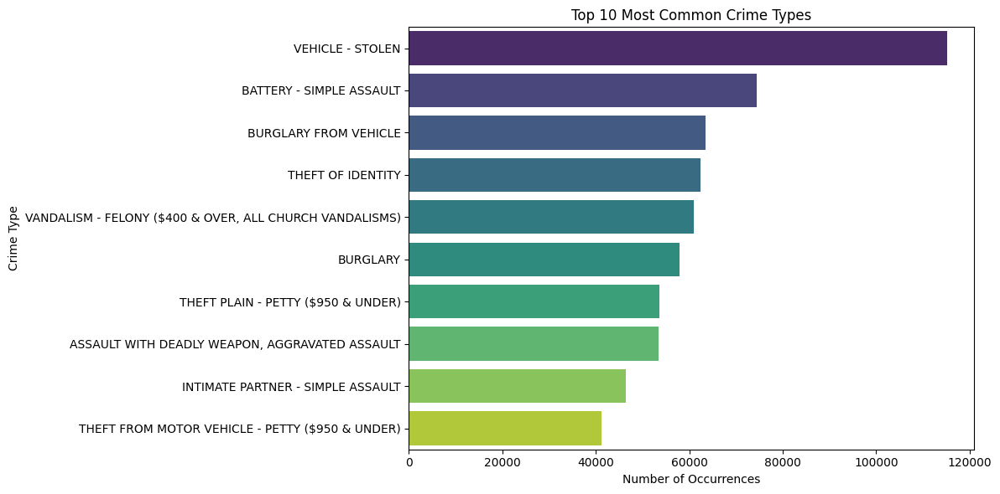

In [ ]:
# Top 10 Most Common Crime Types
top_crimes = data_cleaned['Crm Cd Desc'].value_counts().nlargest(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_crimes.values, y=top_crimes.index, palette="viridis")
plt.title("Top 10 Most Common Crime Types")
plt.xlabel("Number of Occurrences")
plt.ylabel("Crime Type")
plt.tight_layout()
plt.show()

2. High-Crime Neighborhoods

<ipython-input-39-2187bb26645b>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=crime_by_area.values, y=crime_by_area.index, palette="magma")


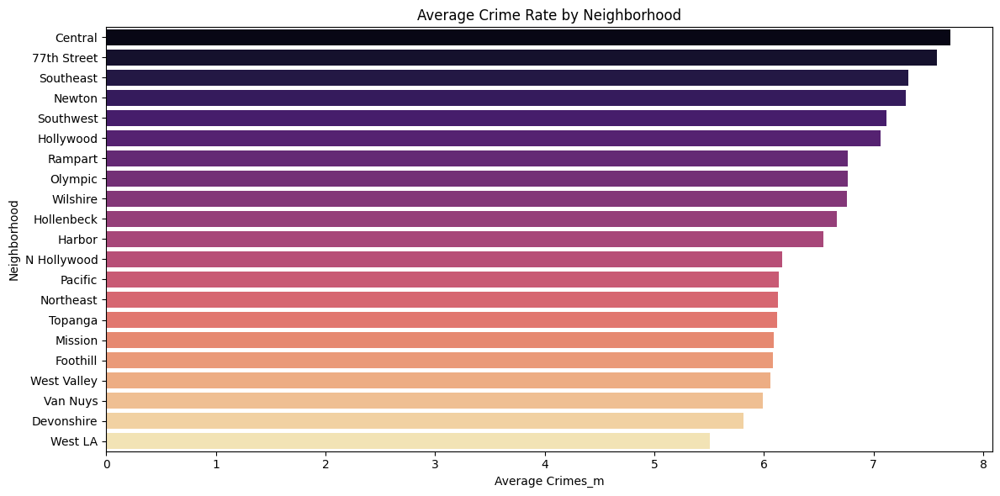

In [ ]:
# Mean Crimes per Neighborhood
crime_by_area = data_cleaned.groupby('AREA NAME')['Crimes_m'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=crime_by_area.values, y=crime_by_area.index, palette="magma")
plt.title("Average Crime Rate by Neighborhood")
plt.xlabel("Average Crimes_m")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

3. Temporal Trends

Time of Day (Shift)

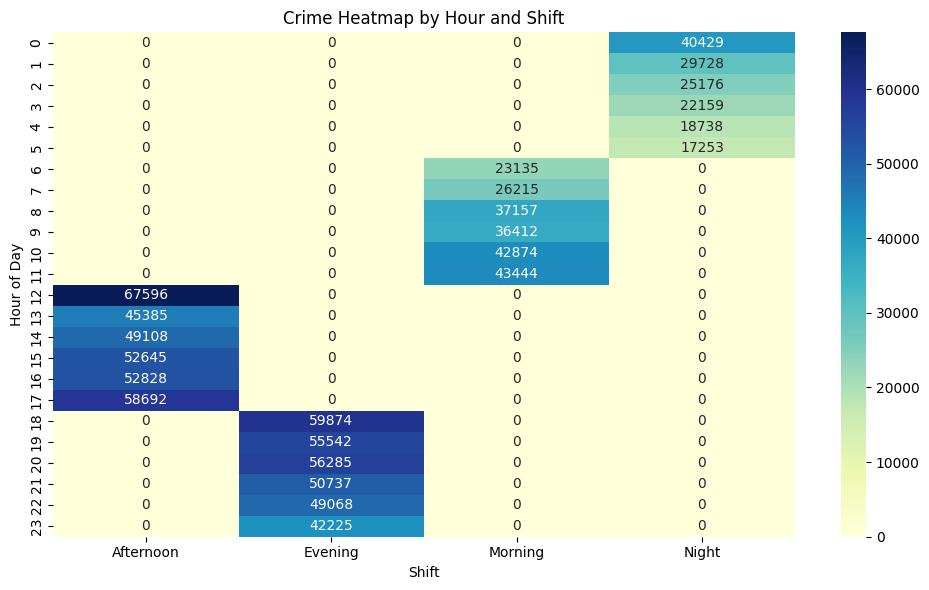

In [ ]:
# Count occurrences by Hour and Shift
heatmap_data = data_cleaned.groupby(['Hour_OCC', 'Shift_OCC']).size().unstack(fill_value=0)

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Crime Heatmap by Hour and Shift")
plt.xlabel("Shift")
plt.ylabel("Hour of Day")
plt.tight_layout()
plt.show()

Day of Week (Weekend vs. Weekday)

<ipython-input-41-a0c87d4a8bf4>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=day_labels, y=day_counts.values, palette="Set3")


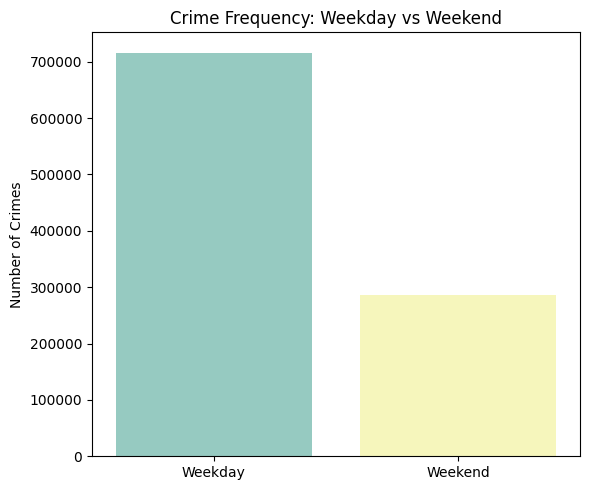

In [ ]:
# Note: 1 = Weekend, 0 = Weekday
day_counts = data_cleaned['Weekday_OCC'].value_counts().sort_index()
day_labels = ['Weekday', 'Weekend']

plt.figure(figsize=(6, 5))
sns.barplot(x=day_labels, y=day_counts.values, palette="Set3")
plt.title("Crime Frequency: Weekday vs Weekend")
plt.ylabel("Number of Crimes")
plt.tight_layout()
plt.show()

Monthly and Seasonal Trends

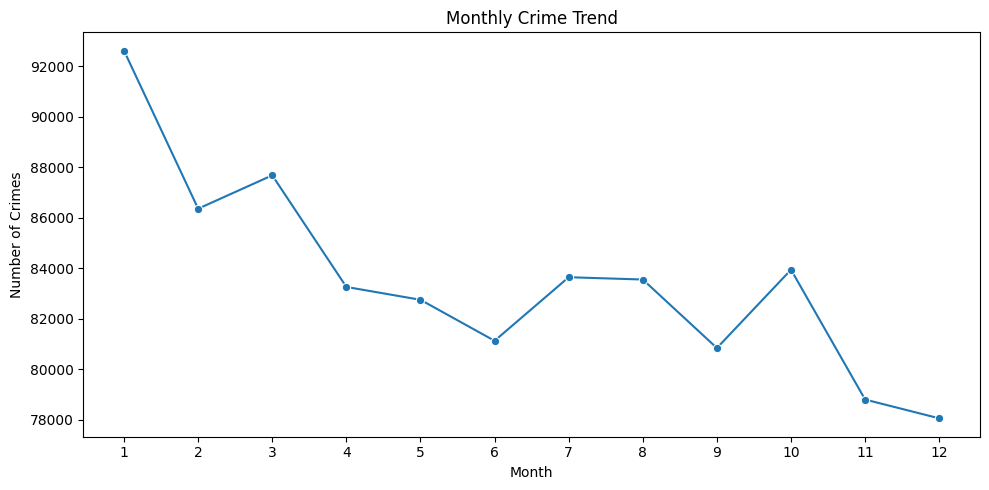

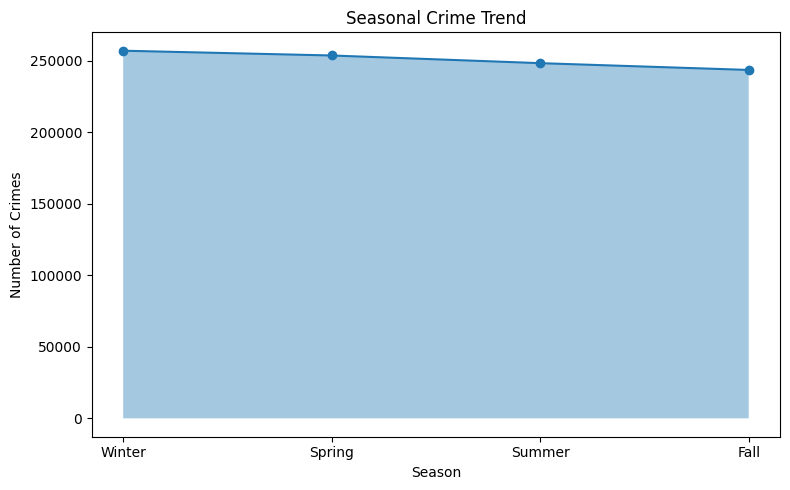

In [ ]:
# Line Plot - Monthly Crime Trends
monthly_counts = data_cleaned['Month_OCC'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_counts.index, y=monthly_counts.values, marker="o")
plt.title("Monthly Crime Trend")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Area Plot - Seasonal Crime Trends
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
season_counts = data_cleaned['Season_OCC'].value_counts().reindex(season_order)

plt.figure(figsize=(8, 5))
plt.fill_between(season_counts.index, season_counts.values, alpha=0.4)
plt.plot(season_counts.index, season_counts.values, marker='o')
plt.title("Seasonal Crime Trend")
plt.xlabel("Season")
plt.ylabel("Number of Crimes")
plt.tight_layout()
plt.show()

**Victim Profiling**

Age Grouping

In [ ]:
filtered_data = data_cleaned.copy()
def age_group_custom(age):
    if age < 4:
        return 'Unknown'
    elif age <= 12:
        return 'Kid'
    elif age <= 17:
        return 'Teenager'
    elif age <= 64:
        return 'Adult'
    else:
        return 'Elderly'

filtered_data['Vict_Age_Group_Custom'] = filtered_data['Vict Age'].apply(age_group_custom)

In [ ]:
def clean_vict_sex(sex):
    if sex in ['F', 'M']:
        return sex
    elif isinstance(sex, str) and sex.lower() == 'unknown':
        return 'Other/Unknown'
    elif sex in ['X', 'H']:
        return 'Other/Unknown'
    else:
        return 'Other/Unknown'  # For any other unexpected values

filtered_data['Vict_Sex_Clean'] = filtered_data['Vict Sex'].apply(clean_vict_sex)

1. Age Group + Sex vs. Crime Type

In [ ]:
top_crimes = filtered_data['Crm Cd Desc'].value_counts().nlargest(10).index

# Filter dataset for only top crimes (within filtered_data)
filtered_top_crimes = filtered_data[filtered_data['Crm Cd Desc'].isin(top_crimes)]

victim_crime_crosstab = pd.crosstab(
    index=[filtered_top_crimes['Vict_Age_Group_Custom'], filtered_top_crimes['Vict_Sex_Clean']],
    columns=filtered_top_crimes['Crm Cd Desc']
)

victim_crime_crosstab.head(10)  # Preview first 10 rows


Crm Cd Desc                           ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT  \
Vict_Age_Group_Custom Vict_Sex_Clean                                                   
Adult                 F                                                        12521   
                      M                                                        33544   
                      Other/Unknown                                              392   
Elderly               F                                                          780   
                      M                                                         1866   
                      Other/Unknown                                               17   
Kid                   F                                                          167   
                      M                                                          222   
                      Other/Unknown                                               37   
Teenager              F                                                          550   

Crm Cd Desc                           BATTERY - SIMPLE ASSAULT  BURGLARY  \
Vict_Age_Group_Custom Vict_Sex_Clean                                       
Adult                 F                                  29550     12626   
                      M                                  33368     19600   
                      Other/Unknown                        230       955   
Elderly               F                                   2896      2893   
                      M                                   3420      3571   
                      Other/Unknown                         13        10   
Kid                   F                                    421         5   
                      M                                    431        12   
                      Other/Unknown                          4         4   
Teenager              F                                   1750        37   

Crm Cd Desc                           BURGLARY FROM VEHICLE  \
Vict_Age_Group_Custom Vict_Sex_Clean                          
Adult                 F                               25203   
                      M                               33057   
                      Other/Unknown                     277   
Elderly               F                                1191   
                      M                                1705   
                      Other/Unknown                       3   
Kid                   F                                   5   
                      M                                   7   
                      Other/Unknown                       0   
Teenager              F                                  28   

Crm Cd Desc                           INTIMATE PARTNER - SIMPLE ASSAULT  \
Vict_Age_Group_Custom Vict_Sex_Clean                                      
Adult                 F                                           34117   
                      M                                           10536   
                      Other/Unknown                                  31   
Elderly               F                                             504   
                      M                                             355   
                      Other/Unknown                                   0   
Kid                   F                                              17   
                      M                                               6   
                      Other/Unknown                                   0   
Teenager              F                                             394   

Crm Cd Desc                           THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)  \
Vict_Age_Group_Custom Vict_Sex_Clean                                                    
Adult                 F                                                          6411   
                      M                                                          8292   
                

2. Victim Profile vs. Crime Type

<ipython-input-46-c52089cfde23>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_top_crimes['Vict_Age_Group_Custom'] = pd.Categorical(
<ipython-input-46-c52089cfde23>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_top_crimes['Vict_Sex_Clean'] = pd.Categorical(


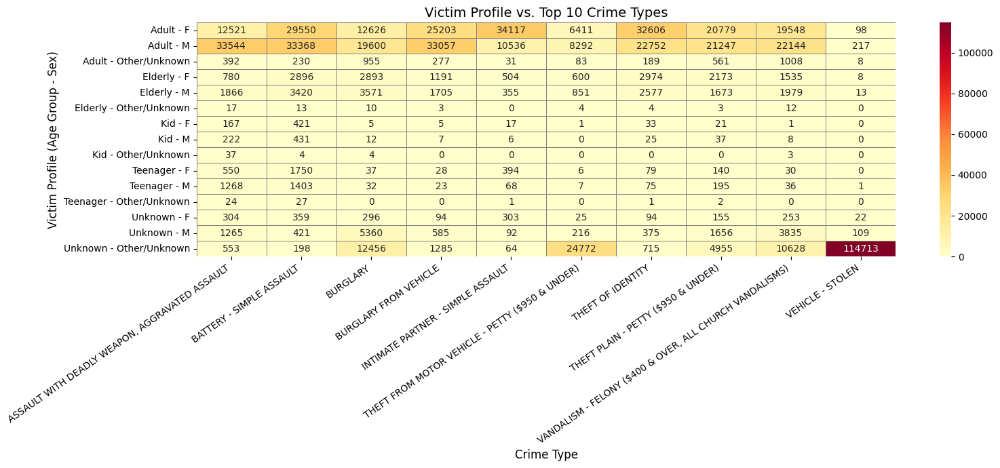

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the order for sorting categories (include 'Unknown' age group if present)
age_order = ['Unknown', 'Kid', 'Teenager', 'Adult', 'Elderly']
sex_order = ['F', 'M', 'Other/Unknown']

# Set categorical ordering for sorting
filtered_top_crimes['Vict_Age_Group_Custom'] = pd.Categorical(
    filtered_top_crimes['Vict_Age_Group_Custom'], categories=age_order, ordered=True
)
filtered_top_crimes['Vict_Sex_Clean'] = pd.Categorical(
    filtered_top_crimes['Vict_Sex_Clean'], categories=sex_order, ordered=True
)

# Sort by the ordered categories
filtered_top_crimes = filtered_top_crimes.sort_values(['Vict_Age_Group_Custom', 'Vict_Sex_Clean'])

# Create combined label for heatmap axis
filtered_top_crimes['Vict_Profile'] = (
    filtered_top_crimes['Vict_Age_Group_Custom'].astype(str) + " - " + filtered_top_crimes['Vict_Sex_Clean'].astype(str)
)

# Create cross-tabulation of victim profile vs crime type
victim_crime_crosstab = pd.crosstab(
    filtered_top_crimes['Vict_Profile'],
    filtered_top_crimes['Crm Cd Desc']
)

# Plot the heatmap
plt.figure(figsize=(16, 7))
sns.heatmap(
    victim_crime_crosstab,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='gray'
)
plt.title("Victim Profile vs. Top 10 Crime Types", fontsize=14)
plt.ylabel("Victim Profile (Age Group - Sex)", fontsize=12)
plt.xlabel("Crime Type", fontsize=12)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

3. Elderly Victims & Fraud

In [ ]:
# Filter for Elderly fraud-related crimes using custom age group column
elderly_fraud = filtered_data[
    (filtered_data['Vict_Age_Group_Custom'] == 'Elderly') &
    (filtered_data['Crm Cd Desc'].str.contains("FRAUD", case=False, na=False))
]

print(f"Elderly fraud victim cases: {len(elderly_fraud)}")
print(elderly_fraud[['Vict Age', 'Vict_Sex_Clean', 'Crm Cd Desc']].head())

Elderly fraud victim cases: 26
        Vict Age Vict_Sex_Clean  \
24817         66              M   
95839         69              F   
156298        73              F   
158390        84              F   
222319        67              M   

                                              Crm Cd Desc  
24817            CREDIT CARDS, FRAUD USE ($950.01 & OVER)  
95839               CREDIT CARDS, FRAUD USE ($950 & UNDER  
156298           CREDIT CARDS, FRAUD USE ($950.01 & OVER)  
158390              CREDIT CARDS, FRAUD USE ($950 & UNDER  
222319  DEFRAUDING INNKEEPER/THEFT OF SERVICES, $950 &...  


###**Socioeconomic Correlation Analysis**

 1. Poverty vs. Crime

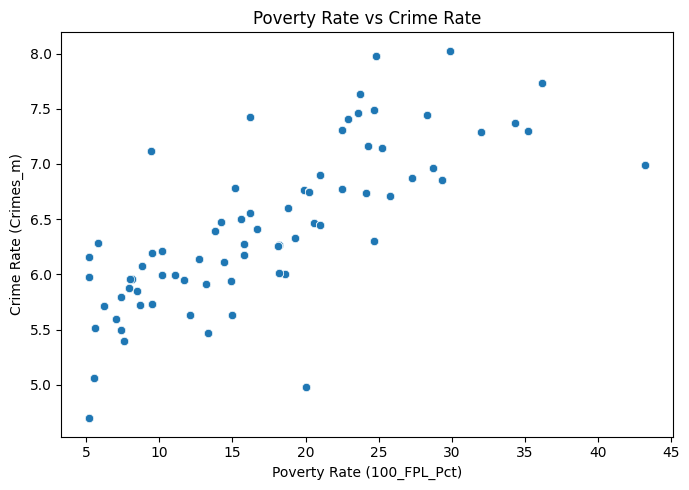

Pearson Correlation (100_FPL_Pct vs Crimes_m): 0.745 (p-value: 0.000)


In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=data_cleaned, x='100_FPL_Pct', y='Crimes_m')
plt.title("Poverty Rate vs Crime Rate")
plt.xlabel("Poverty Rate (100_FPL_Pct)")
plt.ylabel("Crime Rate (Crimes_m)")
plt.tight_layout()
plt.show()

# Pearson correlation
corr, pval = pearsonr(data_cleaned['100_FPL_Pct'], data_cleaned['Crimes_m'])
print(f"Pearson Correlation (100_FPL_Pct vs Crimes_m): {corr:.3f} (p-value: {pval:.3f})")

 2. Income vs Grand Theft

Total entries: 5794
Missing MHI values: 0


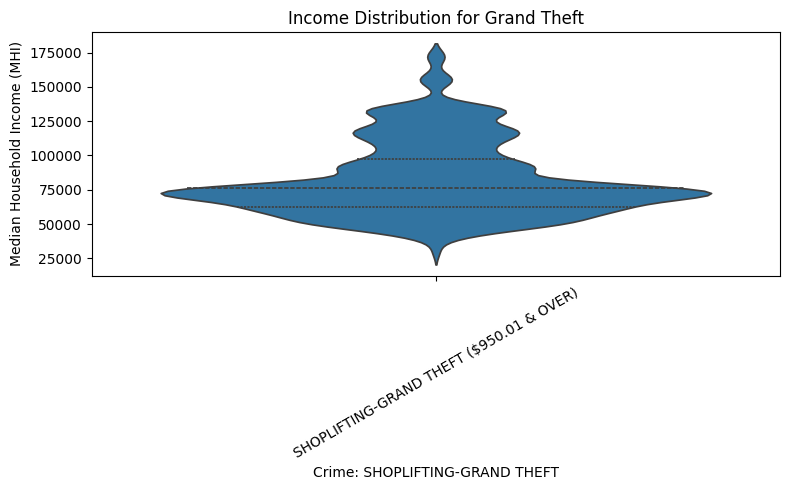

In [ ]:
# Filter entries specifically for the correct label
grand_theft_data = data_cleaned[
    data_cleaned['Crm Cd Desc'] == "SHOPLIFTING-GRAND THEFT ($950.01 & OVER)"
]

# Check if any data exists and if MHI is present
print(f"Total entries: {len(grand_theft_data)}")
print(f"Missing MHI values: {grand_theft_data['MHI'].isnull().sum()}")

# Drop any missing values in MHI
grand_theft_data = grand_theft_data.dropna(subset=['MHI'])

# Plot again only if data is available
if len(grand_theft_data) > 0:
    plt.figure(figsize=(8, 5))
    sns.violinplot(data=grand_theft_data, x='Crm Cd Desc', y='MHI', inner='quartile')
    plt.title("Income Distribution for Grand Theft")
    plt.xlabel("Crime: SHOPLIFTING-GRAND THEFT")
    plt.ylabel("Median Household Income (MHI)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No data available for this crime with valid MHI values.")

 3. Education vs Crime rate

Edu_HSGrad_Pct

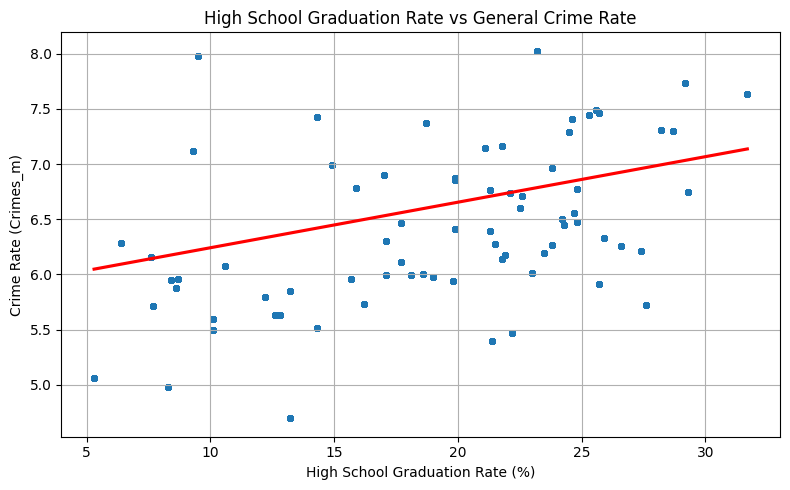

In [ ]:
# Step 1: Filter rows with valid values
edu_crime_all = data_cleaned[['Edu_HSGrad_Pct', 'Crimes_m']].dropna()

# Step 2: Scatter plot with trendline
plt.figure(figsize=(8, 5))
sns.regplot(data=edu_crime_all, x='Edu_HSGrad_Pct', y='Crimes_m', scatter_kws={"s": 15}, line_kws={"color": "red"})

# Step 3: Plot settings
plt.title("High School Graduation Rate vs General Crime Rate")
plt.xlabel("High School Graduation Rate (%)")
plt.ylabel("Crime Rate (Crimes_m)")
plt.grid(True)
plt.tight_layout()
plt.show()

Edu_LessHS_Pct

In [ ]:
# Recalculate Edu_LessHS_Pct
data_cleaned['Edu_LessHS_Pct'] = 100 - (
    data_cleaned['Edu_HSGrad_Pct'] +
    data_cleaned['Edu_College_Pct'] +
    data_cleaned['Edu_Bach_Pct']
)

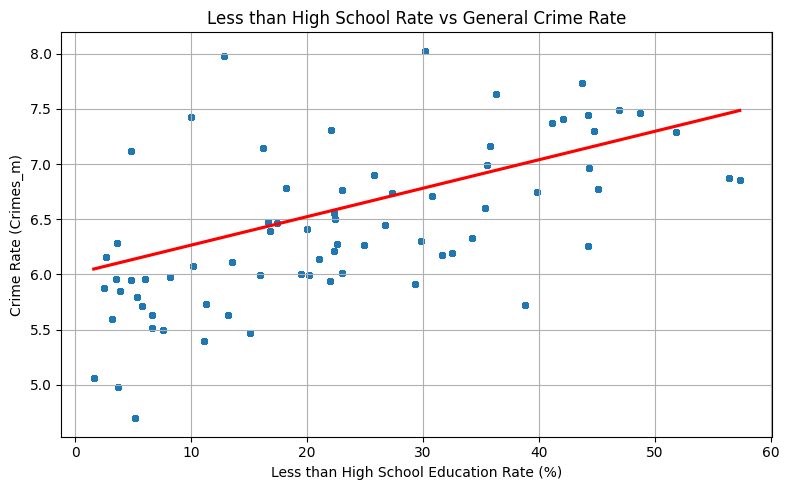

In [ ]:
# Step 1: Filter rows with valid values
lesshs_crime_all = data_cleaned[['Edu_LessHS_Pct', 'Crimes_m']].dropna()

# Step 2: Scatter plot with trendline
plt.figure(figsize=(8, 5))
sns.regplot(
    data=lesshs_crime_all,
    x='Edu_LessHS_Pct',
    y='Crimes_m',
    scatter_kws={"s": 15, "alpha": 0.5},
    line_kws={"color": "red"}
)

# Step 3: Plot settings
plt.title("Less than High School Rate vs General Crime Rate")
plt.xlabel("Less than High School Education Rate (%)")
plt.ylabel("Crime Rate (Crimes_m)")
plt.grid(True)
plt.tight_layout()
plt.show()

 4. Homelessness vs Crime

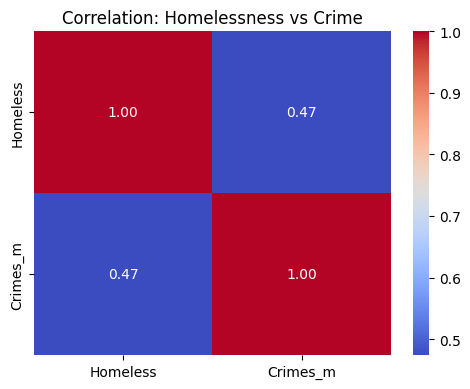

In [ ]:
# Correlation Matrix
corr_matrix = data_cleaned[['Homeless', 'Crimes_m']].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation: Homelessness vs Crime")
plt.tight_layout()
plt.show()

Relationship between Homelessness and Crime per area

In [ ]:
# Group by AREA NAME to calculate average Homelessness and Crime
area_grouped = data_cleaned.groupby('AREA NAME')[['Homeless', 'Crimes_m']].mean().dropna()

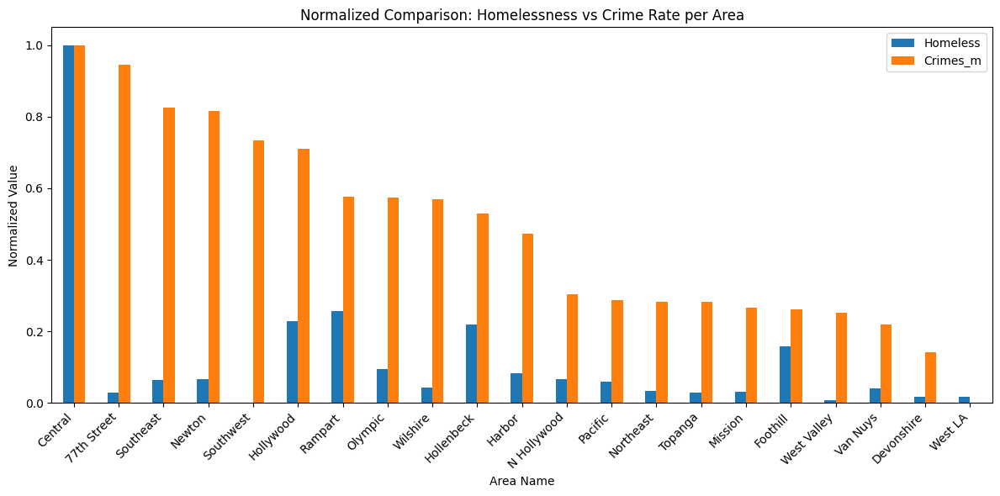

In [ ]:
# Normalize values for side-by-side plotting
normalized = area_grouped.copy()
normalized['Homeless'] = (normalized['Homeless'] - normalized['Homeless'].min()) / (normalized['Homeless'].max() - normalized['Homeless'].min())
normalized['Crimes_m'] = (normalized['Crimes_m'] - normalized['Crimes_m'].min()) / (normalized['Crimes_m'].max() - normalized['Crimes_m'].min())

# Plot
normalized.sort_values('Crimes_m', ascending=False).plot(kind='bar', figsize=(12, 6))
plt.title("Normalized Comparison: Homelessness vs Crime Rate per Area")
plt.ylabel("Normalized Value")
plt.xlabel("Area Name")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Firearm Crime Analysis**

In [ ]:
print(data_cleaned['Weapon Desc'].unique())

['None' 'STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)' 'VERBAL THREAT'
 'KNIFE WITH BLADE OVER 6 INCHES IN LENGTH' 'UNKNOWN WEAPON/OTHER WEAPON'
 'MACHETE' 'HAND GUN' 'SEMI-AUTOMATIC PISTOL' 'SIMULATED GUN' 'HAMMER'
 'RAZOR' 'OTHER FIREARM' 'KITCHEN KNIFE' 'STICK' 'UNKNOWN FIREARM'
 'KNIFE WITH BLADE 6INCHES OR LESS' 'PIPE/METAL PIPE'
 'AIR PISTOL/REVOLVER/RIFLE/BB GUN' 'OTHER CUTTING INSTRUMENT' 'SCISSORS'
 'SWITCH BLADE' 'ROCK/THROWN OBJECT' 'OTHER KNIFE' 'BOTTLE' 'CLUB/BAT'
 'BLUNT INSTRUMENT' 'BOARD' 'PHYSICAL PRESENCE' 'RIFLE' 'REVOLVER'
 'CLEAVER' 'STUN GUN' 'SCREWDRIVER' 'UNKNOWN TYPE CUTTING INSTRUMENT'
 'FOLDING KNIFE' 'VEHICLE' 'MACE/PEPPER SPRAY' 'FIRE'
 'CAUSTIC CHEMICAL/POISON' 'SHOTGUN' 'FIXED OBJECT' 'SEMI-AUTOMATIC RIFLE'
 'BELT FLAILING INSTRUMENT/CHAIN' 'BRASS KNUCKLES' 'TIRE IRON'
 'CONCRETE BLOCK/BRICK' 'AXE' 'SAWED OFF RIFLE/SHOTGUN'
 'MARTIAL ARTS WEAPONS' 'DEMAND NOTE' 'DIRK/DAGGER' 'TOY GUN' 'GLASS'
 'BOMB THREAT' 'RAZOR BLADE' 'ASSAULT WEAPON/UZI/AK47/ETC'
 '

1. Filter: Crimes with hand Weapon

In [ ]:
# List of hand weapons (you can modify or expand)
hand_weapon_types = [
    'HAND GUN', 'REVOLVER', 'SEMI-AUTOMATIC PISTOL', 'AIR PISTOL/REVOLVER/RIFLE/BB GUN',
    'STARTER PISTOL/REVOLVER', 'KNIFE WITH BLADE OVER 6 INCHES IN LENGTH',
    'KNIFE WITH BLADE 6INCHES OR LESS', 'KITCHEN KNIFE', 'OTHER KNIFE',
    'SWITCH BLADE', 'RAZOR', 'RAZOR BLADE', 'STRAIGHT RAZOR', 'DIRK/DAGGER',
    'SCISSORS', 'FOLDING KNIFE', 'CLEAVER', 'ICE PICK', 'BOWIE KNIFE',
    'SCREWDRIVER', 'CLUB/BAT', 'PIPE/METAL PIPE', 'TIRE IRON', 'HAMMER',
    'BLUNT INSTRUMENT'
]

# Filter for hand weapon-related crimes
hand_weapon_crimes = data_cleaned[data_cleaned['Weapon Desc'].isin(hand_weapon_types)]

print(f"Total hand-weapon-related crimes: {len(hand_weapon_crimes)}")
print(hand_weapon_crimes['Weapon Desc'].value_counts())

Total hand-weapon-related crimes: 58641
Weapon Desc
HAND GUN                                    20176
SEMI-AUTOMATIC PISTOL                        7256
KNIFE WITH BLADE 6INCHES OR LESS             6834
OTHER KNIFE                                  5871
PIPE/METAL PIPE                              2468
FOLDING KNIFE                                2262
CLUB/BAT                                     2087
KITCHEN KNIFE                                1916
AIR PISTOL/REVOLVER/RIFLE/BB GUN             1860
KNIFE WITH BLADE OVER 6 INCHES IN LENGTH     1693
BLUNT INSTRUMENT                             1382
HAMMER                                       1355
REVOLVER                                     1185
SCREWDRIVER                                   781
SCISSORS                                      658
SWITCH BLADE                                  234
TIRE IRON                                     149
RAZOR BLADE                                   118
DIRK/DAGGER                                    9

2. Compare with HOMICIDE Crimes

In [ ]:
# Filter for homicides
homicide_crimes = data_cleaned[data_cleaned['Crm Cd Desc'].str.contains("HOMICIDE", case=False, na=False)]
print(f"Total HOMICIDE crimes: {len(homicide_crimes)}")

Total HOMICIDE crimes: 1566


 3. Compare over Time (Line Chart by Year)

<Figure size 1000x500 with 0 Axes>

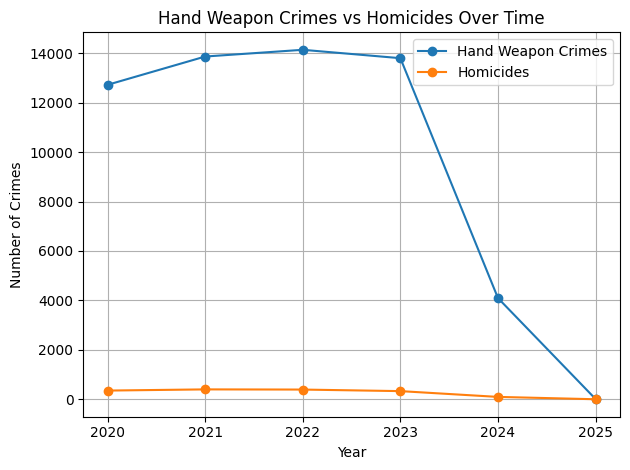

In [ ]:
# Group by year
handweapon_by_year = hand_weapon_crimes['Year_OCC'].value_counts().sort_index()
homicide_by_year = data_cleaned[
    data_cleaned['Crm Cd Desc'].str.contains("HOMICIDE", case=False, na=False)
]['Year_OCC'].value_counts().sort_index()

# Combine into one DataFrame
weapon_trends = pd.DataFrame({
    "Hand Weapon Crimes": handweapon_by_year,
    "Homicides": homicide_by_year
}).fillna(0)

# Line plot
plt.figure(figsize=(10, 5))
weapon_trends.plot(marker='o')
plt.title("Hand Weapon Crimes vs Homicides Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.grid(True)
plt.tight_layout()
plt.show()

**Mental Health vs. Crime**

1. Filter Drug-Related Crimes

In [ ]:
# Show all unique crime descriptions that might relate to drugs
drug_keywords = ['DRUG', 'MARIJUANA', 'NARCOTIC', 'CONTROLLED SUBSTANCE', 'POSSESSION']

drug_crimes = data_cleaned[
    data_cleaned['Crm Cd Desc'].str.contains('|'.join(drug_keywords), case=False, na=False)
]

print(f"Drug-related crimes: {len(drug_crimes)}")
print(drug_crimes['Crm Cd Desc'].value_counts())

Drug-related crimes: 52
Crm Cd Desc
WEAPONS POSSESSION/BOMBING    41
DRUGS, TO A MINOR             11
Name: count, dtype: int64


2. Compare Drug vs Non-Drug Crime Areas

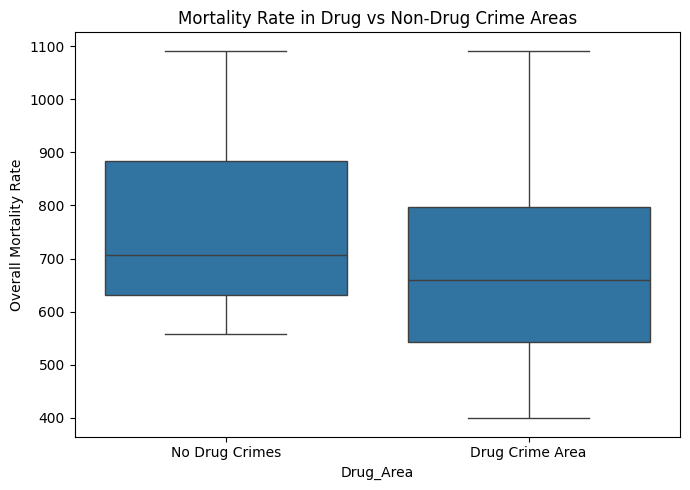

In [ ]:
# Label whether an area had drug crimes
data_cleaned['Drug_Area'] = data_cleaned['AREA NAME'].isin(drug_crimes['AREA NAME']).astype(int)

plt.figure(figsize=(7, 5))
sns.boxplot(data=data_cleaned, x='Drug_Area', y='Overall_MR')
plt.xticks([0, 1], ['No Drug Crimes', 'Drug Crime Area'])
plt.title("Mortality Rate in Drug vs Non-Drug Crime Areas")
plt.ylabel("Overall Mortality Rate")
plt.tight_layout()
plt.show()

3. Average Mortality per Area (with Drug Crimes)

<Figure size 1200x600 with 0 Axes>

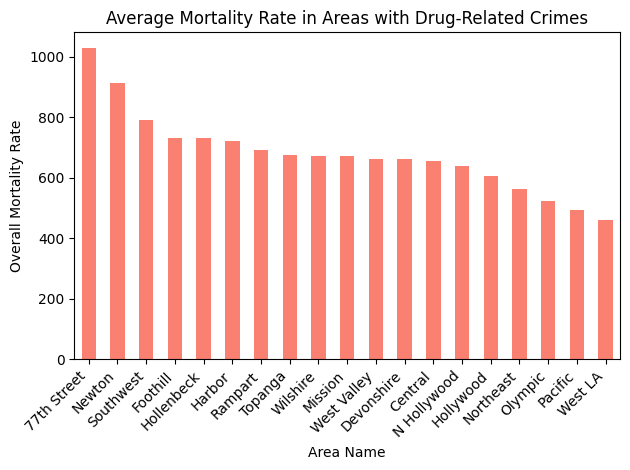

In [ ]:
# Step 1: Define drug-related keywords
drug_keywords = ['DRUG', 'MARIJUANA', 'NARCOTIC', 'CONTROLLED SUBSTANCE', 'POSSESSION']

# Step 2: Filter drug-related crimes
drug_crimes = data_cleaned[
    data_cleaned['Crm Cd Desc'].str.contains('|'.join(drug_keywords), case=False, na=False)
]

# Step 3: Group and merge
drug_crime_freq = drug_crimes.groupby('AREA NAME').size()
mortality_by_area = data_cleaned.groupby('AREA NAME')['Overall_MR'].mean()

# Step 4: Create merged DataFrame
drug_vs_health = pd.DataFrame({
    "Drug Crime Count": drug_crime_freq,
    "Average Mortality Rate": mortality_by_area
}).dropna()

# Step 5: Now plot again
plt.figure(figsize=(12, 6))
drug_vs_health.sort_values("Average Mortality Rate", ascending=False).plot(
    kind='bar', y='Average Mortality Rate', legend=False, color='salmon'
)
plt.title("Average Mortality Rate in Areas with Drug-Related Crimes")
plt.ylabel("Overall Mortality Rate")
plt.xlabel("Area Name")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### **Dimensionality Reduction**

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Print the column names to verify
print(data_cleaned.columns.tolist())

# Select only numerical columns from the dataset
numerical_df = data_cleaned.select_dtypes(include=['number']).copy()

# Handle missing values (fill missing with column mean or use another strategy)
numerical_df.fillna(numerical_df.mean(), inplace=True)

# Standardize the numerical features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(numerical_df)

pca = PCA(n_components=20)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(20)])
loadings = pd.DataFrame(pca.components_.T,
                        index=numerical_df.columns,
                        columns=[f'PC{i+1}' for i in range(20)])

# Calculate the total absolute contribution of each feature across all components
feature_contributions = loadings.abs().sum(axis=1)

# Sort and print the top 20 contributing features
top_features = feature_contributions.sort_values(ascending=False).head(20)
print("Top 20 contributing features to PCA components:")
print(top_features)

['Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Weapon Used Cd', 'Weapon Desc', 'LAT', 'LON', 'Nearest_Neighborhood', 'Diff_medical_C', 'SevHouse_B', 'Overcrowding', 'Homeless', 'Home_Own', 'Home_Rent', 'POP_FI', 'Adult_FI', 'Child_FI', 'Adult_NI', 'Pop_Total', 'Pop_age_0_17', 'Pop_age_18_64', 'Pop_age_65plus', 'Pop_race_ethnicity_pct_L', 'Pop_race_ethnicity_pct_W', 'Pop_race_ethnicity_pct_B', 'Pop_race_ethnicity_pct_A', 'Pop_race_ethnicity_pct_I', 'Pop_race_ethnicity_pct_P', 'Foreign_B', 'NBHD_Safety', 'Play_Place', 'Crimes_m', 'Overall_MR', 'COVID_a', 'Poor_health', 'MHI', '100_FPL_Pop', '100_FPL_Pct', '200_FPL_Pop', '200_FPL_Pct', '100_FPL_Child_Pop', '100_FPL_Child_Pct', '200_FPL_Child_Pop', '200_FPL_Child_Pct', 'Poverty_PST', 'Edu_LessHS_Pop', 'Edu_HSGrad_Pop', 'Edu_College_Pop', 'Edu_Bach_Pop', 'Edu_HSGrad_Pct', 'Edu_College_Pct', 'Edu_Bach_Pct', 'SE_Support', 'Alcohol_C', 'Bin

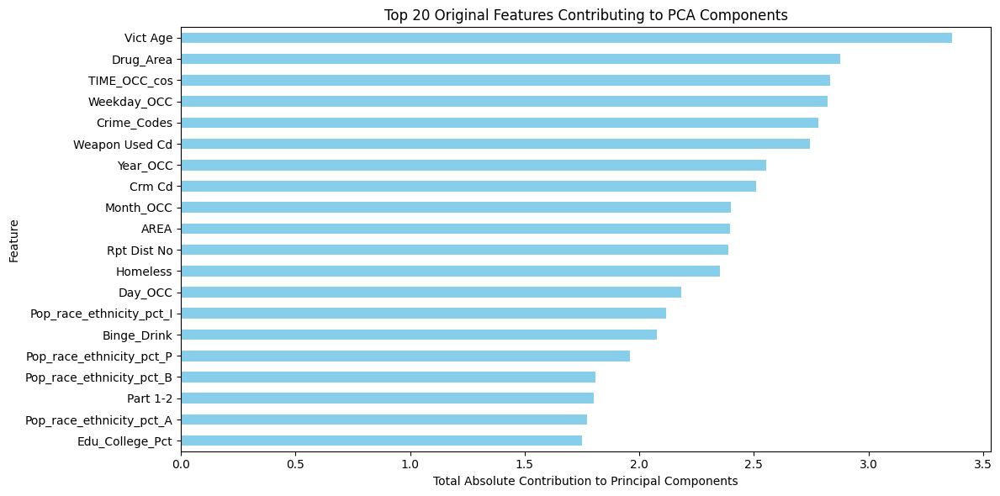

In [ ]:
# Visualize the top 20 contributing features with a bar chart
plt.figure(figsize=(12, 6))
top_features.sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title('Top 20 Original Features Contributing to PCA Components')
plt.xlabel('Total Absolute Contribution to Principal Components')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
X_pca.shape

(1002705, 20)

### **Clustering**

#### **Neighborhood Clustering (K-MEANS)**

In [ ]:
#Cluster 0 – Low-Risk Zone: Low crime, good health indicators, high education.
#Cluster 1 – Moderate-Risk Zone: Average levels on most indicators.
#Cluster 2 – High-Risk Zone: High crime, poor mental health, low education attainment.

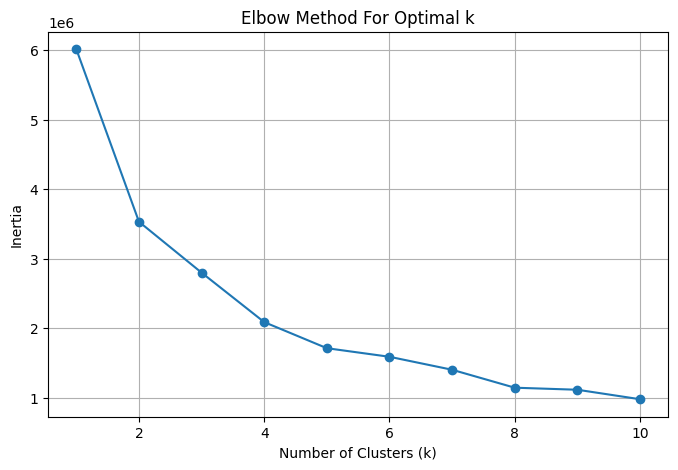

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
data_cleaned['Edu_LessHS_Pct'] = (data_cleaned['Edu_LessHS_Pop'] / data_cleaned['Pop_Total']) * 100

features = ['Crimes_m', 'Poor_health', 'Alcohol_C', 'Depression', '100_FPL_Pct', 'Edu_LessHS_Pct']
X = data_cleaned[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
data_cleaned.loc[X.index, 'KMeans_cluster'] = kmeans.fit_predict(X_scaled)
print(data_cleaned['KMeans_cluster'].value_counts())

KMeans_cluster
1.0    362861
0.0    348578
2.0    291266
Name: count, dtype: int64


In [ ]:
features_mean = data_cleaned.loc[X.index].groupby('KMeans_cluster')[features].mean()
print(features_mean.round(2))

                Crimes_m  Poor_health  Alcohol_C  Depression  100_FPL_Pct  \
KMeans_cluster                                                              
0.0                 7.37        20.16      47.71       11.06        28.03   
1.0                 6.41        16.17      52.61       14.33        17.10   
2.0                 6.01         9.06      66.44       16.42         9.50   

                Edu_LessHS_Pct  
KMeans_cluster                  
0.0                   82309.42  
1.0                   97953.64  
2.0                   21598.11  


<ipython-input-78-9efd19822721>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data_cleaned, x='KMeans_cluster', palette='Set2')


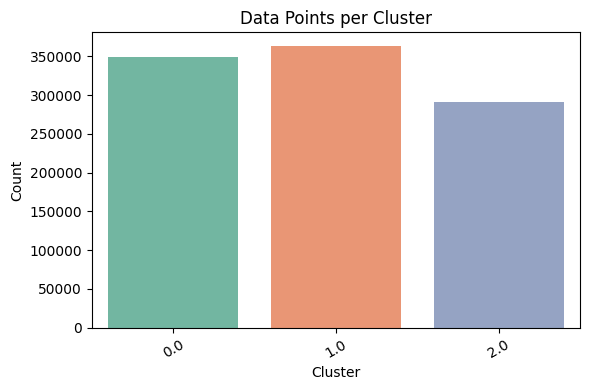

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
sns.countplot(data=data_cleaned, x='KMeans_cluster', palette='Set2')
plt.title('Data Points per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


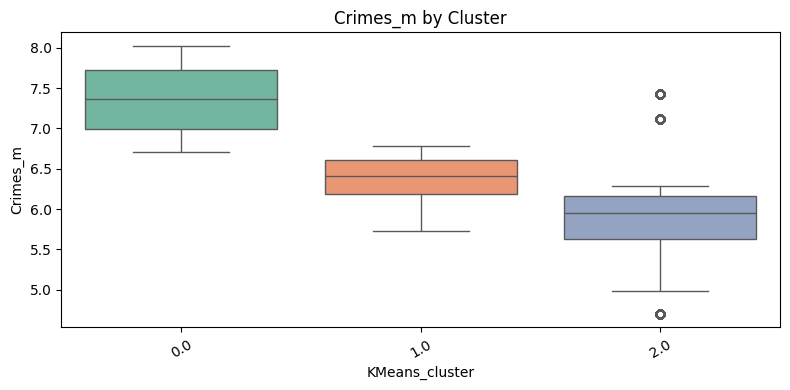

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


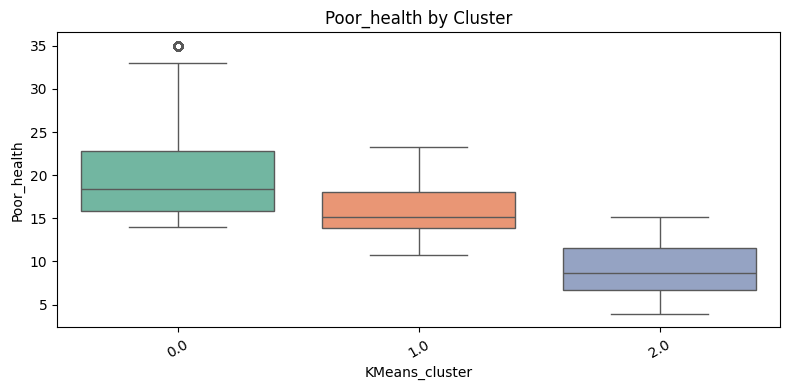

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


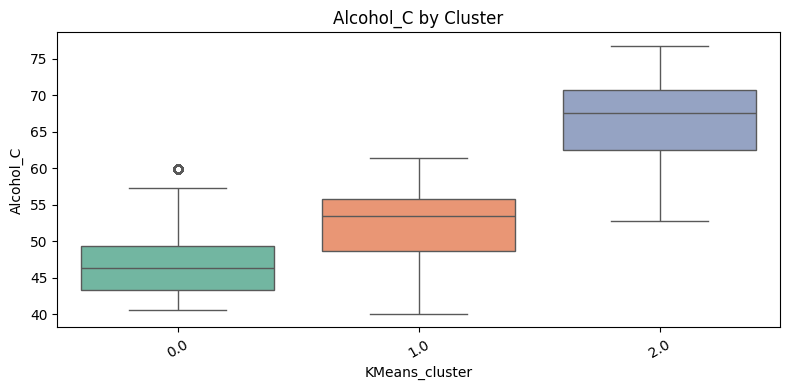

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


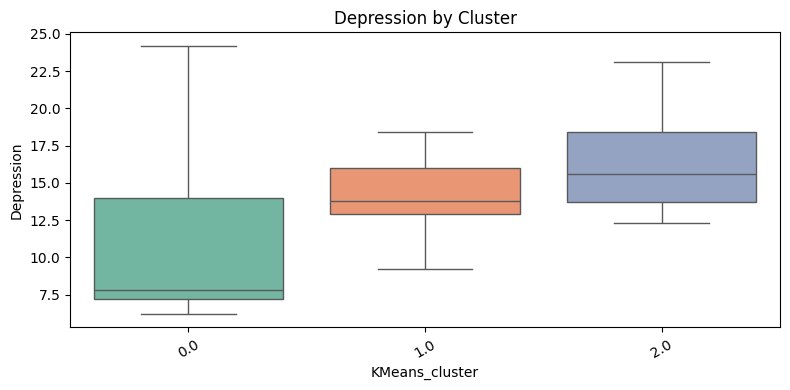

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


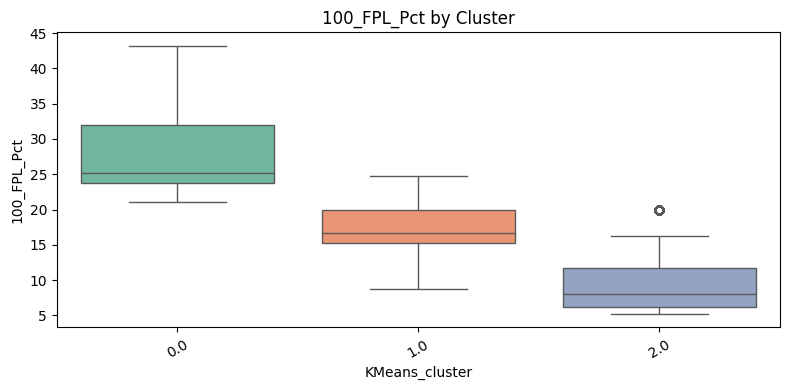

<ipython-input-79-8d080c455df0>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')


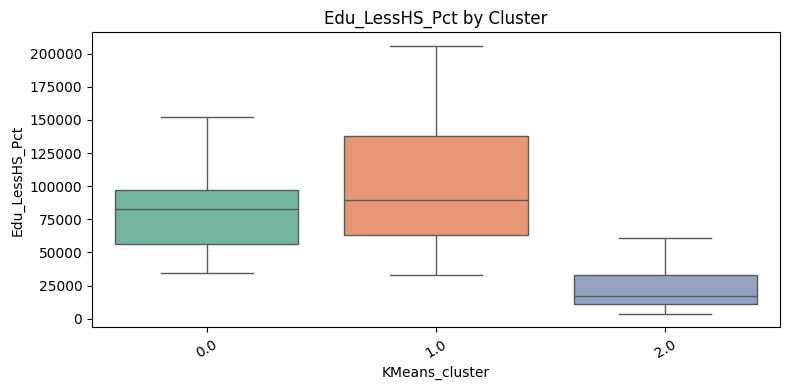

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
features = ['Crimes_m', 'Poor_health', 'Alcohol_C', 'Depression', '100_FPL_Pct', 'Edu_LessHS_Pct']

for feature in features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x='KMeans_cluster', y=feature, data=data_cleaned, palette='Set2')
    plt.title(f'{feature} by Cluster')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

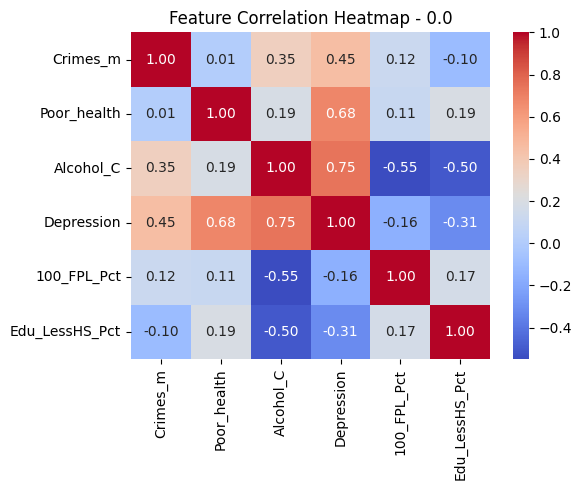

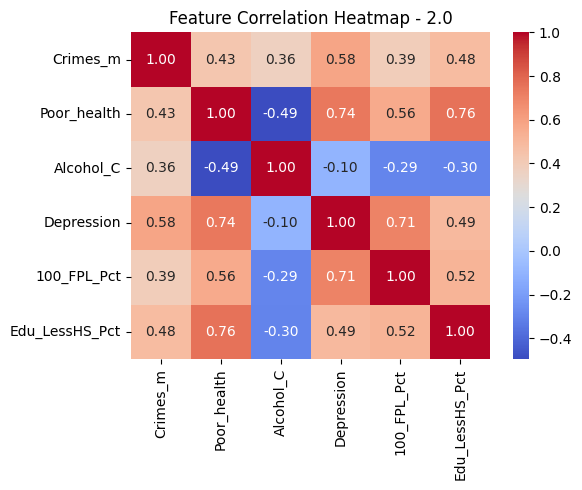

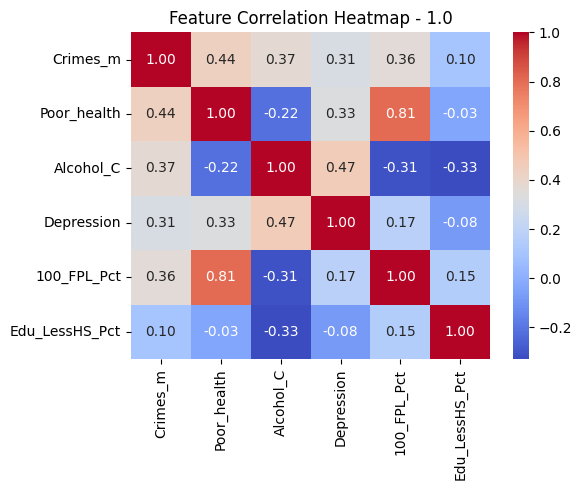

In [ ]:
import seaborn as sns
for label in data_cleaned['KMeans_cluster'].unique():
    subset = data_cleaned[data_cleaned['KMeans_cluster'] == label][features]
    corr = subset.corr()

    plt.figure(figsize=(6, 5))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
    plt.title(f'Feature Correlation Heatmap - {label}')
    plt.tight_layout()
    plt.show()

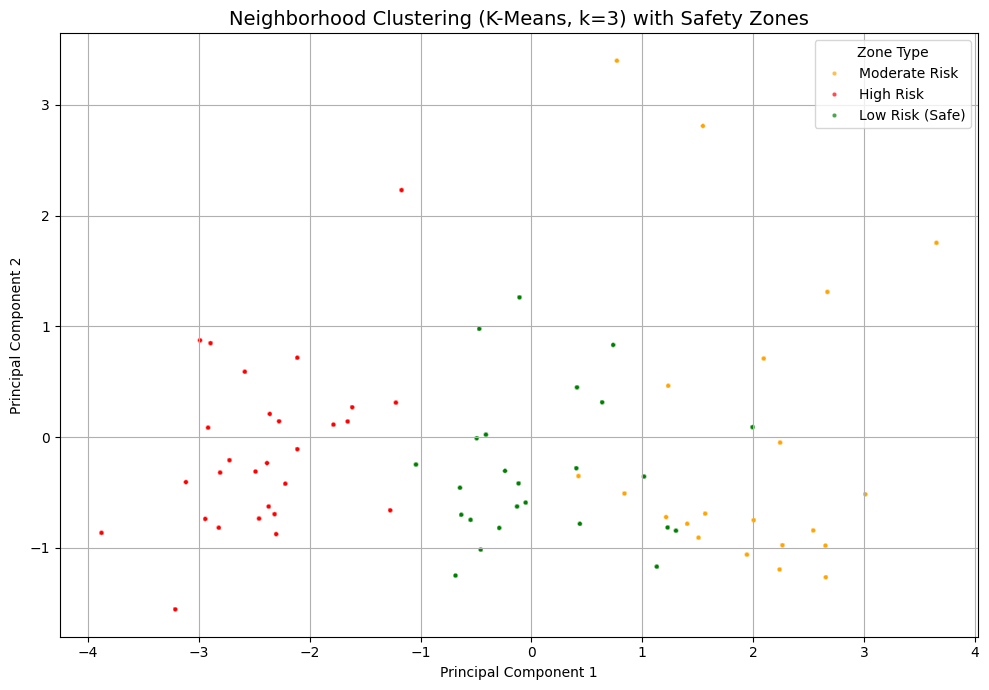

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
zone_map = {
    0.0: 'Moderate Risk',
    1.0: 'Low Risk (Safe)',
    2.0: 'High Risk'
}
data_cleaned.loc[X.index, 'KMeans_zone'] = data_cleaned.loc[X.index, 'KMeans_cluster'].map(zone_map)
zone_palette = {
    'High Risk': 'red',
    'Moderate Risk': 'orange',
    'Low Risk (Safe)': 'green'
}

# Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=data_cleaned.loc[X.index, 'KMeans_zone'],
    palette=zone_palette,
    s=10,
    alpha=0.7
)
plt.title("Neighborhood Clustering (K-Means, k=3) with Safety Zones", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Zone Type")
plt.grid(True)
plt.tight_layout()
plt.show()

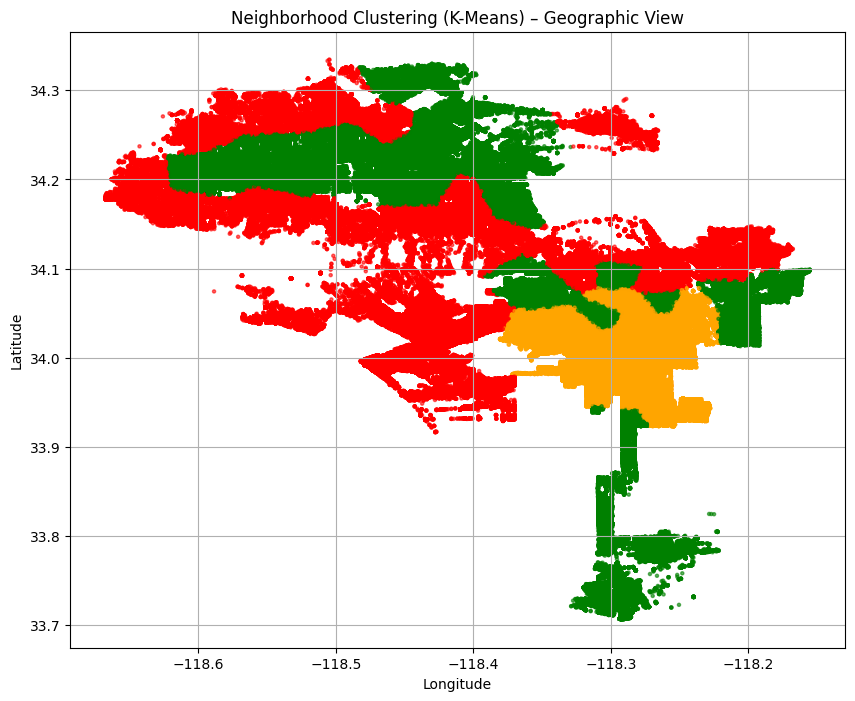

In [ ]:
import matplotlib.pyplot as plt
map_df = data_cleaned.dropna(subset=['LAT', 'LON', 'KMeans_zone'])
zone_colors = {
    'High Risk': 'red',
    'Moderate Risk': 'orange',
    'Low Risk (Safe)': 'green'
}
colors = map_df['KMeans_zone'].map(zone_colors)
plt.figure(figsize=(10, 8))
plt.scatter(map_df['LON'], map_df['LAT'], c=colors, s=5, alpha=0.6)
plt.title("Neighborhood Clustering (K-Means) – Geographic View")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

In [ ]:
import plotly.express as px

#Ensure LAT, LON, and KMeans_zone exist and are valid
map_df = data_cleaned.dropna(subset=['LAT', 'LON', 'KMeans_zone'])

# Plot
fig = px.scatter_mapbox(
    map_df,
    lat='LAT',
    lon='LON',
    color='KMeans_zone',
    color_discrete_map={
        'High Risk': 'red',
        'Moderate Risk': 'orange',
        'Low Risk (Safe)': 'green'
    },
    zoom=10,
    height=600,
    width=1000,
    hover_data=['Nearest_Neighborhood', 'Crimes_m', '100_FPL_Pct']
)

fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(title="Neighborhood Safety Clusters (K-Means)")
fig.show()

Time-Based **Clustering**

In [ ]:
from sklearn.preprocessing import StandardScaler
time_features = data_cleaned[['Hour_OCC', 'Weekday_OCC', 'Crm Cd']].dropna()

scaler = StandardScaler()
X_time = scaler.fit_transform(time_features)

In [ ]:
from sklearn.cluster import KMeans

kmeans_time = KMeans(n_clusters=4, random_state=42)
data_cleaned['time_kmeans_cluster'] = kmeans_time.fit_predict(X_time)

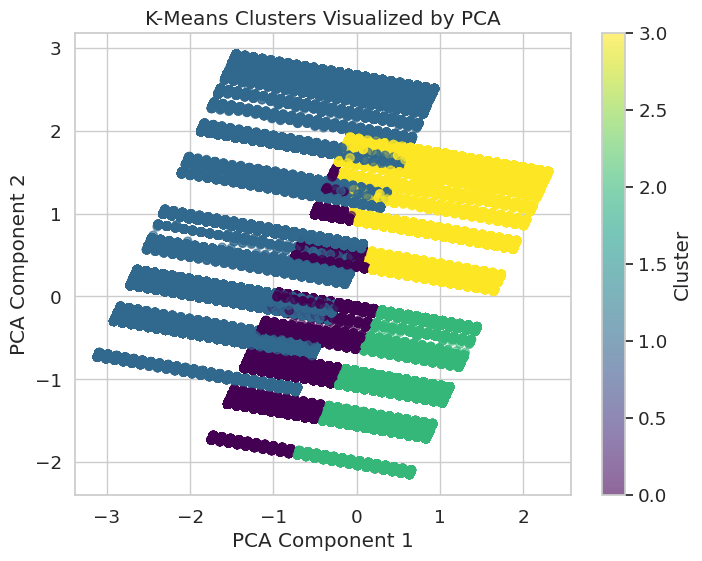

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_time)
plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=data_cleaned.loc[time_features.index, 'time_kmeans_cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Cluster')
plt.title('K-Means Clusters Visualized by PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()


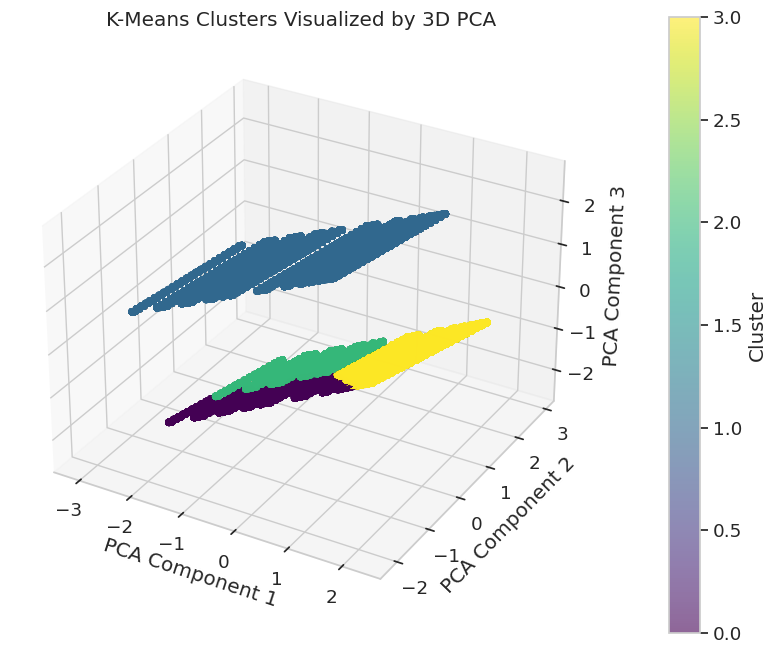

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_time)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
    c=data_cleaned.loc[time_features.index, 'time_kmeans_cluster'],
    cmap='viridis', alpha=0.6
)

ax.set_title('K-Means Clusters Visualized by 3D PCA')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
cbar = plt.colorbar(scatter, ax=ax, pad=0.1)
cbar.set_label('Cluster')

plt.show()


In [ ]:
for cid in sorted(data_cleaned['time_kmeans_cluster'].unique()):
    print(f"\n Cluster {cid}")

    subset = data_cleaned[data_cleaned['time_kmeans_cluster'] == cid]

    print(f"• Avg Hour: {subset['Hour_OCC'].mean():.1f}")
    print(f"• Weekend Crimes: {subset['Weekday_OCC'].mean() * 100:.1f}%")
    print(f"• Common Season: {subset['Season_OCC'].mode()[0]}")
    print(f"• Common Shift: {subset['Shift_OCC'].mode()[0]}")


    top_crimes = subset['Crm Cd Desc'].value_counts().head(3)
    print("• Top Crimes:")
    for crime, count in top_crimes.items():
        print(f"   - {crime}: {count}")


🔍 Cluster 0
• Avg Hour: 5.2
• Weekend Crimes: 0.0%
• Common Season: Winter
• Common Shift: Night
• Top Crimes:
   - VEHICLE - STOLEN: 25268
   - THEFT OF IDENTITY: 21364
   - BURGLARY: 16939

🔍 Cluster 1
• Avg Hour: 13.0
• Weekend Crimes: 100.0%
• Common Season: Winter
• Common Shift: Evening
• Top Crimes:
   - VEHICLE - STOLEN: 33013
   - BATTERY - SIMPLE ASSAULT: 23000
   - BURGLARY FROM VEHICLE: 18845

🔍 Cluster 2
• Avg Hour: 17.1
• Weekend Crimes: 0.0%
• Common Season: Winter
• Common Shift: Afternoon
• Top Crimes:
   - VEHICLE - STOLEN: 56908
   - BURGLARY FROM VEHICLE: 32874
   - THEFT OF IDENTITY: 26497

🔍 Cluster 3
• Avg Hour: 14.7
• Weekend Crimes: 0.0%
• Common Season: Spring
• Common Shift: Afternoon
• Top Crimes:
   - BATTERY - SIMPLE ASSAULT: 42261
   - VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS): 36863
   - INTIMATE PARTNER - SIMPLE ASSAULT: 22447


In [ ]:
cluster_labels = {
    0: "",
    1: "",
    2: "",
    3: ""
}

data_cleaned['Risk_Label'] = data_cleaned['time_kmeans_cluster'].map(cluster_labels)

<ipython-input-89-fe0d7bd1fcf8>:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




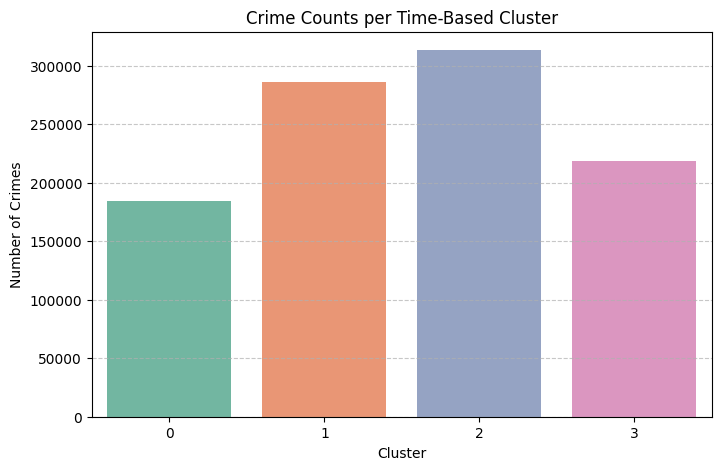

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=data_cleaned, x='time_kmeans_cluster', palette='Set2')
plt.title('Crime Counts per Time-Based Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Crimes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

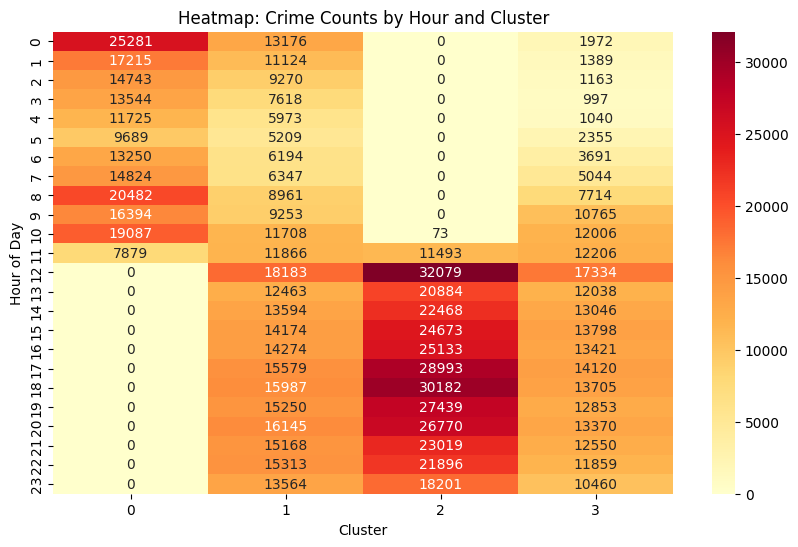

In [ ]:
# Pivot table: rows = hour, columns = cluster, values = crime counts
heatmap_data = data_cleaned.pivot_table(
    index='Hour_OCC',
    columns='time_kmeans_cluster',
    values='Crm Cd',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Heatmap: Crime Counts by Hour and Cluster')
plt.xlabel('Cluster')
plt.ylabel('Hour of Day')
plt.show()

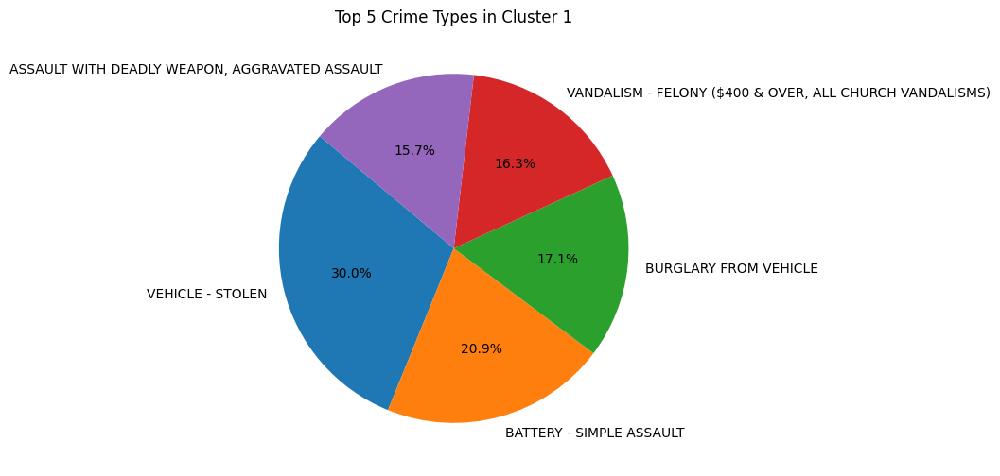

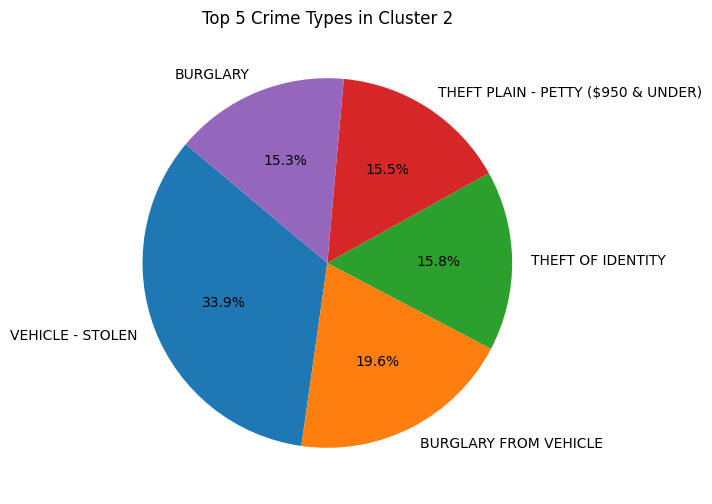

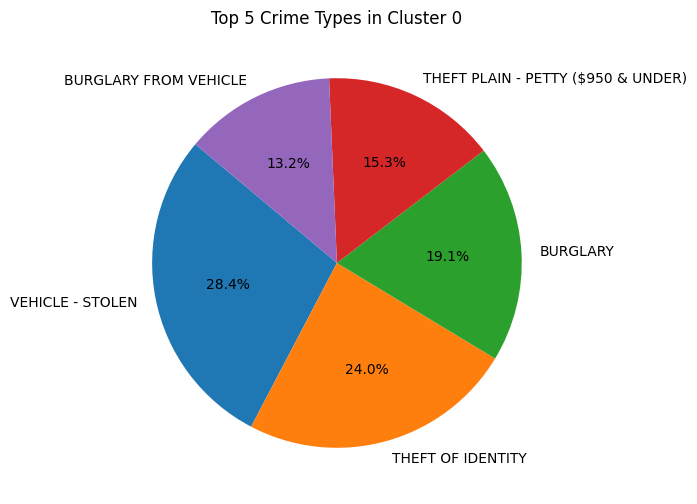

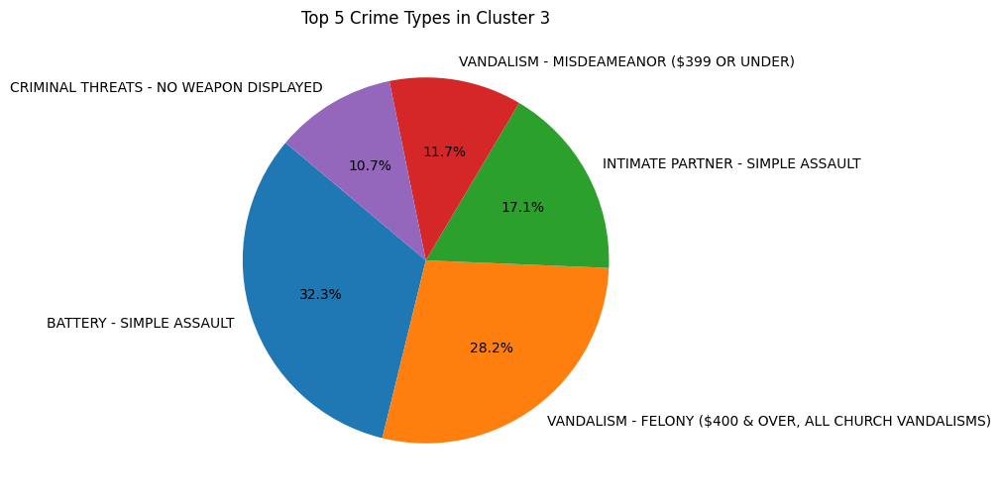

In [ ]:
import matplotlib.pyplot as plt

clusters = data_cleaned['time_kmeans_cluster'].unique()

for cid in clusters:
    subset = data_cleaned[data_cleaned['time_kmeans_cluster'] == cid]
    top_crimes = subset['Crm Cd Desc'].value_counts().head(5)

    plt.figure(figsize=(6,6))
    plt.pie(top_crimes, labels=top_crimes.index, autopct='%1.1f%%', startangle=140)
    plt.title(f'Top 5 Crime Types in Cluster {cid}')
    plt.show()

<ipython-input-92-f1e91b4367c3>:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




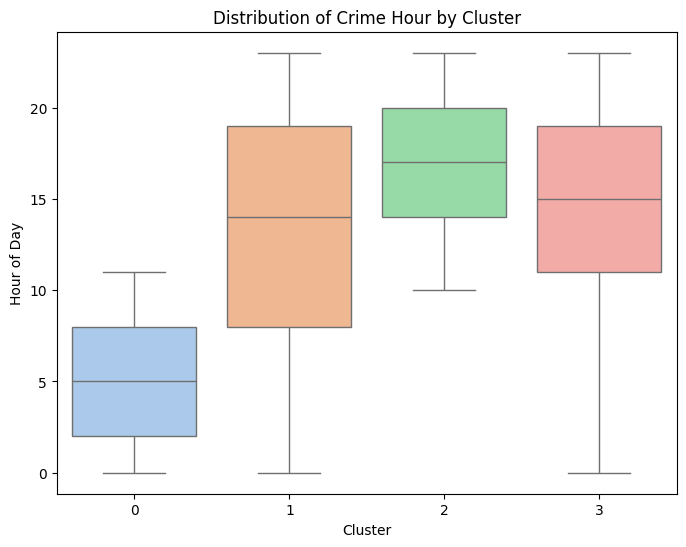

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=data_cleaned, x='time_kmeans_cluster', y='Hour_OCC', palette='pastel')
plt.title('Distribution of Crime Hour by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Hour of Day')
plt.show()

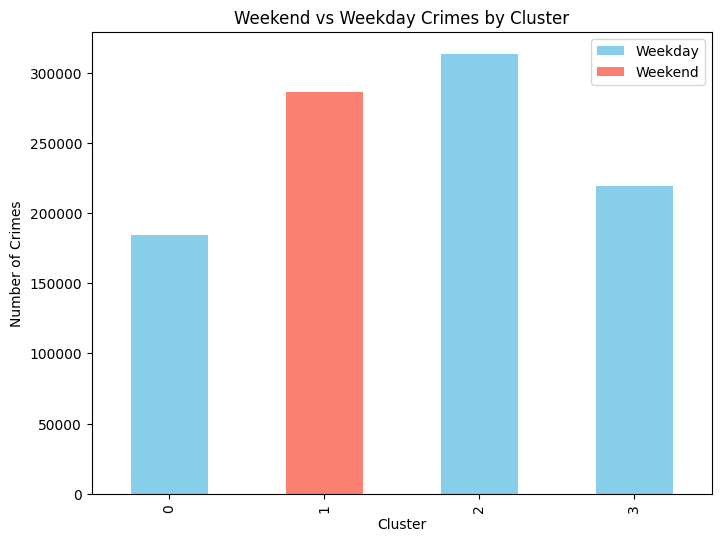

In [ ]:
import pandas as pd

weekend_counts = data_cleaned.groupby(['time_kmeans_cluster', 'Weekday_OCC']).size().unstack(fill_value=0)

weekend_counts.plot(kind='bar', stacked=True, figsize=(8,6), color=['skyblue', 'salmon'])
plt.title('Weekend vs Weekday Crimes by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Crimes')
plt.legend(['Weekday', 'Weekend'])
plt.show()


Victim Profiling

####Victim Profiling

In [ ]:
sample_data = data_cleaned.sample(n=3000, random_state=42)
from sklearn.preprocessing import LabelEncoder, StandardScaler

le_descent = LabelEncoder()
le_sex = LabelEncoder()
le_crime = LabelEncoder()

sample_data['Vict_Descent_Encoded'] = le_descent.fit_transform(sample_data['Vict Descent'])
sample_data['Vict_Sex_Encoded'] = le_sex.fit_transform(sample_data['Vict Sex'])
sample_data['Crime_Desc_Encoded'] = le_crime.fit_transform(sample_data['Crm Cd Desc'])

features = sample_data[['Vict Age', 'Vict_Descent_Encoded', 'Vict_Sex_Encoded', 'Crime_Desc_Encoded']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)


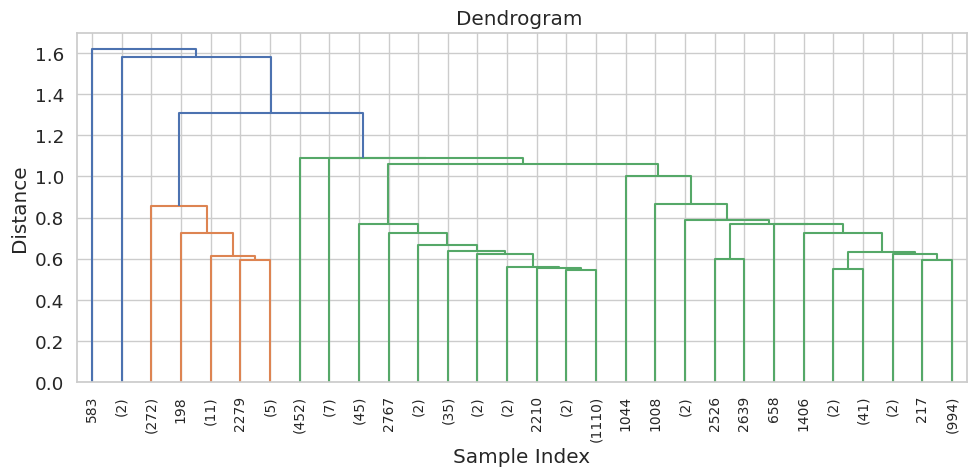

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt

Z = linkage(X_scaled, method='single')
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10.)
plt.title('Dendrogram ')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()
sample_data['Victim_Cluster'] = fcluster(Z, t=3, criterion='maxclust')

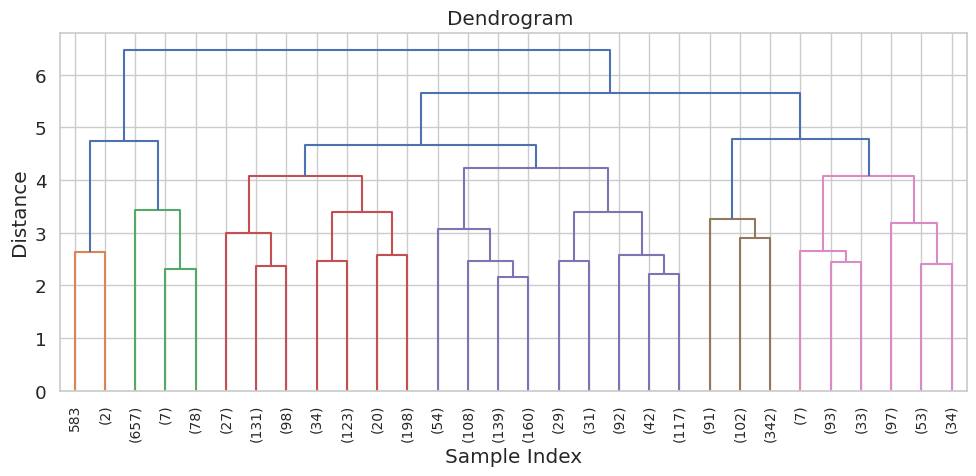

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
Z = linkage(X_scaled, method='complete')

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10.)
plt.title('Dendrogram ')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

sample_data['Victim_Cluster'] = fcluster(Z, t=3, criterion='maxclust')


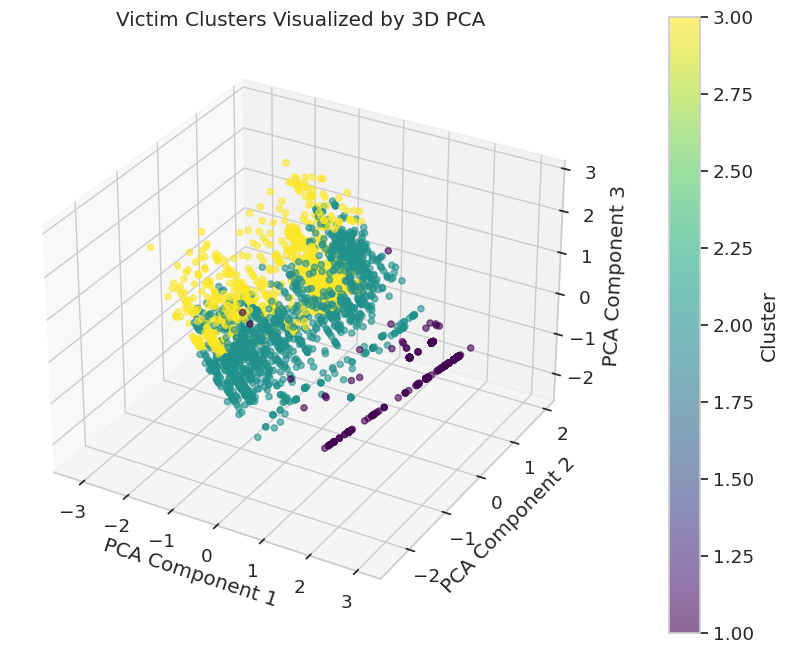

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
    c=sample_data['Victim_Cluster'],
    cmap='viridis', alpha=0.6
)

ax.set_title('Victim Clusters Visualized by 3D PCA')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
cbar = plt.colorbar(scatter, ax=ax, pad=0.1)
cbar.set_label('Cluster')

plt.show()


<ipython-input-58-e7fe48b277c9>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


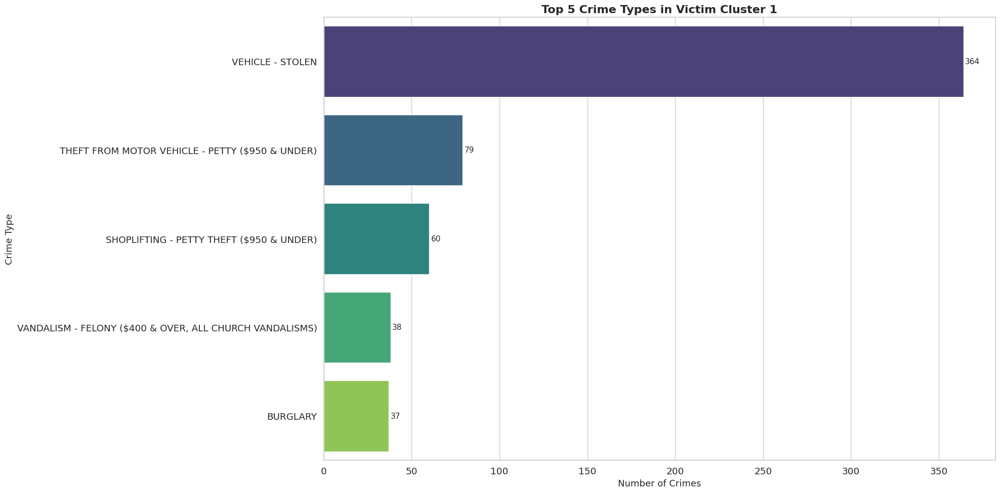

<ipython-input-58-e7fe48b277c9>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


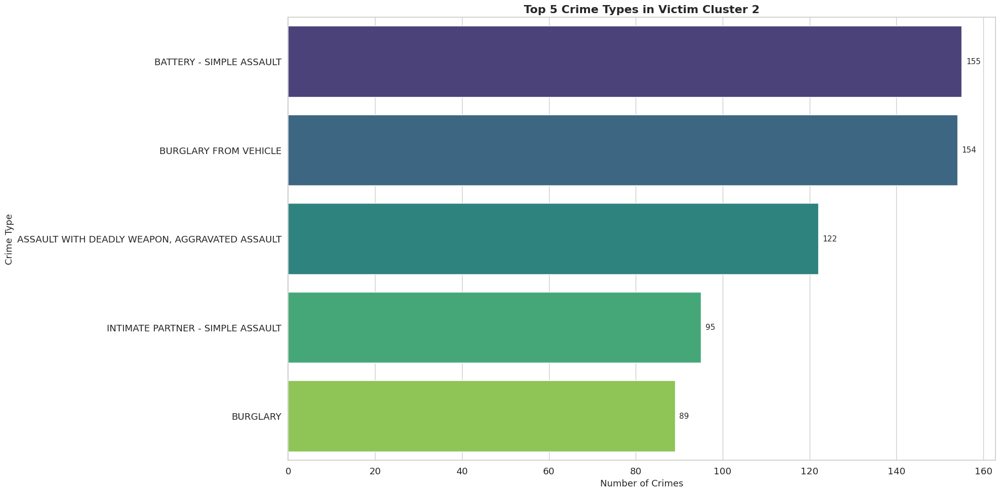

<ipython-input-58-e7fe48b277c9>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


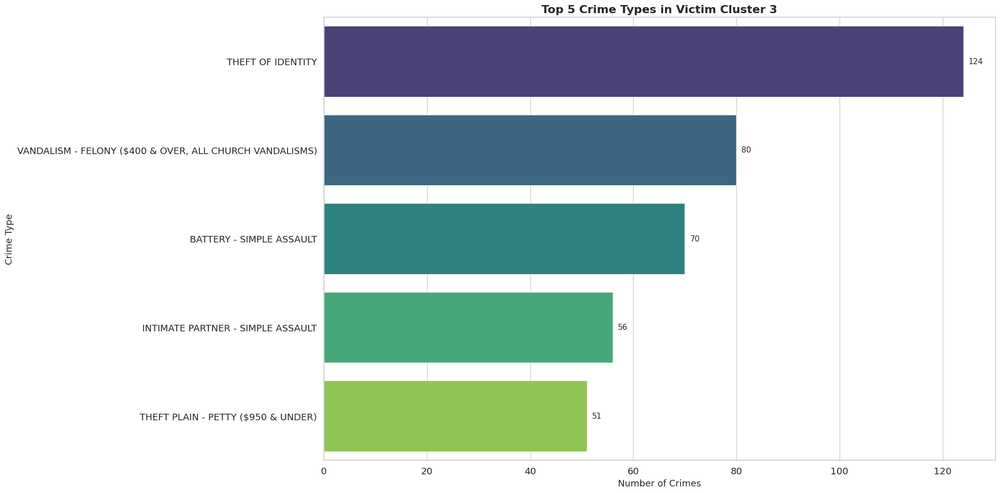

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid", font_scale=1.2)
for cluster in sorted(sample_data['Victim_Cluster'].unique()):
    top_crimes = (
        sample_data[sample_data['Victim_Cluster'] == cluster]['Crm Cd Desc']
        .value_counts()
        .head(5)
    )

    plt.figure(figsize=(20, 10))
    ax = sns.barplot(
        x=top_crimes.values,
        y=top_crimes.index,
        palette='viridis'
    )

    plt.title(f"Top 5 Crime Types in Victim Cluster {cluster}", fontsize=16, fontweight='bold')
    plt.xlabel("Number of Crimes", fontsize=13)
    plt.ylabel("Crime Type", fontsize=13)

    # Annotate each bar with value
    for i, value in enumerate(top_crimes.values):
        plt.text(value + 1, i, str(value), va='center', fontsize=11)

    plt.tight_layout()
    plt.show()


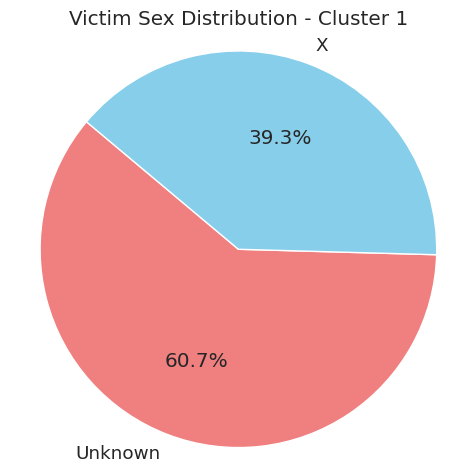

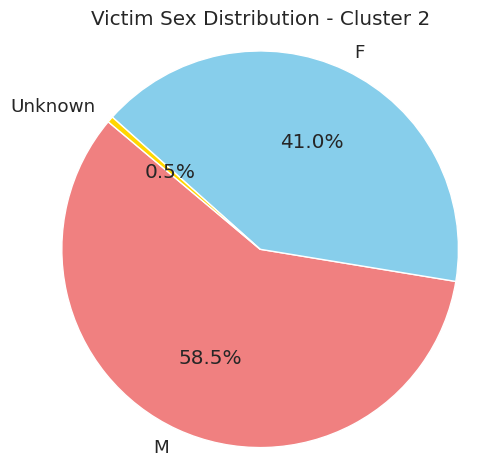

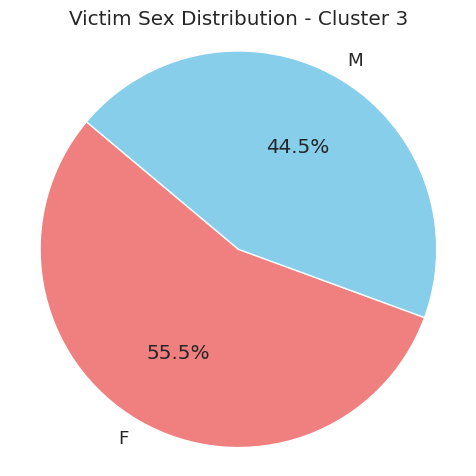

In [ ]:
import matplotlib.pyplot as plt

clusters = sorted(sample_data['Victim_Cluster'].unique())

for cluster in clusters:
    sex_counts = sample_data[sample_data['Victim_Cluster'] == cluster]['Vict Sex'].value_counts()

    plt.figure(figsize=(5, 5))
    plt.pie(sex_counts, labels=sex_counts.index, autopct='%1.1f%%', startangle=140, colors=['lightcoral', 'skyblue', 'gold'])
    plt.title(f'Victim Sex Distribution - Cluster {cluster}')
    plt.axis('equal')
    plt.tight_layout()
    plt.show()


Cluster counts:
Victim_Cluster
2    1403
3     852
1     745
Name: count, dtype: int64
                 count       mean        std   min   25%   50%   75%   max
Victim_Cluster                                                            
1                745.0   0.865772   5.961636   0.0   0.0   0.0   0.0  81.0
2               1403.0  30.130435  13.579983   0.0  23.0  30.0  39.0  69.0
3                852.0  50.461268  15.401929  18.0  39.0  51.0  62.0  99.0


<ipython-input-53-19379b9e306f>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Victim_Cluster', y='Vict Age', data=sample_data, palette='Set2')


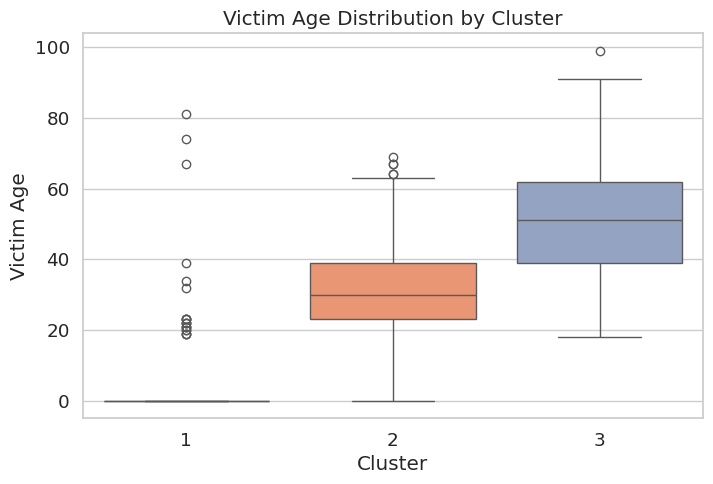

<ipython-input-53-19379b9e306f>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Victim_Cluster', y='Vict Age', data=sample_data, palette='Set3')


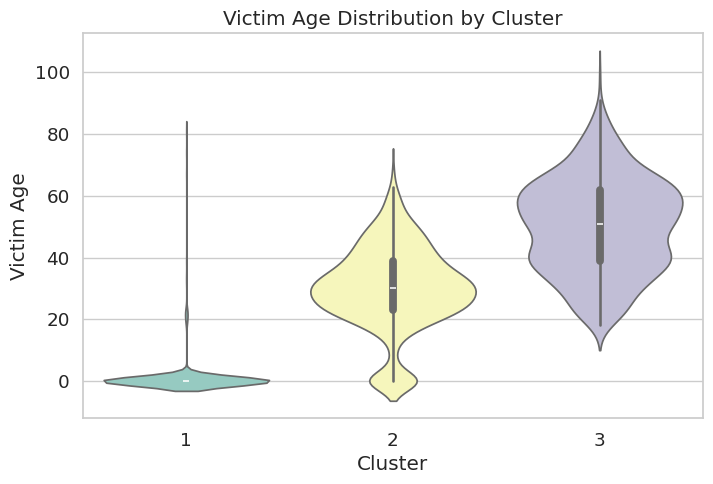

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Cluster counts:")
print(sample_data['Victim_Cluster'].value_counts())

age_stats = sample_data.groupby('Victim_Cluster')['Vict Age'].describe()
print(age_stats)
plt.figure(figsize=(8, 5))
sns.boxplot(x='Victim_Cluster', y='Vict Age', data=sample_data, palette='Set2')
plt.title('Victim Age Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Victim Age')
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(x='Victim_Cluster', y='Vict Age', data=sample_data, palette='Set3')
plt.title('Victim Age Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Victim Age')
plt.show()


### **Time-Series Analysis**

**A. Isolation Forest**

In [ ]:
from sklearn.ensemble import IsolationForest
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

data_pred_t = data_pred.copy()

week_crime = data_pred_t.groupby(pd.Grouper(key='date occ', freq='W')).size().reset_index(name='crime_count')

model = IsolationForest(contamination=0.05)
week_crime['anomaly_score'] = model.fit_predict(week_crime[['crime_count']])
week_crime['anomaly'] = week_crime['anomaly_score'].map({1: 0, -1: 1})

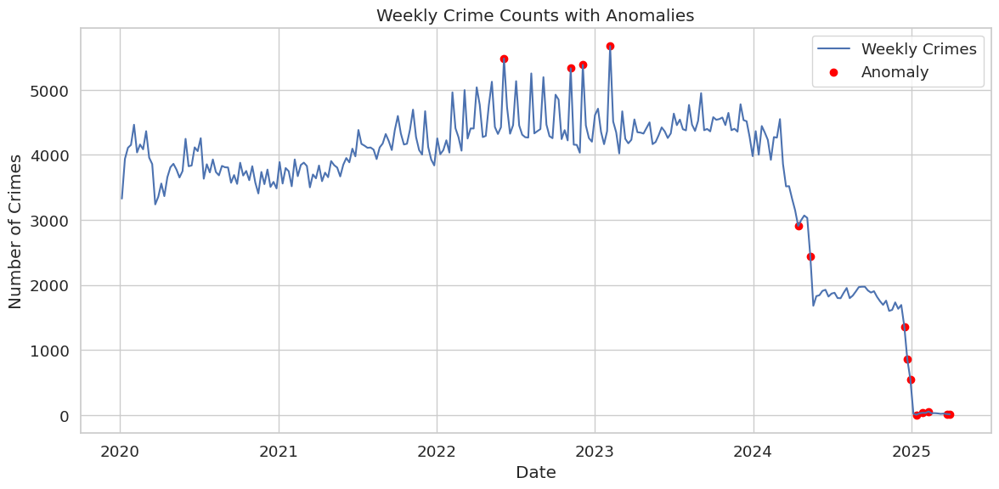

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(week_crime['date occ'], week_crime['crime_count'], label='Weekly Crimes')
plt.scatter(week_crime.loc[week_crime['anomaly'] == 1, 'date occ'],
            week_crime.loc[week_crime['anomaly'] == 1, 'crime_count'],
            color='red', label='Anomaly')
plt.title('Weekly Crime Counts with Anomalies')
plt.xlabel('Date')
plt.ylabel('Number of Crimes')
plt.legend()
plt.tight_layout()
plt.show()

Top Crime Types in Anomalous Weeks
crm cd desc
VEHICLE - STOLEN                                           2595
THEFT OF IDENTITY                                          2048
BURGLARY FROM VEHICLE                                      1818
BATTERY - SIMPLE ASSAULT                                   1571
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)    1453
THEFT PLAIN - PETTY ($950 & UNDER)                         1441
THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER)        1311
BURGLARY                                                   1296
SHOPLIFTING - PETTY THEFT ($950 & UNDER)                   1082
ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT             1022
Name: count, dtype: int64


<ipython-input-109-37bc2b7d3309>:39: UserWarning:

Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations



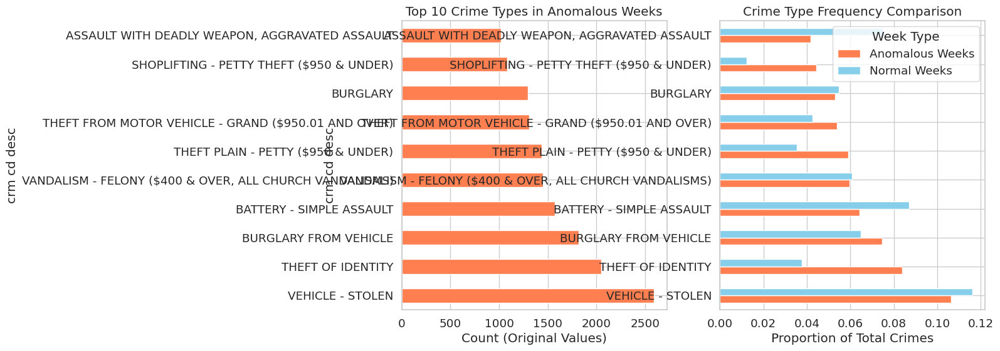

In [ ]:
#anomalous weeks using the processed data
anomalous_weeks = week_crime.loc[week_crime['anomaly'] == 1, 'date occ']


data_cleaned.columns = data_cleaned.columns.str.lower()
# Create a DataFrame for analysis using ORIGINAL values from data_cleaned
anomalous_data_original = pd.DataFrame()

for week_start in anomalous_weeks:
    week_end = week_start + pd.Timedelta(days=6)
    mask = (data_cleaned['date occ'] >= week_start) & (data_cleaned['date occ'] <= week_end)
    anomalous_data_original = pd.concat([anomalous_data_original, data_cleaned[mask]])

print("Top Crime Types in Anomalous Weeks")
print(anomalous_data_original['crm cd desc'].value_counts().head(10))

plt.figure(figsize=(12, 6))

top_crimes = anomalous_data_original['crm cd desc'].value_counts().nlargest(10)
ax1 = plt.subplot(1, 2, 1)
top_crimes.plot(kind='barh', color='coral', ax=ax1)
ax1.set_title('Top 10 Crime Types in Anomalous Weeks')
ax1.set_xlabel('Count (Original Values)')

normal_weeks = week_crime.loc[week_crime['anomaly'] == 0, 'date occ']
sample_normal_data = data_cleaned[data_cleaned['date occ'].isin(normal_weeks.sample(5))]

compare_df = pd.DataFrame({
    'Anomalous Weeks': anomalous_data_original['crm cd desc'].value_counts(normalize=True),
    'Normal Weeks': sample_normal_data['crm cd desc'].value_counts(normalize=True)
}).fillna(0).nlargest(10, 'Anomalous Weeks')

ax2 = plt.subplot(1, 2, 2)
compare_df.plot(kind='barh', ax=ax2, color=['coral', 'skyblue'])
ax2.set_title('Crime Type Frequency Comparison')
ax2.set_xlabel('Proportion of Total Crimes')
ax2.legend(title='Week Type')

plt.tight_layout()
plt.show()



Hourly Distribution in Anomalous Weeks


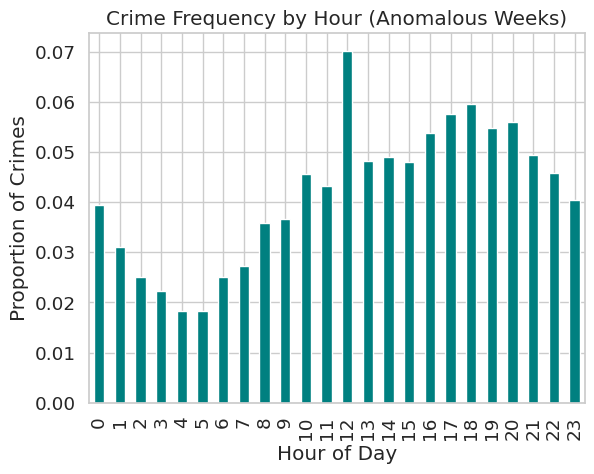

In [ ]:
print("\nHourly Distribution in Anomalous Weeks")
hourly_dist = anomalous_data_original.groupby('hour_occ').size()
(hourly_dist/hourly_dist.sum()).plot(kind='bar', color='teal')
plt.title('Crime Frequency by Hour (Anomalous Weeks)')
plt.ylabel('Proportion of Crimes')
plt.xlabel('Hour of Day')
plt.show()

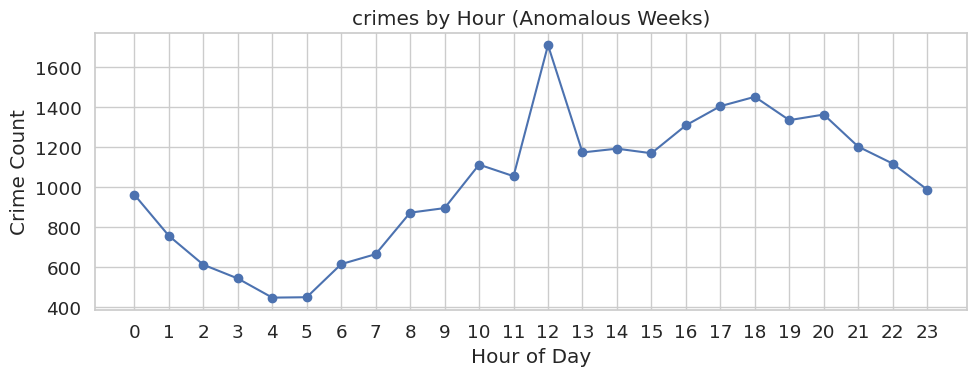

In [ ]:
hourly = anomalous_data['hour_occ'].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.plot(hourly.index, hourly.values, marker='o', linestyle='-')
plt.title("crimes by Hour (Anomalous Weeks)")
plt.xlabel("Hour of Day")
plt.ylabel("Crime Count")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

print(' Anomalous Week Crime Patterns \n')
print(f" {'Peak Hour:':<20} {hourly.idxmax():>02}:00 ({hourly.max()} crimes)")
print(f" {'Morning (6AM-12PM):':<20} {hourly.loc[6:12].sum():>6} crimes")
print(f" {'Afternoon (12-6PM):':<20} {hourly.loc[12:18].sum():>6} crimes")
print(f" {'Evening (6PM-12AM):':<20} {hourly.loc[18:24].sum():>6} crimes")
print(f" {'Night (12-6AM):':<20} {hourly.loc[0:6].sum():>6} crimes")
print(f" {'24-Hour Total:':<20} {hourly.sum():>6} crimes")


 Anomalous Week Crime Patterns 

 Peak Hour:           12:00 (1712 crimes)
 Morning (6AM-12PM):    6925 crimes
 Afternoon (12-6PM):    9418 crimes
 Evening (6PM-12AM):    7462 crimes
 Night (12-6AM):        4379 crimes
 24-Hour Total:        24405 crimes


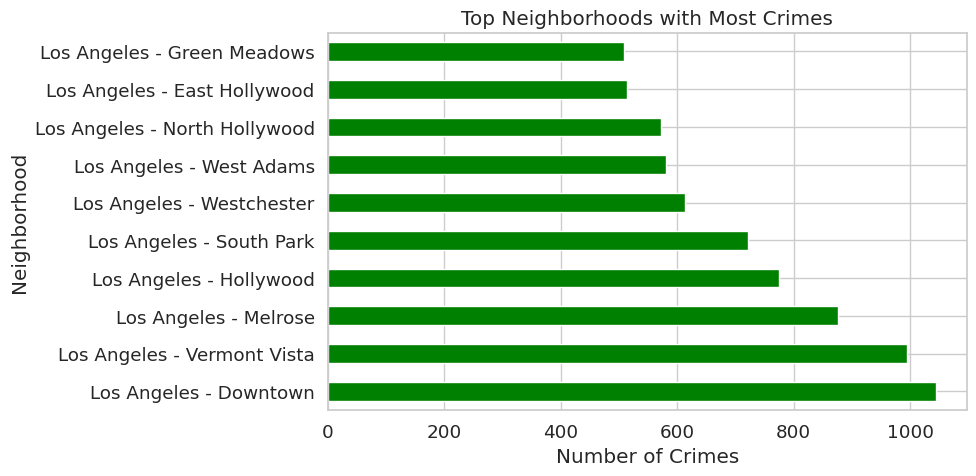

In [ ]:
top_nbhds = anomalous_data_original['nearest_neighborhood'].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_nbhds.plot(kind='barh', color='green')
plt.title('Top Neighborhoods with Most Crimes')
plt.xlabel('Number of Crimes')
plt.ylabel('Neighborhood')
plt.tight_layout()
plt.show()

In [ ]:
print(f"Total neighborhoods affected: {anomalous_data_original['nearest_neighborhood'].nunique()}")
print(f"Top neighborhood '{top_nbhds.index[0]}' had {top_nbhds.values[0]} crimes")
print(f"Top 3 neighborhoods accounted for {top_nbhds.head(3).sum()} crimes")


Total neighborhoods affected: 74
Top neighborhood 'Los Angeles - Downtown' had 1045 crimes
Top 3 neighborhoods accounted for 2916 crimes


**B. Motif Discovery**

In [ ]:
pip install stumpy

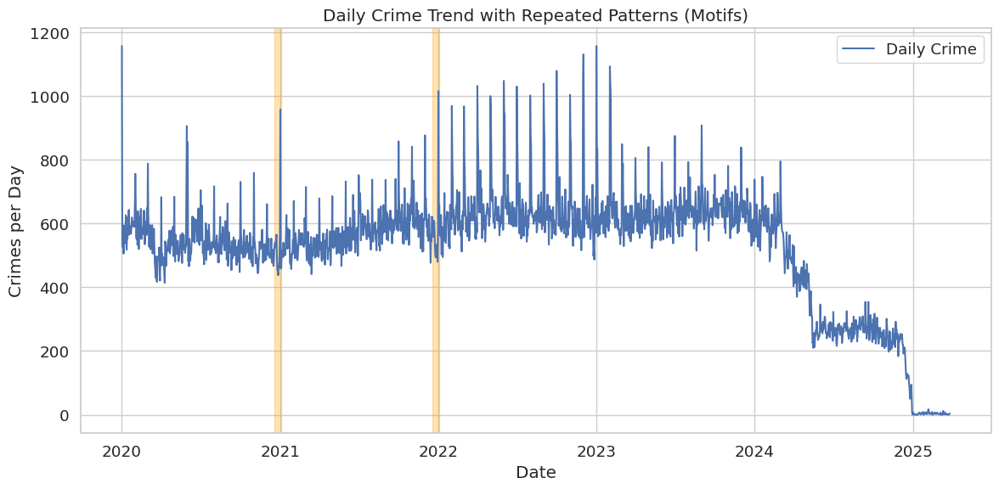

In [ ]:
import stumpy
import numpy as np


daily_crimes = data_pred_t.groupby(pd.Grouper(key='date occ', freq='D')).size().reset_index(name='crime_count')
daily_crimes = daily_crimes.set_index('date occ').asfreq('D').fillna(0).reset_index()
window_size = 14
mp = stumpy.stump(daily_crimes['crime_count'].astype(np.float64).values, m=window_size)


motif_idx = np.argsort(mp[:, 0])[:2]  # top 2 motifs
motif_dates = [daily_crimes['date occ'][i] for i in motif_idx]


plt.figure(figsize=(12, 6))
plt.plot(daily_crimes['date occ'], daily_crimes['crime_count'], label='Daily Crime')
for i in motif_idx:
    plt.axvspan(daily_crimes['date occ'][i], daily_crimes['date occ'][i + window_size], color='orange', alpha=0.3)
plt.title('Daily Crime Trend with Repeated Patterns (Motifs)')
plt.xlabel('Date')
plt.ylabel('Crimes per Day')
plt.legend()
plt.tight_layout()
plt.show()


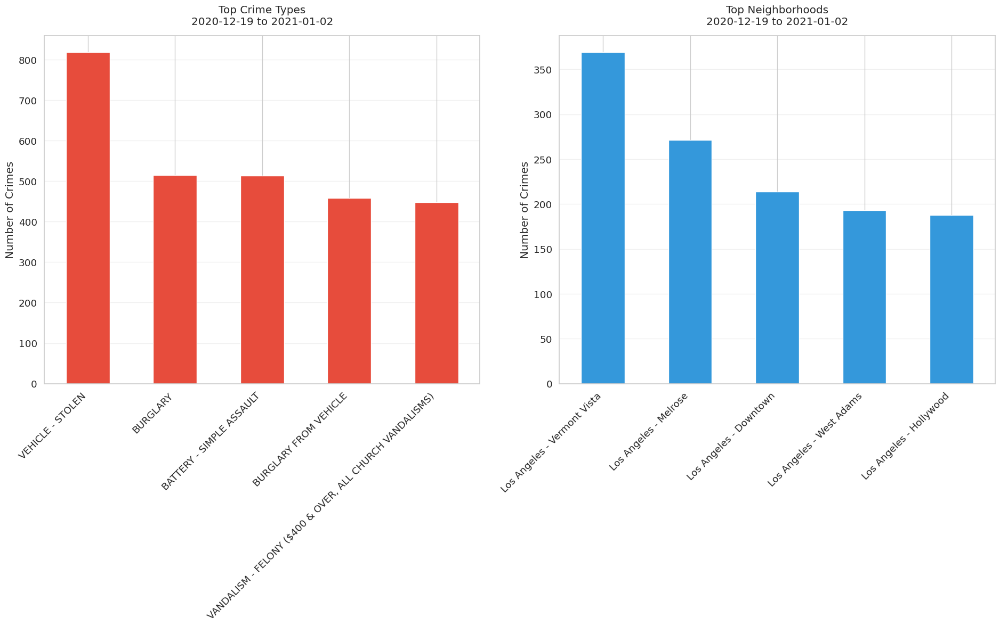

In [ ]:
motif_idx = np.argsort(mp[:, 0])[0]  # Only get the top motif
start_date = daily_crimes['date occ'][motif_idx]
end_date = daily_crimes['date occ'][motif_idx + window_size]

motif_data = data_cleaned[
    (data_cleaned['date occ'] >= start_date) &
    (data_cleaned['date occ'] < end_date)
]

top_crimes = motif_data['crm cd desc'].value_counts().head(5)
top_neighborhoods = motif_data['nearest_neighborhood'].value_counts().head(5)  # Changed to neighborhoods

plt.figure(figsize=(19, 12))

plt.subplot(1, 2, 1)
top_crimes.plot(kind='bar', color='#e74c3c')
plt.title(f'Top Crime Types\n{start_date.date()} to {end_date.date()}', pad=15)
plt.ylabel('Number of Crimes')
plt.xlabel('')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
top_neighborhoods.plot(kind='bar', color='#3498db')
plt.title(f'Top Neighborhoods\n{start_date.date()} to {end_date.date()}', pad=15)
plt.ylabel('Number of Crimes')
plt.xlabel('')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

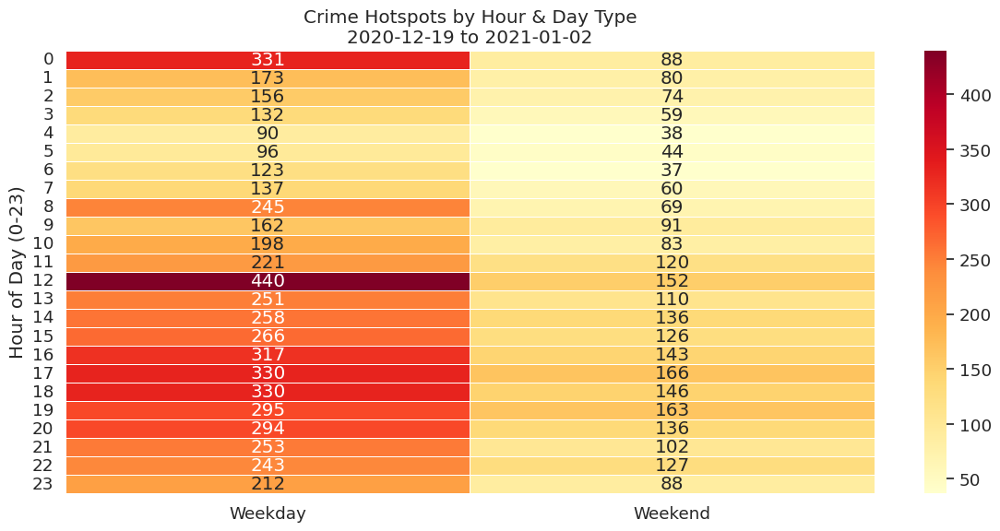

In [ ]:
motif_windows = [(start_date, end_date)]
# Prepare data for Motif 1
motif1_data = data_cleaned[
    (data_cleaned['date occ'] >= motif_windows[0][0]) &
    (data_cleaned['date occ'] <= motif_windows[0][1])
].copy()

# Convert numeric weekday_occ to actual weekday names
weekday_map = {
    0: 'Weekday',  # Assuming 0 represents weekdays (Mon-Fri)
    1: 'Weekend'   # Assuming 1 represents weekends (Sat-Sun)
}
motif1_data['weekday_name'] = motif1_data['weekday_occ'].map(weekday_map)

# Create pivot table
heatmap_data = motif1_data.pivot_table(
    index='hour_occ',
    columns='weekday_name',
    values='crm cd',
    aggfunc='count',
    fill_value=0
)

# Reorder columns logically
column_order = ['Weekday', 'Weekend'] if 'Weekend' in heatmap_data.columns else ['Weekday']
heatmap_data = heatmap_data[column_order]

# Plot
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    linewidths=0.5,
    annot=True,  # Show numbers in cells
    fmt='d'     # Format as integers
)
plt.title(f'Crime Hotspots by Hour & Day Type\n{motif_windows[0][0].date()} to {motif_windows[0][1].date()}')
plt.ylabel('Hour of Day (0-23)')
plt.xlabel('')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

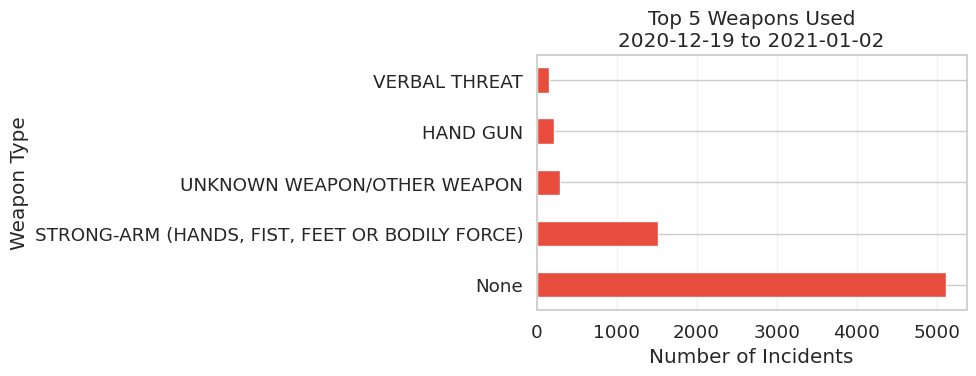

In [ ]:
motif_idx = np.argsort(mp[:, 0])[0]  # Only get the top motif
start_date = daily_crimes['date occ'][motif_idx]
end_date = daily_crimes['date occ'][motif_idx + window_size]

# Define motif_windows here based on start_date and end_date:
motif_windows = [(start_date, end_date)] # Create a list with the motif window

weapons_motif = data_cleaned[
    (data_cleaned['date occ'] >= motif_windows[0][0]) &
    (data_cleaned['date occ'] <= motif_windows[0][1])
]['weapon desc'].value_counts().head(5)

# Create single plot
plt.figure(figsize=(10, 4))
weapons_motif.plot(kind='barh', color='#e74c3c')

# Add annotations and formatting
plt.title(f'Top 5 Weapons Used\n{motif_windows[0][0].date()} to {motif_windows[0][1].date()}')
plt.xlabel('Number of Incidents')
plt.ylabel('Weapon Type')
plt.grid(axis='x', alpha=0.3)


plt.tight_layout()
plt.show()

<ipython-input-120-709618b96d0e>:12: UserWarning:

This axis already has a converter set and is updating to a potentially incompatible converter



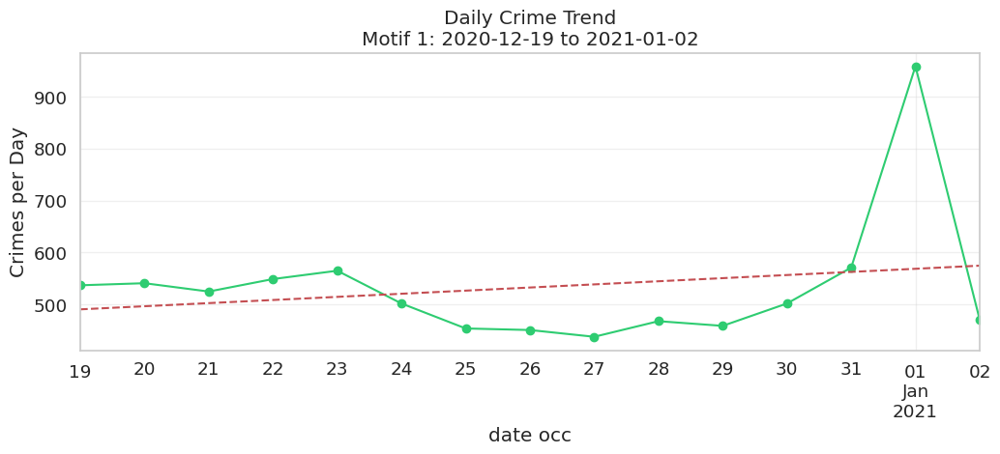

In [ ]:
# Daily crime counts for Motif 1
daily_counts = data_cleaned[
    (data_cleaned['date occ'] >= motif_windows[0][0]) &
    (data_cleaned['date occ'] <= motif_windows[0][1])
].groupby('date occ').size()

# Plot with trendline
plt.figure(figsize=(12, 4))
daily_counts.plot(marker='o', linestyle='-', color='#2ecc71')
z = np.polyfit(range(len(daily_counts)), daily_counts, 1)
p = np.poly1d(z)
plt.plot(daily_counts.index, p(range(len(daily_counts))), 'r--')
plt.title(f'Daily Crime Trend\nMotif 1: {motif_windows[0][0].date()} to {motif_windows[0][1].date()}')
plt.ylabel('Crimes per Day')
plt.grid(alpha=0.3)

**C. Seasonality Detection**

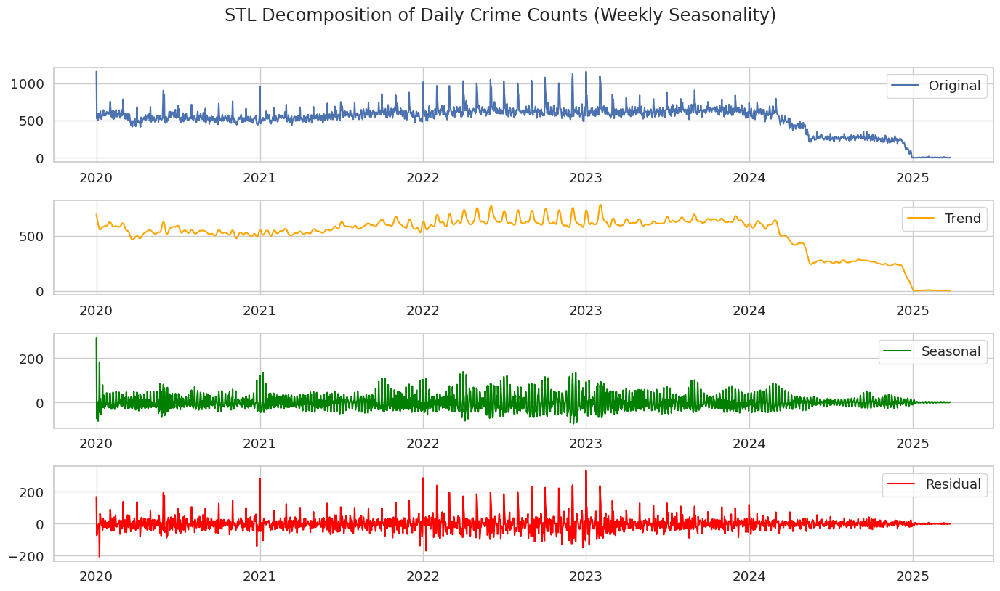

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.seasonal import STL

data_pred_t['date occ'] = pd.to_datetime(data_pred_t['date occ'])

daily_crimes = data_pred_t.groupby(pd.Grouper(key='date occ', freq='D')).size().reset_index(name='crime_count')

daily_crimes = daily_crimes.set_index('date occ').asfreq('D').fillna(0).reset_index()

stl = STL(daily_crimes['crime_count'], period=7)
result = stl.fit()

daily_crimes['trend'] = result.trend
daily_crimes['seasonal'] = result.seasonal
daily_crimes['residual'] = result.resid


plt.figure(figsize=(14, 8))

plt.subplot(4, 1, 1)
plt.plot(daily_crimes['date occ'], daily_crimes['crime_count'], label='Original')
plt.legend()

plt.subplot(4, 1, 2)
plt.plot(daily_crimes['date occ'], daily_crimes['trend'], color='orange', label='Trend')
plt.legend()

plt.subplot(4, 1, 3)
plt.plot(daily_crimes['date occ'], daily_crimes['seasonal'], color='green', label='Seasonal')
plt.legend()

plt.subplot(4, 1, 4)
plt.plot(daily_crimes['date occ'], daily_crimes['residual'], color='red', label='Residual')
plt.legend()

plt.suptitle('STL Decomposition of Daily Crime Counts (Weekly Seasonality)', y=1.02)
plt.tight_layout()
plt.show()

Average Seasonal Effect by Weekday:
weekday
Friday       36.601472
Saturday     14.087421
Wednesday    -3.784721
Monday       -6.513054
Thursday     -7.043166
Sunday      -14.052781
Tuesday     -18.742966
Name: seasonal, dtype: float64


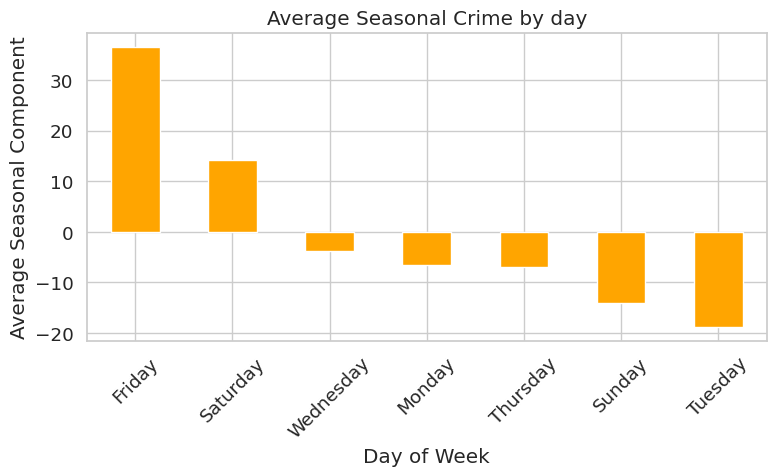

In [ ]:
from statsmodels.tsa.seasonal import STL
import pandas as pd
import matplotlib.pyplot as plt

seasonal = result.seasonal

daily_crimes['seasonal'] = seasonal
daily_crimes['weekday'] = daily_crimes['date occ'].dt.day_name()

weekday_seasonality = daily_crimes.groupby('weekday')['seasonal'].mean().sort_values(ascending=False)

print("Average Seasonal Effect by Weekday:")
print(weekday_seasonality)

plt.figure(figsize=(8, 5))
weekday_seasonality.plot(kind='bar', color='orange')
plt.title('Average Seasonal Crime by day')
plt.ylabel('Average Seasonal Component')
plt.xlabel('Day of Week')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
start_date = data_cleaned['date occ'].min()
seasonal.index = pd.date_range(start=start_date, periods=len(seasonal))

seasonal_peaks = seasonal[seasonal > seasonal.quantile(0.95)]
seasonal_valleys = seasonal[seasonal < seasonal.quantile(0.05)]

print("Top Seasonal Crime Peaks:")
for date, value in seasonal_peaks.head(10).items():
    print(f"{date.strftime('%Y-%m-%d')}: {value:.2f}")

print("\nTop Seasonal Valleys:")
for date, value in seasonal_valleys.head(10).items():
    print(f"{date.strftime('%Y-%m-%d')}: {value:.2f}")

Top Seasonal Crime Peaks:
2020-01-01: 293.33
2020-01-08: 182.88
2020-01-15: 78.79
2020-05-23: 86.25
2020-05-30: 81.26
2020-06-01: 65.73
2020-06-06: 63.39
2020-06-08: 67.50
2020-08-08: 70.88
2020-11-01: 58.93

Top Seasonal Valleys:
2020-01-02: -73.37
2020-01-04: -74.62
2020-01-05: -85.12
2020-01-09: -46.42
2020-01-12: -54.06
2020-05-19: -49.78
2020-05-26: -68.13
2020-05-28: -49.20
2020-06-02: -59.78
2021-01-03: -45.63


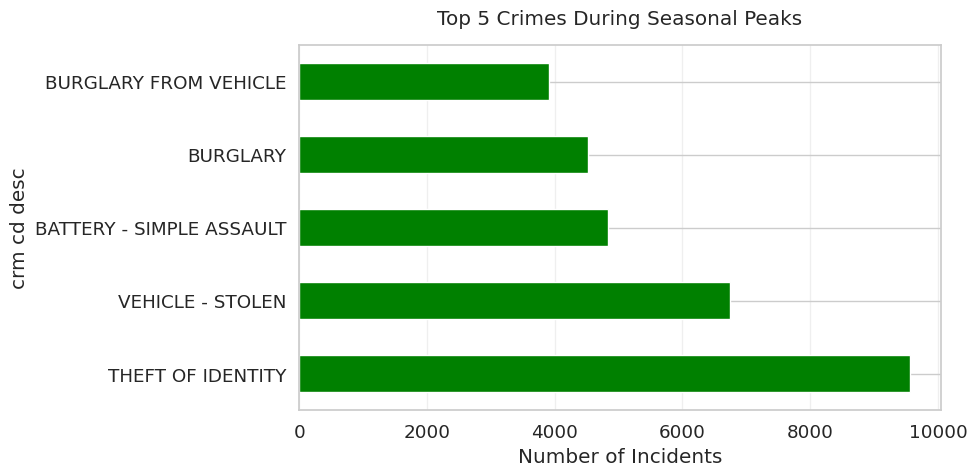

In [ ]:
# Top crimes during peaks - bar plot
plt.figure(figsize=(10,5))
peak_dates = seasonal_peaks.index
peak_crimes = data_cleaned[data_cleaned['date occ'].isin(peak_dates)]['crm cd desc'].value_counts()
peak_crimes.head(5).plot(kind='barh', color=['green'])

plt.title('Top 5 Crimes During Seasonal Peaks', pad=15)
plt.xlabel('Number of Incidents')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

In [ ]:
economic_cols = ['mhi', '100_fpl_pct', '200_fpl_pct', 'sevhouse_b', 'overcrowding', 'homeless']
crime_cols = ['crimes_m', 'overall_mr']

economic_crime_data = data_pred_t[economic_cols + crime_cols]

X = data_pred[economic_cols]
y = data_pred['crimes_m']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:               crimes_m   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.706
Method:                 Least Squares   F-statistic:                 4.019e+05
Date:                Sat, 17 May 2025   Prob (F-statistic):               0.00
Time:                        12:38:12   Log-Likelihood:             7.2134e+05
No. Observations:             1002705   AIC:                        -1.443e+06
Df Residuals:                 1002698   BIC:                        -1.443e+06
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3704      0.001    402.262   

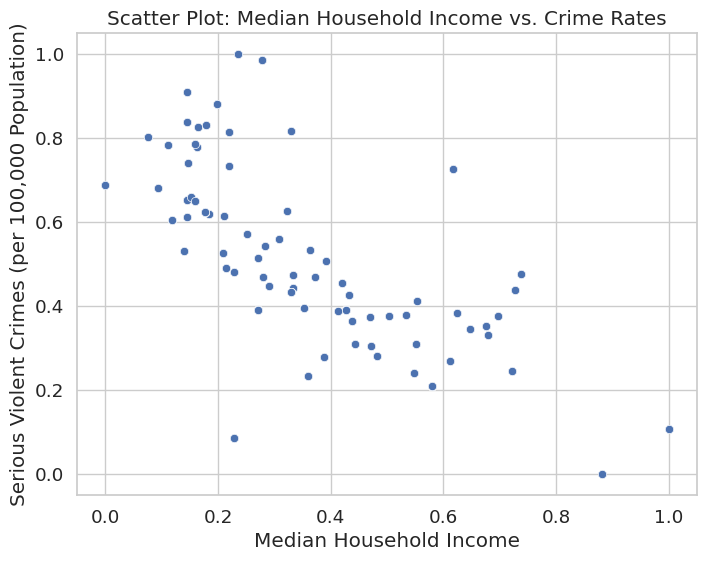

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='mhi', y='crimes_m', data=data_pred)
plt.title('Scatter Plot: Median Household Income vs. Crime Rates')
plt.xlabel('Median Household Income')
plt.ylabel('Serious Violent Crimes (per 100,000 Population)')
plt.show()

In [ ]:

demographic_cols = ['pop_race_ethnicity_pct_l', 'pop_race_ethnicity_pct_w', 'pop_race_ethnicity_pct_b',
                    'pop_race_ethnicity_pct_a', 'pop_race_ethnicity_pct_i', 'pop_race_ethnicity_pct_p']

demographic_crime_data = data_pred[demographic_cols + crime_cols]

demographic_corr_matrix = demographic_crime_data.corr()
X_demo = data_pred[demographic_cols]
y_demo = data_pred['crimes_m']

X_demo = sm.add_constant(X_demo)

model_demo = sm.OLS(y_demo, X_demo).fit()

print(model_demo.summary())

                            OLS Regression Results                            
Dep. Variable:               crimes_m   R-squared:                       0.456
Model:                            OLS   Adj. R-squared:                  0.456
Method:                 Least Squares   F-statistic:                 1.400e+05
Date:                Sat, 17 May 2025   Prob (F-statistic):               0.00
Time:                        12:38:30   Log-Likelihood:             4.1215e+05
No. Observations:             1002705   AIC:                        -8.243e+05
Df Residuals:                 1002698   BIC:                        -8.242e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

### **Classification**

####**A. Classify Severity of Crime**

In [ ]:
pip install lightgbm

In [ ]:
labels = data_pred['part 1-2'].value_counts()

print(labels)

# If you want to see just the number of unique labels
num_labels = len(data_pred['part 1-2'].unique())
print(f"Number of unique labels: {num_labels}")


part 1-2
0.0    602077
1.0    400628
Name: count, dtype: int64
Number of unique labels: 2


In [ ]:
y = data_pred['part 1-2']
x = data_pred.drop(columns=['part 1-2','date occ','crm cd','crm cd desc'])

In [ ]:
corr_with_target = x.corrwith(y).abs().sort_values(ascending=False)
print(corr_with_target.head(20))


/usr/local/lib/python3.11/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


weapon desc                 0.304757
weapon used cd              0.284247
vict sex                    0.257052
vict age                    0.206624
vict descent                0.180641
time_occ_sin                0.062864
time_occ_cos                0.060687
hour_occ                    0.058824
time occ                    0.056326
crime_codes                 0.056249
year_occ                    0.050469
day_occ                     0.043992
edu_hsgrad_pct              0.043359
alcohol_c                   0.038738
edu_bach_pct                0.036803
child_fi                    0.036226
pop_race_ethnicity_pct_w    0.033642
binge_drink                 0.033458
pop_fi                      0.033137
overall_mr                  0.033043
dtype: float64


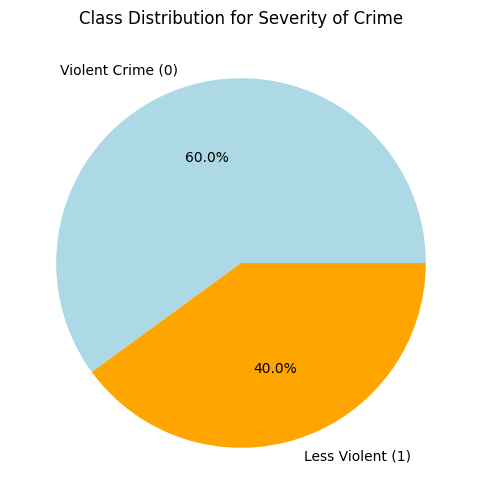

In [ ]:
classes = {0.0: 'Violent Crime (0)', 1.0: 'Less Violent (1)'}
mapped_labels = labels.index.map(classes)

plt.figure(figsize=(6, 6))
labels.plot(kind='pie', autopct='%1.1f%%', colors=['lightblue', 'orange'], labels=mapped_labels, legend=False)
plt.title('Class Distribution for Severity of Crime')
plt.ylabel('')
plt.show()


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

undersampler = RandomUnderSampler(sampling_strategy={0: len(y[y==1])}, random_state=42)
x_under, y_under = undersampler.fit_resample(x, y)

print(pd.Series(y_under).value_counts())

part 1-2
0.0    400628
1.0    400628
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_under, y_under, test_size=0.2, random_state=42)

params = {
    'max_depth': np.arange(2, 7),
    'learning_rate': [0.01,0.05, 0.1, 0.2],
    'min_child_samples': [20, 50, 100]
}

model = LGBMClassifier(
    n_estimators=70,
    class_weight='balanced',
    random_state=42
)

search = RandomizedSearchCV(
    model, params, n_iter=20,
    cv=3, scoring='f1', n_jobs=-1, verbose=1
)
search.fit(x_train, y_train)
print(search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 320563, number of negative: 320441
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.293282 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5412
[LightGBM] [Info] Number of data points in the train set: 641004, number of used features: 72
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

Best Parameters: {'min_child_samples': 100, 'max_depth': np.int64(5), 'learning_rate': 0.2}
Accuracy: 0.7490

Classification Report:
              precision    recall  f1-score   support

         0.0     0.7593    0.7296    0.7442     80187
         1.0     0.7394    0.7684    0.7536     80065

    accuracy                         0.7490    160252
   macro avg     0.7494    0.7490    0.7489    160252
weighted avg     0.7494    0.7490    0.7489    160252



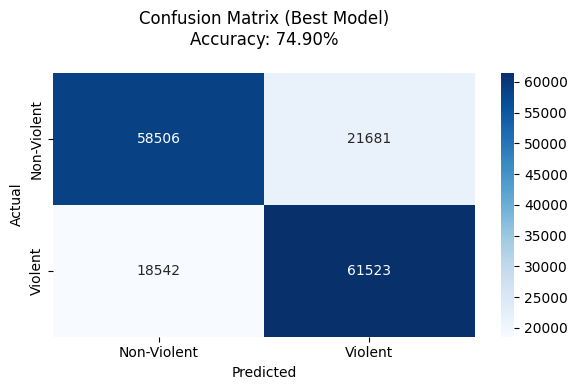

In [ ]:
best_model = search.best_estimator_
y_pred = best_model.predict(x_test)

print(f"Best Parameters: {search.best_params_}")


accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))  # 4 decimal precision

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Violent', 'Violent'],
    yticklabels=['Non-Violent', 'Violent']
)
plt.title(f"Confusion Matrix (Best Model)\nAccuracy: {accuracy:.2%}", pad=20)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

####**B. Hotspot Detection**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt

data_pred_h = data_pred.copy()

grid_size = 0.005  # degrees (~500m in latitude)
data_pred_h['lat_grid'] = (data_pred_h['lat'] // grid_size).astype(int)
data_pred_h['lon_grid'] = (data_pred_h['lon'] // grid_size).astype(int)

grid_counts = data_pred_h.groupby(['lat_grid', 'lon_grid']).size().reset_index(name='crime_count')

hotspot_threshold = grid_counts['crime_count'].quantile(0.9)
grid_counts['is_hotspot'] = (grid_counts['crime_count'] >= hotspot_threshold).astype(int)

data_pred_h = data_pred_h.merge(grid_counts[['lat_grid', 'lon_grid', 'is_hotspot']],
              on=['lat_grid', 'lon_grid'], how='left')

In [ ]:
from sklearn.neighbors import BallTree
import numpy as np

coords = np.radians(data_pred_h[['lat', 'lon']].values)
tree = BallTree(coords, metric='haversine')

distances, _ = tree.query(coords, k=5)
data_pred_h['avg_dist_5_nearest'] = distances.mean(axis=1) * 6371


In [ ]:
data_pred_h['date occ'] = pd.to_datetime(data_pred_h['date occ'])

data_pred_h = data_pred_h.sort_values(['area', 'date occ'])

rolling_data_pred = pd.DataFrame()

for area_name, area_group in data_pred_h.groupby('area'):
    area_group = area_group.sort_values('date occ')
    area_group['crime_count_7d'] = (
        area_group.rolling('7D', on='date occ')['crm cd']
        .count()
        .fillna(0)
    )
    rolling_data_pred = pd.concat([rolling_data_pred, area_group])
data_pred_h = rolling_data_pred

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from imblearn.over_sampling import RandomOverSampler
import joblib

target = 'is_hotspot'
X = data_pred_h.drop(columns=[target, 'date occ', 'date rptd'])
y = data_pred_h[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X_train, y_train)

model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_depth=12,
    min_samples_leaf=50,
    random_state=42,
    verbose=1
)
model.fit(X_res, y_res)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("\nROC AUC Score:", roc_auc_score(y_test, y_proba))


Binning 0.483 GB of training data: 7.493 s
Binning 0.054 GB of validation data: 0.704 s
Fitting gradient boosted rounds:
Fit 200 trees in 95.535 s, (6200 total leaves)
Time spent computing histograms: 69.247s
Time spent finding best splits:  0.751s
Time spent applying splits:      4.758s
Time spent predicting:           0.549s
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85    106167
           1       0.84      0.83      0.83     94374

    accuracy                           0.85    200541
   macro avg       0.85      0.84      0.84    200541
weighted avg       0.85      0.85      0.85    200541


ROC AUC Score: 0.9321592410657428


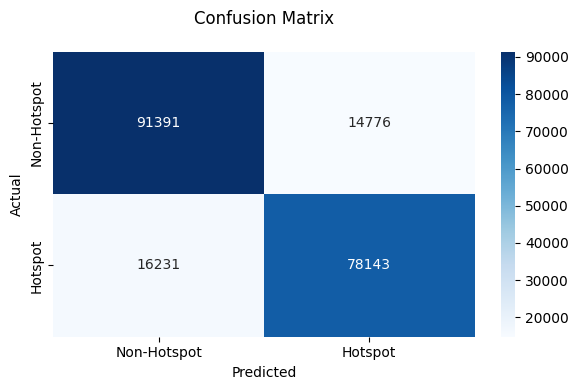

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Hotspot', 'Hotspot'], yticklabels=['Non-Hotspot', 'Hotspot'])
plt.title('Confusion Matrix', pad=20)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

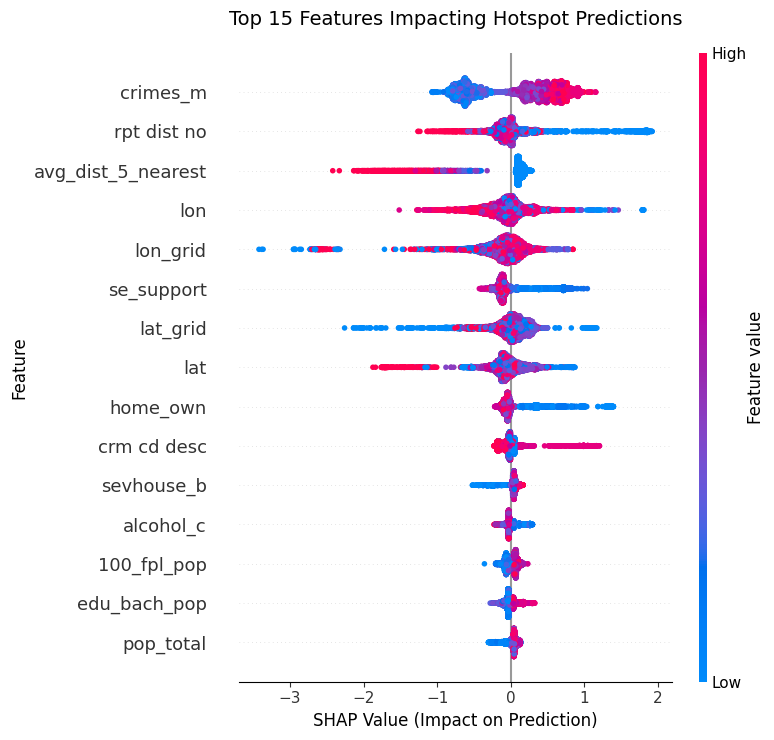

In [ ]:
import matplotlib.pyplot as plt
import shap

X_test_sampled = X_test.sample(n=10000, random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_sampled)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_test_sampled,
    plot_type="dot",
    max_display=15,
    show=False
)
plt.title("Top 15 Features Impacting Hotspot Predictions", fontsize=14, pad=20)
plt.xlabel("SHAP Value (Impact on Prediction)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

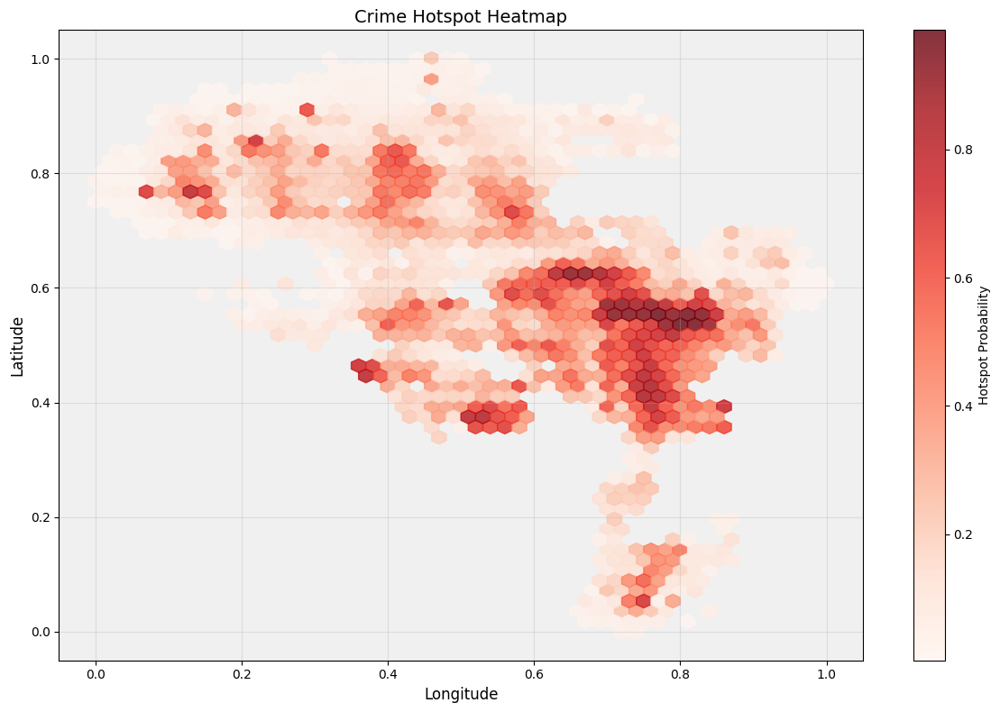

Predicted 1002705 locations
Hotspot threshold (P80): 0.935
Identified 100271 hotspot locations


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

visualization_data = data_pred_h.copy()
X_viz = visualization_data[X_res.columns]

visualization_data['hotspot_prob'] = model.predict_proba(X_viz)[:, 1]

lat = visualization_data['lat'].values
lon = visualization_data['lon'].values
prob = visualization_data['hotspot_prob'].values

plt.figure(figsize=(12, 8))
hb = plt.hexbin(lon, lat, C=prob, gridsize=50, cmap='Reds',  reduce_C_function=np.mean, alpha=0.8)
cb = plt.colorbar(hb, label='Hotspot Probability')
plt.title('Crime Hotspot Heatmap', fontsize=14)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(visible=True, alpha=0.3)
plt.gca().set_facecolor('#f0f0f0')
plt.tight_layout()
plt.show()

hotspot_threshold = visualization_data['hotspot_prob'].quantile(0.9)
hotspots = visualization_data[visualization_data['hotspot_prob'] >= hotspot_threshold]


print(f"Predicted {len(visualization_data)} locations")
print(f"Hotspot threshold (P80): {hotspot_threshold:.3f}")
print(f"Identified {len(hotspots)} hotspot locations")


###**Association Rule Mining**

In [ ]:
def age_group_custom(age):
    if age < 4:
        return 'Unknown'
    elif age <= 12:
        return 'Kid'
    elif age <= 17:
        return 'Teenager'
    elif age <= 64:
        return 'Adult'
    else:
        return 'Elderly'

data_cleaned['Vict_Age_Group_Custom'] = data_cleaned['Vict Age'].apply(age_group_custom)

def clean_vict_sex(sex):
    if sex in ['F', 'M']:
        return sex
    else:
        return 'Other/Unknown'

data_cleaned['Vict_Sex_Clean'] = data_cleaned['Vict Sex'].apply(clean_vict_sex)

In [ ]:
# Select relevant columns
# Select relevant columns
victim_data = data_cleaned[['Crm Cd', 'Vict Descent', 'Vict Sex', 'AREA NAME']].astype(str)

# Drop rows with missing values
victim_data = victim_data.dropna()

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
print("\n=== Crime Pattern Analysis ===")


available_columns = set(data_cleaned.columns)
crime_pattern_cols = ['Crm Cd Desc', 'Weapon Desc', 'Premis Desc', 'Vict Sex','Vict_Sex_Clean']#'Vict_Age_Group'


selected_cols = [col for col in crime_pattern_cols if col in available_columns]

if not selected_cols:
    raise ValueError("None of the required columns for crime pattern analysis exist in the data")

print(f"Using columns: {selected_cols}")


crime_pattern_data = data_cleaned[selected_cols].copy()


=== Crime Pattern Analysis ===
Using columns: ['Crm Cd Desc', 'Weapon Desc', 'Vict Sex', 'Vict_Sex_Clean']


In [ ]:
transactions = []
for _, row in crime_pattern_data.iterrows():
    transaction = []
    for col in crime_pattern_data.columns:
        if pd.notna(row[col]):

            if col == 'Vict_Sex_Clean' and 'Vict_Sex_Clean' not in available_columns:

                age = row['Vict Age'] if 'Vict Age' in available_columns else None
                if age is not None:
                    if age <= 17:
                        transaction.append("Vict_Sex_Clean=Child")
                    elif age <= 64:
                        transaction.append("Vict_Sex_Clean=Adult")
                    else:
                        transaction.append("Vict_Sex_Clean=Elderly")
            else:
                transaction.append(f"{col}={row[col]}")
    transactions.append(transaction)


te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
crime_df = pd.DataFrame(te_ary, columns=te.columns_)

In [ ]:
if len(te.columns_) > 1:
    frequent_itemsets_apriori = apriori(crime_df, min_support=0.01, use_colnames=True)
    if not frequent_itemsets_apriori.empty:
        rules_apriori = association_rules(frequent_itemsets_apriori, metric="lift", min_threshold=1.0)
        print("\nTop Apriori Rules:")







Top Apriori Rules:


In [ ]:
print(rules_apriori.sort_values('lift', ascending=False).head(10))

                                           antecedents  \
786            (Vict Sex=F, Weapon Desc=VERBAL THREAT)   
784      (Vict_Sex_Clean=F, Weapon Desc=VERBAL THREAT)   
783  (Vict_Sex_Clean=F, Crm Cd Desc=CRIMINAL THREAT...   
785  (Vict Sex=F, Crm Cd Desc=CRIMINAL THREATS - NO...   
790  (Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISP...   
779  (Vict_Sex_Clean=F, Vict Sex=F, Weapon Desc=VER...   
313            (Vict Sex=F, Weapon Desc=VERBAL THREAT)   
316  (Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISP...   
325      (Vict_Sex_Clean=F, Weapon Desc=VERBAL THREAT)   
328  (Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISP...   

                                           consequents  antecedent support  \
786  (Vict_Sex_Clean=F, Crm Cd Desc=CRIMINAL THREAT...            0.012779   
784  (Vict Sex=F, Crm Cd Desc=CRIMINAL THREATS - NO...            0.012779   
783            (Vict Sex=F, Weapon Desc=VERBAL THREAT)            0.011973   
785      (Vict_Sex_Clean=F, Weapon Desc=VERBAL TH

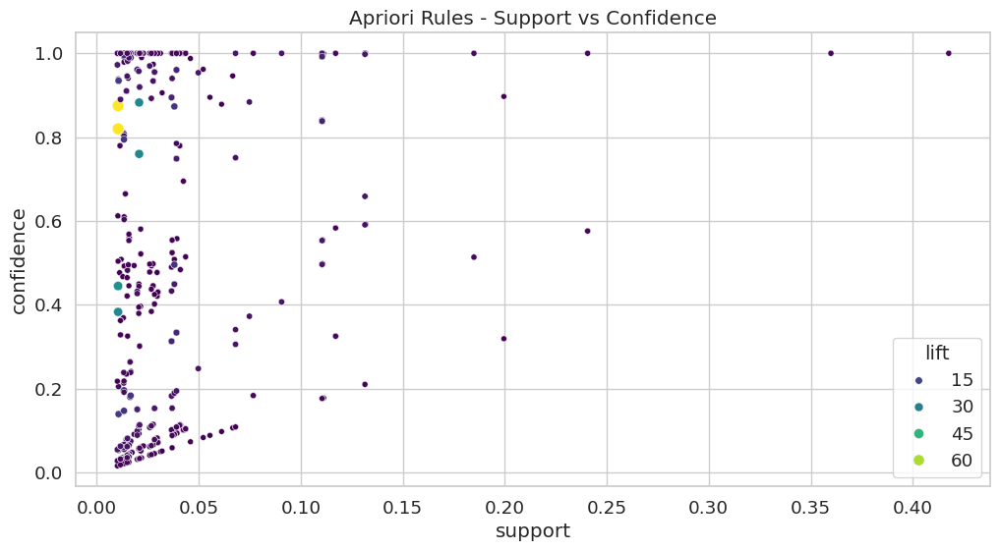

In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=rules_apriori, x='support', y='confidence', size='lift', hue='lift', palette='viridis')
plt.title("Apriori Rules - Support vs Confidence")
plt.show()

In [ ]:
print("\n=== Victim-Offender Behavior Analysis ===")

behavior_cols = ['Mocodes', 'Crm Cd', 'Status', 'Vict Descent']
selected_behavior_cols = [col for col in behavior_cols if col in available_columns]

if not selected_behavior_cols:
    raise ValueError("None of the required columns for behavior analysis exist in the data")

print(f"Using columns: {selected_behavior_cols}")


behavior_data = data_cleaned[selected_behavior_cols].copy()


if 'Mocodes' in behavior_data.columns:
    behavior_data['Mocodes'] = behavior_data['Mocodes'].fillna('').str.split(',')


=== Victim-Offender Behavior Analysis ===
Using columns: ['Crm Cd', 'Vict Descent']


In [ ]:
if 'behavior_df' in locals():
    frequent_itemsets_behavior = apriori(behavior_df, min_support=0.01, use_colnames=True)

    if not frequent_itemsets_behavior.empty:
        rules_behavior = association_rules(frequent_itemsets_behavior, metric="lift", min_threshold=1.0)
        print("\nTop Victim-Offender Behavior Rules:")
        print(rules_behavior.sort_values('lift', ascending=False).head(10))


    else:
        print("No frequent itemsets found for behavior analysis")
else:
    print("No valid transactions found for behavior analysis")


Top Victim-Offender Behavior Rules:
               antecedents             consequents  antecedent support  \
23  (Vict Descent=Unknown)            (Crm Cd=510)            0.131821   
22            (Crm Cd=510)  (Vict Descent=Unknown)            0.111329   
21        (Vict Descent=X)            (Crm Cd=442)            0.097168   
20            (Crm Cd=442)        (Vict Descent=X)            0.016406   
16            (Crm Cd=420)  (Vict Descent=Unknown)            0.046512   
17  (Vict Descent=Unknown)            (Crm Cd=420)            0.131821   
9         (Vict Descent=X)            (Crm Cd=310)            0.097168   
8             (Crm Cd=310)        (Vict Descent=X)            0.061996   
33        (Vict Descent=X)            (Crm Cd=740)            0.097168   
32            (Crm Cd=740)        (Vict Descent=X)            0.069652   

    consequent support   support  confidence      lift  representativity  \
23            0.111329  0.110523    0.838428  7.531112               1.0

In [ ]:
def explain_rules(rules, title):
    if not rules.empty:
        print(f"\nInterpretation of {title} Rules:")
        for _, rule in rules.head(3).iterrows():
            antecedents = ", ".join(list(rule['antecedents']))
            consequents = ", ".join(list(rule['consequents']))
            print(f"\nRule: IF {antecedents} THEN {consequents}")
            print(f"Support: {rule['support']:.3f} (frequency)")
            print(f"Confidence: {rule['confidence']:.3f} (probability)")
            print(f"Lift: {rule['lift']:.3f} (strength of association)")
            print("This suggests these items co-occur more often than expected by chance.")

if 'rules_apriori' in locals() and not rules_apriori.empty:
    explain_rules(rules_apriori.sort_values('lift', ascending=False), "Crime Pattern")

if 'rules_behavior' in locals() and not rules_behavior.empty:
    explain_rules(rules_behavior.sort_values('lift', ascending=False), "Victim-Offender Behavior")


Interpretation of Crime Pattern Rules:

Rule: IF Vict Sex=F, Weapon Desc=VERBAL THREAT THEN Vict_Sex_Clean=F, Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISPLAYED
Support: 0.010 (frequency)
Confidence: 0.820 (probability)
Lift: 68.471 (strength of association)
This suggests these items co-occur more often than expected by chance.

Rule: IF Vict_Sex_Clean=F, Weapon Desc=VERBAL THREAT THEN Vict Sex=F, Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISPLAYED
Support: 0.010 (frequency)
Confidence: 0.820 (probability)
Lift: 68.471 (strength of association)
This suggests these items co-occur more often than expected by chance.

Rule: IF Vict_Sex_Clean=F, Crm Cd Desc=CRIMINAL THREATS - NO WEAPON DISPLAYED THEN Vict Sex=F, Weapon Desc=VERBAL THREAT
Support: 0.010 (frequency)
Confidence: 0.875 (probability)
Lift: 68.471 (strength of association)
This suggests these items co-occur more often than expected by chance.

Interpretation of Victim-Offender Behavior Rules:

Rule: IF Vict Descent=Unknown THEN 

In [ ]:
import plotly.express as px

# Prepare data for sunburst (example for top rules)
sunburst_data = rules_apriori.sort_values('lift', ascending=False).head(20).copy()
sunburst_data['path'] = sunburst_data.apply(
    lambda x: f"{x['antecedents']}→{x['consequents']}", axis=1
)

fig = px.sunburst(
    sunburst_data,
    path=['antecedents', 'consequents'],
    values='support',
    color='lift',
    color_continuous_scale='thermal',
    title="Crime Pattern Hierarchy (Antecedents → Consequents)"
)
fig.update_traces(textinfo="label+percent parent")
fig.show()

**Parallel Categories Diagram**

In [ ]:
# Get the top crime pattern
top_pattern = rules_apriori.iloc[0]
antecedent_cols = list(top_pattern['antecedents'])
consequent_cols = list(top_pattern['consequents'])

# Filter original data for cases matching this pattern
pattern_mask = None
for col_val in antecedent_cols:
    col, val = col_val.split('=')
    if pattern_mask is None:
        pattern_mask = (data_cleaned[col] == val)
    else:
        pattern_mask &= (data_cleaned[col] == val)

parallel_data = data_cleaned[pattern_mask][['Crm Cd Desc', 'Weapon Desc', 'Vict Sex', 'Vict_Sex_Clean']]

fig = px.parallel_categories(
    parallel_data,
    dimensions=['Crm Cd Desc', 'Weapon Desc', 'Vict Sex', 'Vict_Sex_Clean'],
    title=f"Cases Matching: {', '.join(antecedent_cols)} → {', '.join(consequent_cols)}"
)
fig.show()

**Temporal Heatmap**

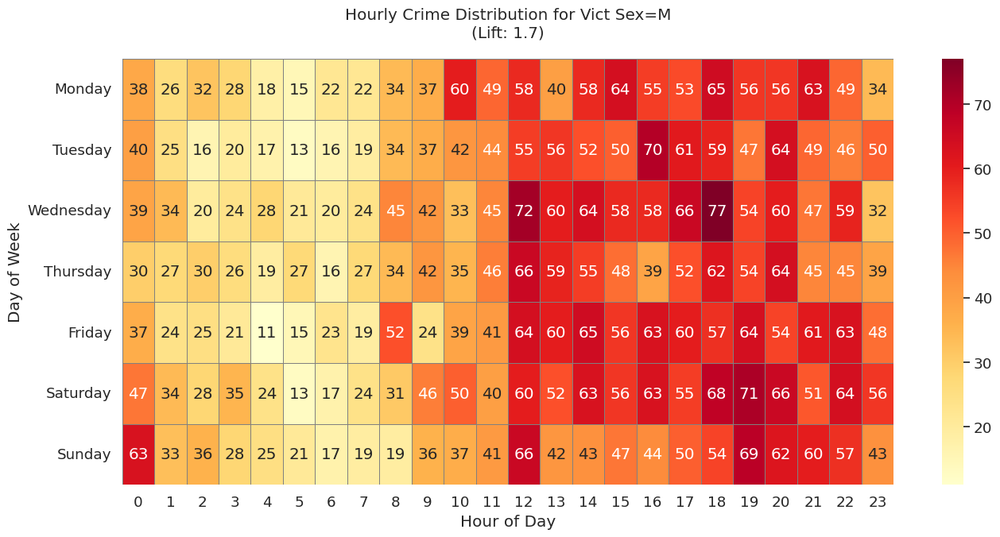

In [ ]:
# Get top consequent
top_consequent = list(rules_apriori.iloc[0]['consequents'])[0]
col, val = top_consequent.split('=')

# Filter data for this crime type
high_lift_crimes = data_cleaned[data_cleaned[col] == val].copy()

# Handle TIME OCC conversion - works with both full timestamps and hour-only values
def parse_hour(time_val):
    try:
        # If it's already just hours (like "20")
        if isinstance(time_val, (int, float)) or (isinstance(time_val, str) and len(time_val) <= 2):
            return int(float(time_val))
        # If it's in HH:MM:SS format
        elif ':' in str(time_val):
            return pd.to_datetime(time_val, format='%H:%M:%S').hour
        else:
            # Handle 4-digit times (like "2015" meaning 20:15)
            time_str = str(int(time_val)).zfill(4)
            return int(time_str[:2])
    except:
        return None  # or np.nan

high_lift_crimes['Hour'] = high_lift_crimes['TIME OCC'].apply(parse_hour)
high_lift_crimes['Day'] = high_lift_crimes['DATE OCC'].dt.day_name()

# Create heatmap with proper ordering
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hours_order = list(range(24))

heatmap_data = high_lift_crimes.groupby(['Day', 'Hour']).size().unstack()
heatmap_data = heatmap_data.reindex(index=days_order, columns=hours_order)

plt.figure(figsize=(14, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    annot=True,
    fmt='d',
    linewidths=0.5,
    linecolor='gray'
)
plt.title(f"Hourly Crime Distribution for {top_consequent}\n(Lift: {rules_apriori.iloc[0]['lift']:.1f})", pad=20)
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

**Network Graph of Victim-Offender Rules**

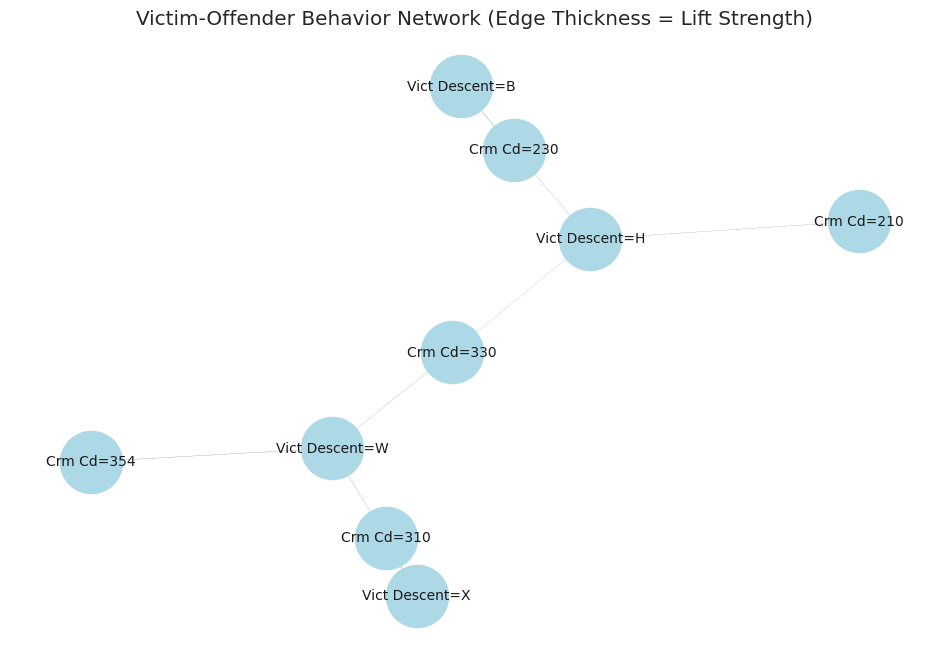

In [ ]:
import networkx as nx

# Prepare graph data
G = nx.Graph()
for _, rule in rules_behavior.head(15).iterrows():
    G.add_edge(
        str(list(rule['antecedents'])[0]),
        str(list(rule['consequents'])[0]),
        weight=rule['lift']
    )

# Draw graph
plt.figure(figsize=(12,8))
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='lightblue')
nx.draw_networkx_edges(
    G, pos,
    width=[d['weight']*0.1 for (_,_,d) in G.edges(data=True)],
    edge_color='gray'
)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Victim-Offender Behavior Network (Edge Thickness = Lift Strength)")
plt.axis('off')
plt.show()

#**Predection** ⚓

Feature Importance from XGBoost :


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np # Import numpy

# Ensure 'crm cd' is numeric
data_pred['crm cd'] = pd.to_numeric(data_pred['crm cd'], errors='coerce')

# Drop missing values in the target column
data_pred = data_pred.dropna(subset=['crm cd'])

# Define features and target
X = data_pred.drop(columns=['crm cd', 'crm cd desc', 'date occ', 'date rptd'], errors='ignore')
y = data_pred['crm cd']
X = X.fillna(X.mean())
print("Number of missing values in X after imputation:")
print(X.isnull().sum().sum())
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Number of missing values in X after imputation:
0


In [ ]:
# Initialize models
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name}")
    print(f"  R^2 Score: {r2_score(y_test, y_pred):.4f}")
    # Calculate RMSE by taking the square root of the MSE
    print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")


LinearRegression
  R^2 Score: 0.5894
  RMSE: 0.1573

Ridge
  R^2 Score: 0.5897
  RMSE: 0.1573

Lasso
  R^2 Score: 0.5500
  RMSE: 0.1647

RandomForest
  R^2 Score: 0.6685
  RMSE: 0.1413

XGBoost
  R^2 Score: 0.6834
  RMSE: 0.1381


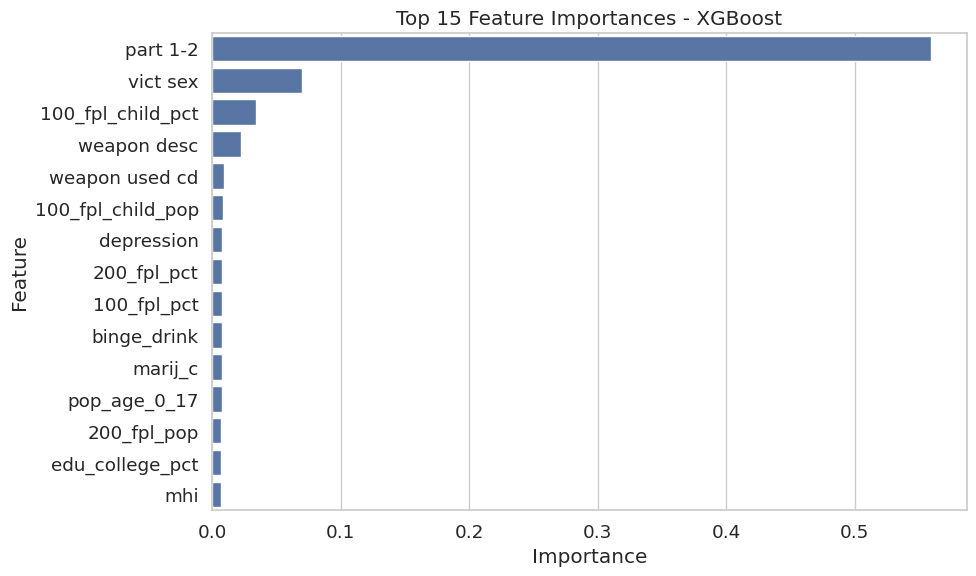

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

xgb_model = models['XGBoost']
importances = xgb_model.feature_importances_
features = X.columns

importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature')
plt.title("Top 15 Feature Importances - XGBoost")
plt.tight_layout()
plt.show()


Residual Plot (for error analysis):

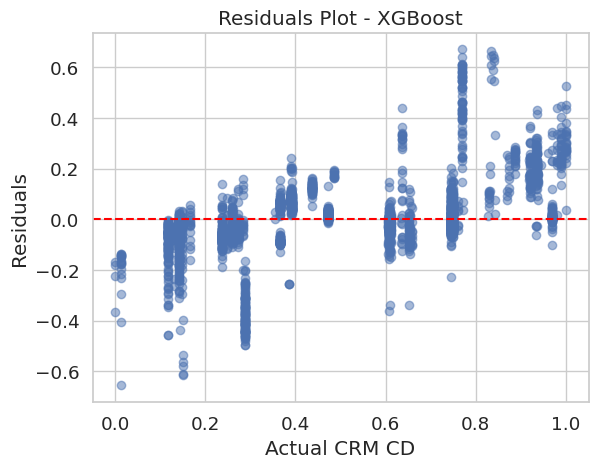

In [ ]:
import matplotlib.pyplot as plt

residuals = y_test - models['XGBoost'].predict(X_test)
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Actual CRM CD")
plt.ylabel("Residuals")
plt.title("Residuals Plot - XGBoost")
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import shap
import matplotlib.pyplot as plt

# Ensure 'crm cd' is numeric
data_pred['crm cd'] = pd.to_numeric(data_pred['crm cd'], errors='coerce')
data_pred = data_pred.dropna(subset=['crm cd'])

# Define features and target
X = data_pred.drop(columns=['crm cd', 'crm cd desc', 'date occ', 'date rptd'], errors='ignore')
y = data_pred['crm cd']
X = X.fillna(X.mean())

print("Number of missing values in X after imputation:")
print(X.isnull().sum().sum())

# --- Original Models ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name}")
    print(f"  R^2 Score: {r2_score(y_test, y_pred):.4f}")
    print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

# --- Leakage Test (remove 'part 1-2') ---
if 'part 1-2' in X.columns:
    print("\n Re-training without 'part 1-2' for leakage test...")
    X_no_leak = X.drop(columns=['part 1-2'], errors='ignore')
    X_train_nl, X_test_nl, y_train_nl, y_test_nl = train_test_split(X_no_leak, y, test_size=0.2, random_state=42)

    xgb_noleak = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    xgb_noleak.fit(X_train_nl, y_train_nl)
    y_pred_nl = xgb_noleak.predict(X_test_nl)

    print("\nXGBoost (No 'part 1-2'):")
    print(f"  R^2 Score: {r2_score(y_test_nl, y_pred_nl):.4f}")
    print(f"  RMSE: {np.sqrt(mean_squared_error(y_test_nl, y_pred_nl)):.4f}")
else:
    print("⚠️ 'part 1-2' not found in features. Skipping leakage test.")


Number of missing values in X after imputation:
0

LinearRegression
  R^2 Score: 0.5894
  RMSE: 0.1573

Ridge
  R^2 Score: 0.5897
  RMSE: 0.1573

Lasso
  R^2 Score: 0.5500
  RMSE: 0.1647

RandomForest
  R^2 Score: 0.6685
  RMSE: 0.1413

XGBoost
  R^2 Score: 0.6834
  RMSE: 0.1381

 Re-training without 'part 1-2' for leakage test...

XGBoost (No 'part 1-2'):
  R^2 Score: 0.1528
  RMSE: 0.2260



bar chart summary instead of beeswarm


 Generating SHAP summary plot (XGBoost without 'part 1-2')...


 97%|=================== | 3357/3475 [00:17<00:00]       

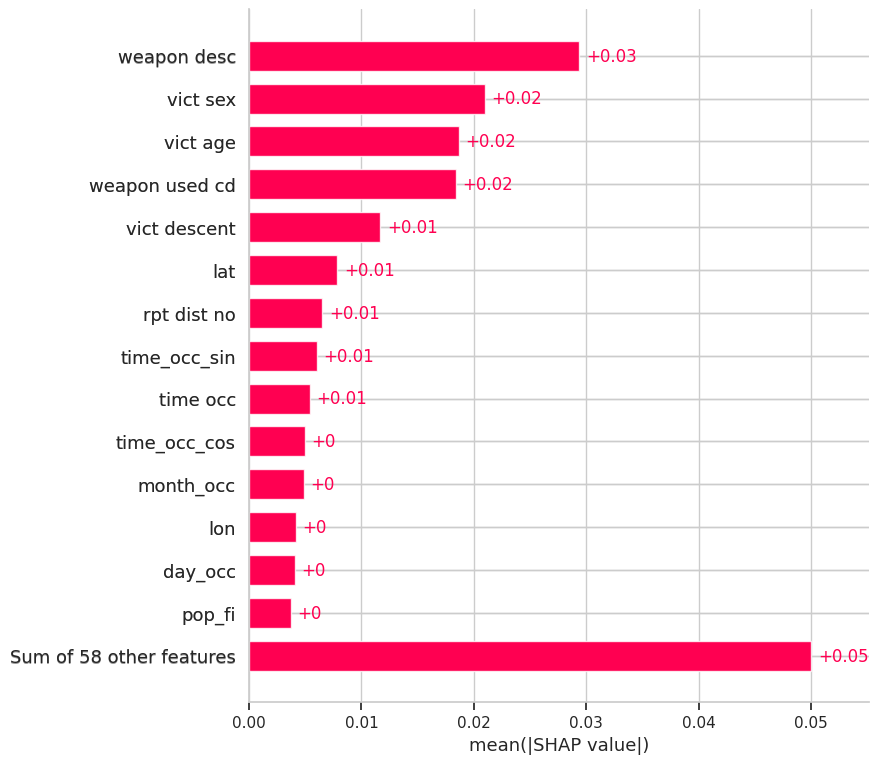

In [ ]:
    import shap
    import matplotlib.pyplot as plt
    print("\n Generating SHAP summary plot (XGBoost without 'part 1-2')...")
    explainer = shap.Explainer(xgb_noleak, X_test_nl)
    shap_values = explainer(X_test_nl)



    # Summary bar plot
    shap.plots.bar(shap_values, max_display=15)


Top 20 SHAP Features

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
import shap
import matplotlib.pyplot as plt

top_20_features = [
    'weapon desc', 'vict sex', 'vict age', 'weapon used cd', 'vict descent',
    'lat', 'rpt dist no', 'time_occ_sin', 'time occ', 'time_occ_cos',
    'month_occ', 'lon', 'day_occ', 'pop_fi', 'marij_c', 'crime_codes',
    'depression', 'pop_race_ethnicity_pct_b', 'pop_total', 'edu_hsgrad_pop'
]

X_top20 = X_no_leak[top_20_features]
X_train_top20, X_test_top20, y_train_top20, y_test_top20 = train_test_split(
    X_top20, y, test_size=0.2, random_state=42
)

# Retrain basic model
xgb_top20 = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_top20.fit(X_train_top20, y_train_top20)
y_pred_top20 = xgb_top20.predict(X_test_top20)

print("\n XGBoost with Top 20 SHAP Features:")
print(f"  R^2 Score: {r2_score(y_test_top20, y_pred_top20):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test_top20, y_pred_top20)):.4f}")






 XGBoost with Top 20 SHAP Features:
  R^2 Score: 0.1555
  RMSE: 0.2256


Hyperparameter Tuning

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 5, 10]
}

xgb_random = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_distributions=param_grid,
    n_iter=20,
    scoring='r2',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

xgb_random.fit(X_train_top20, y_train_top20)
best_model = xgb_random.best_estimator_
y_best_pred = best_model.predict(X_test_top20)

print("\n XGBoost with Hyperparameter Tuning (Top 20 Features):")
print(f"  Best Params: {xgb_random.best_params_}")
print(f"  R^2 Score: {r2_score(y_test_top20, y_best_pred):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test_top20, y_best_pred)):.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits

 XGBoost with Hyperparameter Tuning (Top 20 Features):
  Best Params: {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
  R^2 Score: 0.1605
  RMSE: 0.2249


 97%|=================== | 3359/3475 [00:19<00:00]       <ipython-input-199-a715a81f2328>:30: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




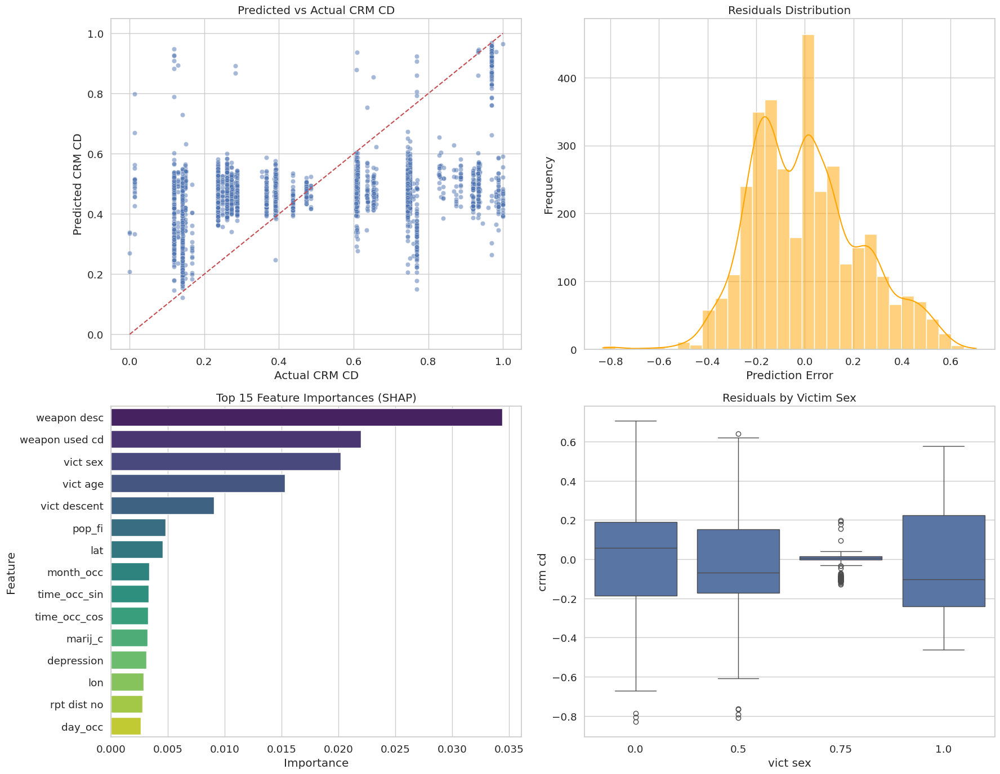

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import shap

plt.figure(figsize=(18, 14))

plt.subplot(2, 2, 1)
sns.scatterplot(x=y_test_top20, y=y_best_pred, alpha=0.5)
plt.plot([y_test_top20.min(), y_test_top20.max()], [y_test_top20.min(), y_test_top20.max()], 'r--')
plt.title("Predicted vs Actual CRM CD")
plt.xlabel("Actual CRM CD")
plt.ylabel("Predicted CRM CD")

plt.subplot(2, 2, 2)
residuals = y_test_top20 - y_best_pred
sns.histplot(residuals, kde=True, bins=30, color='orange')
plt.title("Residuals Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.subplot(2, 2, 3)
explainer = shap.Explainer(best_model, X_test_top20)
shap_values = explainer(X_test_top20)
importances = np.abs(shap_values.values).mean(axis=0)
top_features_df = pd.DataFrame({
    'Feature': X_test_top20.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

sns.barplot(data=top_features_df, x='Importance', y='Feature', palette='viridis')
plt.title("Top 15 Feature Importances (SHAP)")

plt.subplot(2, 2, 4)
sns.boxplot(x='vict sex', y=residuals, data=X_test_top20.assign(residual=residuals))
plt.title("Residuals by Victim Sex")

plt.tight_layout()
plt.show()


In [ ]:
import joblib
joblib.dump(best_model, 'xgboost_crmcd_model.pkl')


['xgboost_crmcd_model.pkl']